# Giai đoạn 2: Chọn Tập Đại diện & Khám phá Từng Doanh nghiệp (Hồi 2 — Bằng chứng vi mô)

## 00. Giới thiệu giai đoạn

- **Tên giai đoạn:** Giai đoạn 2 — Chọn tập đại diện & Khám phá từng doanh nghiệp (`02_business_eda.ipynb`).
- **Vai trò trong câu chuyện dữ liệu (Hồi 2 — *Bằng chứng vi mô*):** Từ bức tranh tổng thể 14 doanh nghiệp ở Hồi 1, lựa chọn các doanh nghiệp tiêu biểu (phủ các nhóm ngành và mức độ số hóa), làm sạch theo `rulebook.md` và Tidy Data, kiểm tra chất lượng & ngoại lệ IQR, rồi đi sâu khám phá mẫu hình vận hành nội tại của từng doanh nghiệp.
- **Mục tiêu:**
  1. Lựa chọn tập doanh nghiệp đại diện trong 14 doanh nghiệp `public_test` với tiêu chí rõ ràng, có căn cứ.
  2. Triển khai bộ hàm xử lý và tính chỉ số tuân thủ tuyệt đối [`data/public_test/rulebook.md`](../data/public_test/rulebook.md) (loại đơn hủy/trả — kể cả trả một phần, quy theo ngày đặt, doanh thu dòng hàng, quy đổi đơn vị cơ bản, giải mã `Ghi tắt`, chuẩn Tidy Data).
  3. Kiểm tra chất lượng dữ liệu (giá trị thiếu, trùng lặp, tính hợp lệ, ngoại lệ theo quy tắc IQR đối chiếu với dữ liệu gốc).
  4. Khám phá và tinh chỉnh 1–2 biểu đồ Giải thích đắt giá cho mỗi doanh nghiệp đại diện (Hồi 2).
- **Phạm vi dữ liệu:** Chỉ đọc từ `public_test` (`dev_001`–`dev_014`, `rulebook.md`, `calendar.csv`).
- **Đầu ra mong đợi (Cột mốc M2 & M3 phần Hồi 2) & Nơi lưu trữ:**
  - Thư mục gốc phase: `artifacts/guided_eda/phase2_business_eda/`
  - Dữ liệu Tidy sạch (`PHASE2_TIDY_DIR`): `tidy_data/<business_id>_tidy.csv` (bàn giao cho Giai đoạn 3).
  - Bảng kết quả (`PHASE2_TABLES_DIR`): `tables/representative_selection.csv`, `tables/quality_and_iqr_report.csv`, `tables/business_findings_summary.csv`.
  - Biểu đồ Hồi 2 (`PHASE2_FIGURES_DIR`): `figures/`.
- **Các giới hạn cần tuân thủ:**
  - Tuyệt đối không sửa dữ liệu gốc; không mặc định mọi ngoại lệ IQR là lỗi nhập liệu.
  - Không dùng dữ liệu `train` hoặc `questions.jsonl`; không suy diễn quan hệ nhân quả.


## 01. Thiết lập môi trường


In [1]:
# Các thư viện cần thiết được khai báo ở ô thiết lập môi trường bên dưới.
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import seaborn as sns
from pathlib import Path

# Tự động xác định thư mục gốc dự án và thêm src vào sys.path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "common").is_dir():
    for parent in PROJECT_ROOT.parents:
        if (parent / "src" / "common").is_dir():
            PROJECT_ROOT = parent
            break

SCRIPT_ROOT = PROJECT_ROOT / "src"
if not SCRIPT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục mã nguồn EDA tại: {SCRIPT_ROOT}"
    )

if str(SCRIPT_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPT_ROOT))

print(f"Thư mục gốc dự án : {PROJECT_ROOT}")
print(f"Thư mục script EDA : {SCRIPT_ROOT}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import có chọn lọc các tiện ích từ src/
from common.config import load_config
from common.paths import (
    DatasetContext,
    assert_not_in_raw,
    assert_safe_output,
    is_benchmark_file,
)
from common.provenance import fingerprint_file
from readers.markdown_reader import read_business_readme, read_rulebook
from readers.csv_reader import inspect_csv, read_all_csv_rows
from readers.excel_reader import list_sheets, read_sheet_rows
from readers.sqlite_reader import inspect_sqlite, query_readonly
from readers.table_reader import LoadedTable, load_table
from inventory.file_manifest import build_file_manifest
from rulebook.rule_registry import compile_rule_registry
from business.unit_mapping import validate_unit_mapping
from quality.missingness import classify_null_kind, profile_missingness
from quality.duplicates import profile_duplicates
from eda_statistics.robust_stats import compute_robust_dispersion, iqr_outlier_masks
from schema.type_inference import parse_date, parse_datetime, parse_number

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

# Thiết lập giao diện biểu đồ cơ bản (hỗ trợ hiển thị inline trong Jupyter)
# Lưu ý: Không import visualization.figure_theme vì module đó ép backend Agg.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.55,
    "axes.unicode_minus": False,
    "figure.figsize": (10, 5.5),
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Bảng màu gợi ý theo nguyên tắc "Bắt đầu từ màu xám" (Schwabish)
COLOR_GRAY = "#9AA5B1"
COLOR_GRAY_DARK = "#52606D"
COLOR_ACCENT_BLUE = "#1769AA"
COLOR_ACCENT_TEAL = "#087B5A"
COLOR_ACCENT_AMBER = "#A36516"
COLOR_ACCENT_RED = "#B32336"


Thư mục gốc dự án : /home/anh-khoi/Github/data-visualization-uth
Thư mục script EDA : /home/anh-khoi/Github/data-visualization-uth/src


## 02. Đọc dữ liệu, Khởi tạo thư mục đầu ra & Hợp đồng đầu vào

Notebook này chạy độc lập về mặt kernel so với Notebook 01. Phần dưới đây nạp sẵn cấu hình `public_test`, `rulebook.md`, khởi tạo (`mkdir`) các thư mục đầu ra của Giai đoạn 2 và kiểm tra **Hợp đồng đầu vào (Input Contract)** từ Giai đoạn 1.


In [3]:
config = load_config(workspace_root=PROJECT_ROOT)
context: DatasetContext = config.context_for("public_test")
assert context.read_only is True
assert not is_benchmark_file(context.rulebook_path)

business_ids = context.business_ids()
rule_registry = compile_rule_registry(
    context.rulebook_path,
    split="public_test",
    rulebook_hash=fingerprint_file(context.rulebook_path),
)

# Khởi tạo (mkdir) thư mục lưu trữ đầu ra cho Giai đoạn 2 (nằm ngoài data/ và raw_data/)
GUIDED_ROOT = config.output_root / "guided_eda"
PHASE2_ROOT = GUIDED_ROOT / "phase2_business_eda"
PHASE2_TIDY_DIR = PHASE2_ROOT / "tidy_data"
PHASE2_TABLES_DIR = PHASE2_ROOT / "tables"
PHASE2_FIGURES_DIR = PHASE2_ROOT / "figures"

assert_not_in_raw(config.raw_root, GUIDED_ROOT)
for target_dir in (PHASE2_ROOT, PHASE2_TIDY_DIR, PHASE2_TABLES_DIR, PHASE2_FIGURES_DIR):
    assert_safe_output(config.output_root, target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

print(f"Đã kết nối public_test : {context.root} ({len(business_ids)} doanh nghiệp)")
print(f"Đã nạp rulebook.md     : {len(rule_registry.rules)} quy tắc thuộc {len(rule_registry.sections)} mục")
print(f"Thư mục Tidy Data      : {PHASE2_TIDY_DIR}")
print(f"Thư mục bảng Phase 2   : {PHASE2_TABLES_DIR}")
print(f"Thư mục hình Phase 2   : {PHASE2_FIGURES_DIR}")


Đã kết nối public_test : /home/anh-khoi/Github/data-visualization-uth/data/public_test (14 doanh nghiệp)
Đã nạp rulebook.md     : 92 quy tắc thuộc 16 mục
Thư mục Tidy Data      : /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tidy_data
Thư mục bảng Phase 2   : /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables
Thư mục hình Phase 2   : /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/figures


In [4]:
# ==============================================================================
# HỢP ĐỒNG ĐẦU VÀO TỪ GIAI ĐOẠN 1 (Notebook 01 -> Notebook 02)
# ==============================================================================
# Đường dẫn chuẩn tới bảng danh mục 14 doanh nghiệp xuất từ NB01 (có thể trỏ file khác nếu cần)
DEFAULT_PHASE1_CATALOG_PATH = GUIDED_ROOT / "phase1_dataset_discovery" / "tables" / "catalog_14.csv"
PHASE1_CATALOG_PATH: Path | None = DEFAULT_PHASE1_CATALOG_PATH

# Tùy chọn: Hoặc dán danh sách bản ghi tổng hợp từ NB01 vào đây
PHASE1_CATALOG_RECORDS: list[dict] = []

# Danh sách doanh nghiệp đại diện sẽ chốt ở T2.1 (để trống nếu chưa chọn)
SELECTED_REPRESENTATIVE_BUSINESSES: list[str] = []


def check_phase2_input_contract(
    catalog_path: Path | None = PHASE1_CATALOG_PATH,
    catalog_records: list[dict] = PHASE1_CATALOG_RECORDS,
    selected_businesses: list[str] = SELECTED_REPRESENTATIVE_BUSINESSES,
) -> tuple[pd.DataFrame | None, dict[str, str]]:
    status_report: dict[str, str] = {}
    catalog_df: pd.DataFrame | None = None

    if catalog_path is not None:
        resolved = Path(catalog_path)
        if not resolved.is_file():
            if resolved == DEFAULT_PHASE1_CATALOG_PATH:
                status_report["catalog_14"] = (
                    f"[CHỜ BỔ SUNG] Chưa có tệp bàn giao từ Giai đoạn 1 tại: {resolved}"
                )
            else:
                status_report["catalog_14"] = f"[CẢNH BÁO] Đường dẫn không tồn tại: {resolved}"
        elif resolved.suffix.lower() == ".csv":
            catalog_df = pd.read_csv(resolved)
            status_report["catalog_14"] = f"[ĐÃ SẴN SÀNG] Nạp từ tệp ({len(catalog_df)} dòng): {resolved.name}"
        elif resolved.suffix.lower() == ".json":
            catalog_df = pd.read_json(resolved)
            status_report["catalog_14"] = f"[ĐÃ SẴN SÀNG] Nạp từ tệp ({len(catalog_df)} dòng): {resolved.name}"
        else:
            status_report["catalog_14"] = f"[CẢNH BÁO] Định dạng chưa hỗ trợ: {resolved.suffix}"
    elif catalog_records:
        catalog_df = pd.DataFrame(catalog_records)
        status_report["catalog_14"] = f"[ĐÃ SẴN SÀNG] Nhập trực tiếp ({len(catalog_df)} dòng)"
    else:
        status_report["catalog_14"] = "[CHỜ BỔ SUNG] Chưa có dữ liệu danh mục từ Giai đoạn 1 (Notebook 01)"

    if selected_businesses:
        invalid = [b for b in selected_businesses if b not in business_ids]
        if invalid:
            status_report["representatives"] = f"[CẢNH BÁO] Mã doanh nghiệp không hợp lệ: {invalid}"
        else:
            status_report["representatives"] = (
                f"[ĐÃ SẴN SÀNG] Đã chọn {len(selected_businesses)} doanh nghiệp: {selected_businesses}"
            )
    else:
        status_report["representatives"] = (
            "[CHỜ BỔ SUNG] Chờ xác nhận tại T2.1 (vẫn có thể thử nghiệm độc lập trên public_test)"
        )

    for key, msg in status_report.items():
        print(f"[Hợp đồng đầu vào - {key}]: {msg}")
    return catalog_df, status_report


phase1_catalog_df, phase2_contract_status = check_phase2_input_contract()


[Hợp đồng đầu vào - catalog_14]: [ĐÃ SẴN SÀNG] Nạp từ tệp (14 dòng): catalog_14.csv
[Hợp đồng đầu vào - representatives]: [CHỜ BỔ SUNG] Chờ xác nhận tại T2.1 (vẫn có thể thử nghiệm độc lập trên public_test)


## 03. Tổng quan dữ liệu cơ bản


In [5]:
# Hiển thị cấu trúc các mục quy tắc trong rulebook.md để tham chiếu nhanh
rule_sections_df = pd.DataFrame([
    {
        "section": sec,
        "rule_count": sum(1 for r in rule_registry.rules if r.section == sec),
    }
    for sec in rule_registry.sections
])
display(rule_sections_df)

# Minh họa cách xem danh sách tệp của 1 doanh nghiệp mẫu
sample_biz_id = business_ids[0]
sample_biz_path = context.business_root_path(sample_biz_id)
print(f"Tệp trong doanh nghiệp mẫu {sample_biz_id}: {[p.name for p in sorted(sample_biz_path.iterdir()) if p.is_file()]}")


,section,rule_count
0,1. Đơn hàng và doanh thu,12
1,2. Thời gian,13
2,3. Xếp hạng,15
3,4. Công nợ,6
4,"5. Kho, nhập hàng, giá vốn",10
5,6. Theo ngành,0
6,Cà phê,2
7,Nhà thuốc,4
8,Vật liệu xây dựng,1
9,Mẹ và bé,3


Tệp trong doanh nghiệp mẫu dev_001: ['Danh sách hàng hóa.xlsx', 'README.md', 'So_chi_tiet_ban_hang.xlsx']


## 04. Các tác vụ khám phá dữ liệu (EDA Tasks)


## Tác vụ T2.1 — Chọn tập doanh nghiệp đại diện từ 14 doanh nghiệp `public_test`

### Mục tiêu
Dựa trên kết quả kiểm kê Giai đoạn 1 (hoặc khảo sát nhanh nếu chưa có bàn giao), lựa chọn một tập doanh nghiệp đại diện phủ đa dạng ngành nghề, hình thức ghi nhận và cấu trúc đặc thù để phân tích sâu.

### Câu hỏi khám phá
- Tiêu chí chọn mẫu đại diện hợp lý là gì (độ phủ ngành nghề, mức độ số hóa, độ giàu thuộc tính, độ dài/liên tục thời gian)?
- Mỗi nhóm hình thức ghi nhận (Excel thủ công, phần mềm POS, CSV nhiều file, SQLite) nên có ít nhất một đại diện nào?
- Những doanh nghiệp không được chọn làm đại diện chính đóng vai trò gì trong Hồi 1 và Hồi 3?

### Các bước thực hiện

**Bước 1 — Đối chiếu bảng kiểm kê 14 doanh nghiệp theo ngành & mức độ số hóa**
Nếu `phase1_catalog_df` chưa có, tự lập bảng tóm tắt nhanh ngành nghề/định dạng từ `README.md` của 14 doanh nghiệp để không bị chặn.

**Bước 2 — Xác định bộ tiêu chí chọn mẫu đại diện**
Định nghĩa rõ 3–5 tiêu chí chấm điểm/sàng lọc (ví dụ: tính đa dạng ngành, mức độ chi tiết dòng hàng, dữ liệu đặc thù như lô/ca/sửa xe/điện thoại, độ phủ thời gian).

**Bước 3 — Đánh giá độ giàu thông tin và chất lượng nguồn của các ứng viên**
Kiểm tra nhanh các bảng phụ trợ của từng ứng viên (danh mục hàng hóa, khách hàng, lô/hạn dùng, ghi tắt, ca làm việc).

**Bước 4 — Chốt danh sách `SELECTED_REPRESENTATIVE_BUSINESSES` và lưu `representative_selection.csv`**
Cập nhật biến `SELECTED_REPRESENTATIVE_BUSINESSES` và xuất bảng lý do lựa chọn ra `PHASE2_TABLES_DIR / 'representative_selection.csv'`.

### Gợi ý phương pháp & Lưu ý
- Không chọn ngẫu nhiên hoặc chỉ chọn theo cảm tính; cần giải thích rõ vì sao tập đại diện phản ánh được sự đa dạng của 14 doanh nghiệp `public_test`.
- Cân nhắc đưa vào ít nhất một trường hợp đặc thù về mặt nghiệp vụ hoặc định dạng nếu tiêu chí đa dạng yêu cầu.

### Triển khai


In [6]:
# TODO (T2.1 — Bước 1: Đối chiếu bảng kiểm kê 14 doanh nghiệp theo ngành & mức độ số hóa)
# TODO: Kiểm tra phase1_catalog_df hoặc lập bảng tóm tắt nhanh nếu trạng thái đang [CHỜ BỔ SUNG]


# Phòng khi ô 02 chưa chạy được (chưa có public_test) thì tự định nghĩa đường dẫn
if "GUIDED_ROOT" not in globals():
    GUIDED_ROOT = PROJECT_ROOT / "artifacts" / "guided_eda"
if "PHASE2_TABLES_DIR" not in globals():
    PHASE2_TABLES_DIR = GUIDED_ROOT / "phase2_business_eda" / "tables"
    PHASE2_FIGURES_DIR = GUIDED_ROOT / "phase2_business_eda" / "figures"
PHASE1_TABLES_DIR = GUIDED_ROOT / "phase1_dataset_discovery" / "tables"
for d in (PHASE2_TABLES_DIR, PHASE2_FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Nạp catalog từ Giai đoạn 1
if phase1_catalog_df is None:
    phase1_catalog_df = pd.read_csv(PHASE1_TABLES_DIR / "catalog_14.csv", encoding="utf-8-sig")
catalog = phase1_catalog_df.copy()
catalog.columns = [c.lstrip("\ufeff") for c in catalog.columns]

# Nạp thêm metadata README (có cờ quy đổi đơn vị, Ghi tắt, ca làm việc)
readme_meta = pd.read_csv(PHASE1_TABLES_DIR / "readme_metadata.csv", encoding="utf-8-sig")
readme_meta.columns = [c.lstrip("\ufeff") for c in readme_meta.columns]

cols_show = ["business_id", "industry", "recording_format", "digitization_tier",
             "granularity", "n_advanced_dims", "main_record_rows", "span_days", "n_files", "n_objects"]
display(catalog[cols_show])

print("\nSố doanh nghiệp theo ngành:")
display(catalog["industry"].value_counts().to_frame("so_doanh_nghiep"))
print("Số doanh nghiệp theo hình thức ghi nhận:")
display(catalog["recording_format"].value_counts().to_frame("so_doanh_nghiep"))
print("Số doanh nghiệp theo mức số hóa:")
display(catalog["digitization_tier"].value_counts().sort_index().to_frame("so_doanh_nghiep"))


,business_id,industry,recording_format,digitization_tier,granularity,n_advanced_dims,main_record_rows,span_days,n_files,n_objects
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),xlsx,Tier 2,line_item,2,90297,554,2,2
1,dev_002,F&B (Nhà hàng / Cà phê),xlsx,Tier 2,line_item,1,84146,509,18,18
2,dev_003,F&B (Nhà hàng / Cà phê),csv/xlsx,Tier 1,line_item,5,34122,539,7,11
3,dev_004,Vật liệu xây dựng & Nội thất,xlsx,Tier 1,line_item,3,3789,526,7,24
4,dev_005,Nhà thuốc & Dược phẩm,xlsx,Tier 2,line_item,2,40330,495,23,23
5,dev_006,Nhà thuốc & Dược phẩm,sqlite,Tier 1,line_item,6,37833,495,1,17
6,dev_007,F&B (Nhà hàng / Cà phê),csv,Tier 1,line_item,5,80553,596,3,3
7,dev_008,F&B (Nhà hàng / Cà phê),xlsx,Tier 2,line_item,2,152739,568,4,4
8,dev_009,Chưa xác định (Order-level),csv,Tier 3,order_level,2,22798,540,1,1
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,csv,Tier 1,line_item,3,25191,494,5,5



Số doanh nghiệp theo ngành:


,so_doanh_nghiep
industry,
F&B (Nhà hàng / Cà phê),4
Nhà thuốc & Dược phẩm,2
Mẹ & Bé / Sữa & Dinh dưỡng,2
Phụ kiện & Thiết bị số,2
Tạp hóa & Tiêu dùng nhanh (FMCG),1
Vật liệu xây dựng & Nội thất,1
Chưa xác định (Order-level),1
Sửa chữa & Phụ tùng xe,1


Số doanh nghiệp theo hình thức ghi nhận:


,so_doanh_nghiep
recording_format,
xlsx,9
csv,3
csv/xlsx,1
sqlite,1


Số doanh nghiệp theo mức số hóa:


,so_doanh_nghiep
digitization_tier,
Tier 1,5
Tier 2,8
Tier 3,1


In [7]:
# TODO (T2.1 — Bước 2: Xác định bộ tiêu chí chọn mẫu đại diện)
# TODO: Ghi mã hóa các tiêu chí đánh giá ứng viên đại diện

# 5 tiêu chí chấm điểm (trọng số cộng lại = 1.0)
CRITERIA = {
    "richness":    {"col": "n_advanced_dims",   "log": False, "weight": 0.30,
                    "meaning": "Độ giàu thuộc tính nâng cao (khách, thanh toán, ca, lô...)"},
    "scale":       {"col": "main_record_rows",  "log": True,  "weight": 0.20,
                    "meaning": "Quy mô bảng giao dịch chính (số dòng)"},
    "time":        {"col": "span_days",         "log": False, "weight": 0.20,
                    "meaning": "Độ dài khoảng thời gian quan sát"},
    "structure":   {"col": "n_objects",         "log": True,  "weight": 0.15,
                    "meaning": "Độ phức tạp cấu trúc (số bảng/sheet/tệp)"},
    "granularity": {"col": "granularity",       "log": False, "weight": 0.15,
                    "meaning": "Có chi tiết dòng hàng (line_item) hay chỉ cấp đơn"},
}
assert abs(sum(c["weight"] for c in CRITERIA.values()) - 1.0) < 1e-9

# Quy tắc phủ (đa dạng): tập chọn phải có đại diện cho
COVERAGE_RULES = [
    "Mỗi hình thức ghi nhận chính (xlsx, csv, sqlite) có ít nhất 1 đại diện",
    "Có ít nhất 1 trường hợp đặc thù (order-level / nhiều sheet theo tháng / ngành riêng)",
    "Ưu tiên ngành khác nhau; cùng ngành thì chọn bản có cấu trúc khác nhau",
]

display(pd.DataFrame([
    {"tieu_chi": k, "cot_dung": v["col"], "trong_so": v["weight"], "y_nghia": v["meaning"]}
    for k, v in CRITERIA.items()
]))
print("Quy tắc phủ:")
for r in COVERAGE_RULES:
    print(" -", r)

,tieu_chi,cot_dung,trong_so,y_nghia
0,richness,n_advanced_dims,0.30,"Độ giàu thuộc tính nâng cao (khách, thanh toán, ca, lô...)"
1,scale,main_record_rows,0.20,Quy mô bảng giao dịch chính (số dòng)
2,time,span_days,0.20,Độ dài khoảng thời gian quan sát
3,structure,n_objects,0.15,Độ phức tạp cấu trúc (số bảng/sheet/tệp)
4,granularity,granularity,0.15,Có chi tiết dòng hàng (line_item) hay chỉ cấp đơn


Quy tắc phủ:
 - Mỗi hình thức ghi nhận chính (xlsx, csv, sqlite) có ít nhất 1 đại diện
 - Có ít nhất 1 trường hợp đặc thù (order-level / nhiều sheet theo tháng / ngành riêng)
 - Ưu tiên ngành khác nhau; cùng ngành thì chọn bản có cấu trúc khác nhau


In [8]:
# TODO (T2.1 — Bước 3: Đánh giá độ giàu thông tin và chất lượng nguồn của các ứng viên)
# TODO: Đánh giá và so sánh các doanh nghiệp theo tiêu chí vừa đặt ra

def minmax(s: pd.Series) -> pd.Series:
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng else s * 0.0

score_df = catalog[["business_id", "industry", "recording_format", "digitization_tier"]].copy()
for name, c in CRITERIA.items():
    if name == "granularity":
        raw = (catalog["granularity"] == "line_item").astype(float)
    else:
        raw = catalog[c["col"]].astype(float)
        if c["log"]:
            raw = np.log10(raw.clip(lower=1))
    score_df[name] = minmax(raw)

score_df["total_score"] = sum(score_df[n] * c["weight"] for n, c in CRITERIA.items())

# Ghép cờ đặc thù từ README (quy đổi đơn vị, Ghi tắt, ca làm việc) và độ phủ thời gian
flags = readme_meta[["business_id", "has_unit_conversion", "has_ghi_tat", "has_shift_note"]]
extra = catalog[["business_id", "coverage_ratio", "min_date", "max_date"]]
score_df = score_df.merge(flags, on="business_id", how="left").merge(extra, on="business_id", how="left")

score_df = score_df.sort_values("total_score", ascending=False).reset_index(drop=True)
display(score_df.round(3))

print("\nỨng viên điểm cao nhất trong từng ngành:")
display(score_df.loc[score_df.groupby("industry")["total_score"].idxmax(),
                     ["industry", "business_id", "recording_format", "total_score"]].round(3))


,business_id,industry,recording_format,digitization_tier,richness,scale,time,structure,granularity,total_score,has_unit_conversion,has_ghi_tat,has_shift_note,coverage_ratio,min_date,max_date
0,dev_007,F&B (Nhà hàng / Cà phê),csv,Tier 1,0.833,0.852,1.000,0.346,1.0,0.822,True,False,False,1.000,2025-02-01,2026-09-19
1,dev_006,Nhà thuốc & Dược phẩm,sqlite,Tier 1,1.000,0.677,0.406,0.891,1.0,0.800,True,False,True,1.000,2025-04-01,2026-08-08
2,dev_003,F&B (Nhà hàng / Cà phê),csv/xlsx,Tier 1,0.833,0.653,0.665,0.755,1.0,0.777,True,False,True,1.000,2025-03-01,2026-08-21
3,dev_008,F&B (Nhà hàng / Cà phê),xlsx,Tier 2,0.333,1.000,0.835,0.436,1.0,0.682,True,False,False,1.000,2025-01-01,2026-07-22
4,dev_005,Nhà thuốc & Dược phẩm,xlsx,Tier 2,0.333,0.691,0.406,0.987,1.0,0.617,True,False,False,1.000,2025-01-01,2026-05-10
5,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),xlsx,Tier 2,0.333,0.878,0.753,0.218,1.0,0.609,True,False,False,1.000,2025-01-01,2026-07-08
6,dev_002,F&B (Nhà hàng / Cà phê),xlsx,Tier 2,0.167,0.862,0.488,0.909,1.0,0.606,True,False,False,1.000,2025-01-01,2026-05-24
7,dev_004,Vật liệu xây dựng & Nội thất,xlsx,Tier 1,0.500,0.143,0.588,1.000,1.0,0.596,True,False,False,0.996,2025-01-01,2026-06-10
8,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,csv,Tier 1,0.500,0.582,0.400,0.506,1.0,0.572,True,False,False,1.000,2025-05-01,2026-09-06
9,dev_014,Phụ kiện & Thiết bị số,xlsx,Tier 2,0.333,0.213,0.182,0.943,1.0,0.470,False,True,False,1.000,2025-07-01,2026-09-30



Ứng viên điểm cao nhất trong từng ngành:


,industry,business_id,recording_format,total_score
10,Chưa xác định (Order-level),dev_009,csv,0.346
0,F&B (Nhà hàng / Cà phê),dev_007,csv,0.822
8,Mẹ & Bé / Sữa & Dinh dưỡng,dev_010,csv,0.572
1,Nhà thuốc & Dược phẩm,dev_006,sqlite,0.800
9,Phụ kiện & Thiết bị số,dev_014,xlsx,0.470
13,Sửa chữa & Phụ tùng xe,dev_012,xlsx,0.279
5,Tạp hóa & Tiêu dùng nhanh (FMCG),dev_001,xlsx,0.609
7,Vật liệu xây dựng & Nội thất,dev_004,xlsx,0.596


In [9]:
# TODO (T2.1 — Bước 4: Chốt danh sách `SELECTED_REPRESENTATIVE_BUSINESSES` và lưu `representative_selection.csv`)
# TODO: Gán danh sách mã doanh nghiệp được chọn vào SELECTED_REPRESENTATIVE_BUSINESSES
# và lưu bảng giải trình ra PHASE2_TABLES_DIR / 'representative_selection.csv'

# Chốt dựa trên điểm số (Bước 3) + quy tắc phủ (Bước 2)
SELECTED_REPRESENTATIVE_BUSINESSES = ["dev_002", "dev_006", "dev_007", "dev_009", "dev_011", "dev_012"]

SELECTION_REASONS = {
    "dev_002": "F&B, xlsx tách 18 tệp theo tháng: đại diện cho bài toán gộp nhiều tệp về Tidy Data",
    "dev_006": "Nhà thuốc, SQLite với 17 bảng: đại diện cho nguồn CSDL, cấu trúc phức tạp nhất (6 chiều nâng cao)",
    "dev_007": "F&B lai tạp hóa, csv: thuộc tính giàu (5 chiều), quy mô lớn, thời gian quan sát dài nhất",
    "dev_009": "Dữ liệu cấp đơn (order-level, Tier 3), không có chi tiết hàng: trường hợp đặc thù về định dạng",
    "dev_011": "Phụ kiện & thiết bị số, xlsx một sổ bán hàng: đại diện ngành phụ kiện, cấu trúc đơn giản",
    "dev_012": "Sửa chữa & phụ tùng xe, xlsx 14 sheet theo tháng: ngành riêng, có luật đặc thù (bảo hành)",
}

# Kiểm tra hợp lệ
valid_ids = set(catalog["business_id"])
assert all(b in valid_ids for b in SELECTED_REPRESENTATIVE_BUSINESSES), "Có mã doanh nghiệp không hợp lệ"
assert set(SELECTION_REASONS) == set(SELECTED_REPRESENTATIVE_BUSINESSES)

sel = score_df[score_df["business_id"].isin(SELECTED_REPRESENTATIVE_BUSINESSES)]
covered_industries = set(sel["industry"])

def role_if_not_selected(row) -> str:
    if row["industry"] in covered_industries:
        return "Không chọn: đã có đại diện cùng ngành; dùng để đối chiếu ở Hồi 3 (liên ngành)"
    return "Không chọn: ngành chưa có đại diện; giữ cho Hồi 1 (bức tranh tổng thể) và Hồi 3 (liên ngành)"

out = score_df.copy()
out["is_selected"] = out["business_id"].isin(SELECTED_REPRESENTATIVE_BUSINESSES)
out["reason"] = out.apply(
    lambda r: SELECTION_REASONS.get(r["business_id"], role_if_not_selected(r)), axis=1
)
out = out.sort_values(["is_selected", "total_score"], ascending=[False, False])
out_path = PHASE2_TABLES_DIR / "representative_selection.csv"
out.to_csv(out_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu: {out_path}")

# Tóm tắt độ phủ của tập chọn
print(f"\nĐã chọn {len(SELECTED_REPRESENTATIVE_BUSINESSES)}/14: {SELECTED_REPRESENTATIVE_BUSINESSES}")
print(f"Số ngành được phủ : {len(covered_industries)}/{catalog['industry'].nunique()}")
print(f"Hình thức ghi nhận: {sorted(set(sel['recording_format']))}")
print(f"Mức số hóa        : {sorted(set(sel['digitization_tier']))}")
print(f"Khoảng thời gian  : {sel['min_date'].min()} -> {sel['max_date'].max()}")
display(out[["business_id", "is_selected", "industry", "recording_format", "total_score", "reason"]].round(3))


Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/representative_selection.csv

Đã chọn 6/14: ['dev_002', 'dev_006', 'dev_007', 'dev_009', 'dev_011', 'dev_012']
Số ngành được phủ : 5/8
Hình thức ghi nhận: ['csv', 'sqlite', 'xlsx']
Mức số hóa        : ['Tier 1', 'Tier 2', 'Tier 3']
Khoảng thời gian  : 2025-01-01 -> 2026-09-19


,business_id,is_selected,industry,recording_format,total_score,reason
0,dev_007,True,F&B (Nhà hàng / Cà phê),csv,0.822,"F&B lai tạp hóa, csv: thuộc tính giàu (5 chiều), quy mô lớn, thời gian quan sát dài nhất"
1,dev_006,True,Nhà thuốc & Dược phẩm,sqlite,0.800,"Nhà thuốc, SQLite với 17 bảng: đại diện cho nguồn CSDL, cấu trúc phức tạp nhất (6 chiều nâng cao)"
6,dev_002,True,F&B (Nhà hàng / Cà phê),xlsx,0.606,"F&B, xlsx tách 18 tệp theo tháng: đại diện cho bài toán gộp nhiều tệp về Tidy Data"
10,dev_009,True,Chưa xác định (Order-level),csv,0.346,"Dữ liệu cấp đơn (order-level, Tier 3), không có chi tiết hàng: trường hợp đặc thù về định dạng"
12,dev_011,True,Phụ kiện & Thiết bị số,xlsx,0.283,"Phụ kiện & thiết bị số, xlsx một sổ bán hàng: đại diện ngành phụ kiện, cấu trúc đơn giản"
13,dev_012,True,Sửa chữa & Phụ tùng xe,xlsx,0.279,"Sửa chữa & phụ tùng xe, xlsx 14 sheet theo tháng: ngành riêng, có luật đặc thù (bảo hành)"
2,dev_003,False,F&B (Nhà hàng / Cà phê),csv/xlsx,0.777,Không chọn: đã có đại diện cùng ngành; dùng để đối chiếu ở Hồi 3 (liên ngành)
3,dev_008,False,F&B (Nhà hàng / Cà phê),xlsx,0.682,Không chọn: đã có đại diện cùng ngành; dùng để đối chiếu ở Hồi 3 (liên ngành)
4,dev_005,False,Nhà thuốc & Dược phẩm,xlsx,0.617,Không chọn: đã có đại diện cùng ngành; dùng để đối chiếu ở Hồi 3 (liên ngành)
5,dev_001,False,Tạp hóa & Tiêu dùng nhanh (FMCG),xlsx,0.609,Không chọn: ngành chưa có đại diện; giữ cho Hồi 1 (bức tranh tổng thể) và Hồi 3 (liên ngành)


### Trực quan hóa


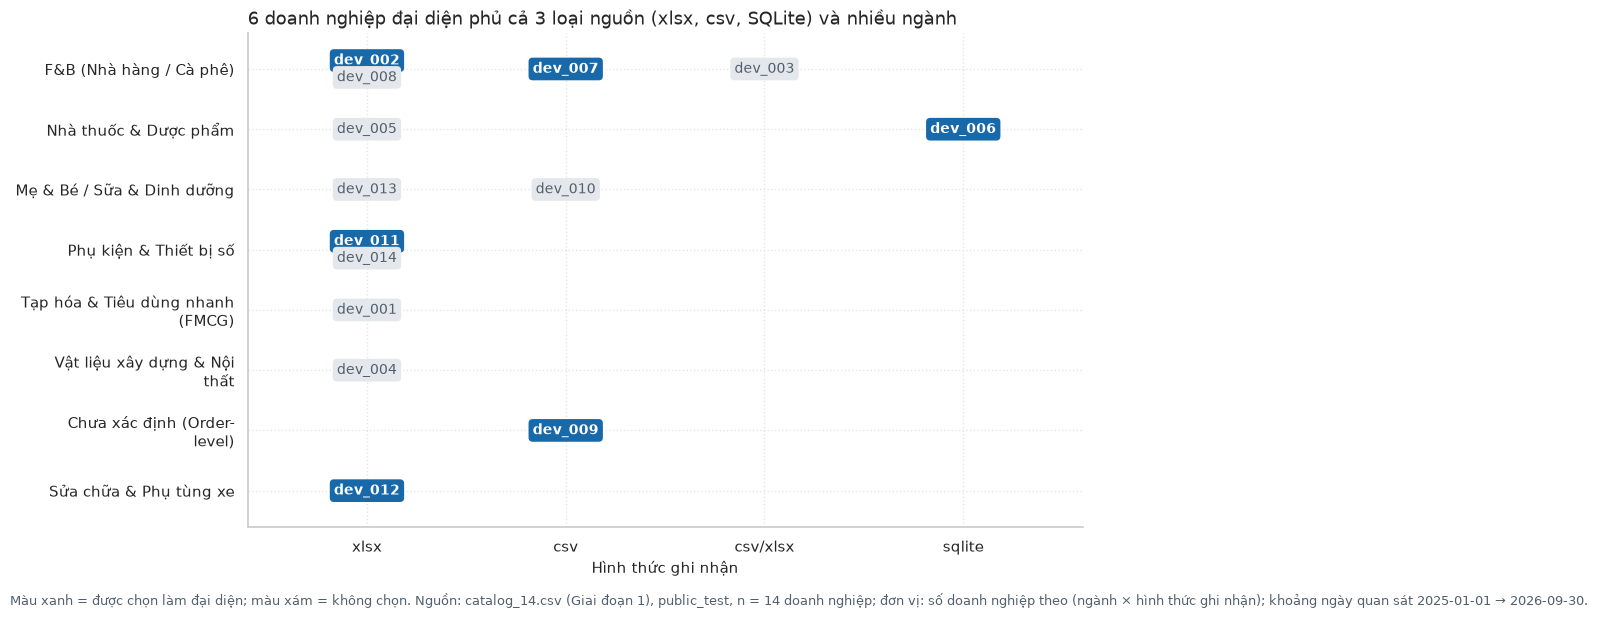

In [10]:
# TODO (T2.1 — Trực quan hóa)
# Có thể vẽ biểu đồ ma trận phân bố 14 doanh nghiệp theo (Ngành nghề × Hình thức ghi nhận / Mức độ số hóa) và tô màu nhấn những doanh nghiệp được chọn làm đại diện.
# Lưu ý: Không sử dụng biểu đồ 3D hoặc hai trục tung (dual axis); biểu đồ cột bắt đầu từ 0.

import textwrap

formats = ["xlsx", "csv", "csv/xlsx", "sqlite"]
industries = list(catalog["industry"].value_counts().index)
x_pos = {f: i for i, f in enumerate(formats)}
y_pos = {ind: i for i, ind in enumerate(industries)}

fig, ax = plt.subplots(figsize=(11, 6))
for (ind, fmt), grp in catalog.groupby(["industry", "recording_format"]):
    if fmt not in x_pos:
        continue
    ids = list(grp["business_id"])
    for k, bid in enumerate(ids):
        chosen = bid in SELECTED_REPRESENTATIVE_BUSINESSES
        ax.text(
            x_pos[fmt], y_pos[ind] + (k - (len(ids) - 1) / 2) * 0.28, bid,
            ha="center", va="center", fontsize=10,
            color="white" if chosen else COLOR_GRAY_DARK,
            fontweight="bold" if chosen else "normal",
            bbox=dict(boxstyle="round,pad=0.3",
                      fc=COLOR_ACCENT_BLUE if chosen else "#E4E7EB",
                      ec="none"),
        )

ax.set_xticks(range(len(formats)))
ax.set_xticklabels(formats)
ax.set_yticks(range(len(industries)))
ax.set_yticklabels([textwrap.fill(i, 26) for i in industries])
ax.set_xlim(-0.6, len(formats) - 0.4)
ax.set_ylim(-0.6, len(industries) - 0.4)
ax.invert_yaxis()
ax.grid(True, linestyle=":", alpha=0.5)
ax.set_xlabel("Hình thức ghi nhận")
ax.set_title(f"{len(SELECTED_REPRESENTATIVE_BUSINESSES)} doanh nghiệp đại diện phủ cả 3 loại nguồn "
             "(xlsx, csv, SQLite) và nhiều ngành")
fig.text(0.01, -0.02,
         "Màu xanh = được chọn làm đại diện; màu xám = không chọn. "
         "Nguồn: catalog_14.csv (Giai đoạn 1), public_test, n = 14 doanh nghiệp; "
         f"đơn vị: số doanh nghiệp theo (ngành × hình thức ghi nhận); "
         f"khoảng ngày quan sát {catalog['min_date'].min()} → {catalog['max_date'].max()}.",
         fontsize=9, color=COLOR_GRAY_DARK)
plt.tight_layout()
fig.savefig(PHASE2_FIGURES_DIR / "t21_representative_matrix.png")
plt.show()

### Kết quả & Nhận định

> **Nhận định (T2.1) — đã ghi nhận từ bằng chứng chạy ở trên:** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Danh sách tập doanh nghiệp đại diện đã chốt và tiêu chí lựa chọn:** Chọn 6/14 doanh nghiệp: `dev_002`, `dev_006`, `dev_007`, `dev_009`, `dev_011`, `dev_012`. Tiêu chí gồm 5 mục chấm điểm (độ giàu thuộc tính 30%, quy mô 20%, độ dài thời gian 20%, độ phức tạp cấu trúc 15%, có chi tiết dòng hàng 15%), kết hợp quy tắc phủ: mỗi hình thức ghi nhận có đại diện và có trường hợp đặc thù (dữ liệu cấp đơn `dev_009`, nhiều tệp/sheet theo tháng `dev_002`/`dev_012`, SQLite `dev_006`). Danh sách không chọn thuần theo điểm cao nhất: `dev_003` (0,777) và `dev_008` (0,682) điểm cao hơn `dev_002` (0,606) nhưng cùng ngành F&B, nên chỉ giữ `dev_002` và `dev_007`; `dev_002` được chọn vì có cấu trúc 18 tệp theo tháng, cần gộp về Tidy Data. Tương tự `dev_009`, `dev_011`, `dev_012` điểm thấp hơn (0,28–0,35) nhưng được giữ để phủ dữ liệu cấp đơn, ngành phụ kiện và ngành sửa xe.

- **Tính đại diện về ngành nghề, mức độ số hóa và độ phủ thời gian của tập mẫu này:** Tập chọn phủ 5/8 nhóm ngành (F&B, Nhà thuốc, Phụ kiện & thiết bị số, Sửa chữa & phụ tùng xe, nhóm chưa xác định), phủ cả Tier 1, 2 và 3, và cả ba loại nguồn (xlsx, csv, SQLite). Khoảng quan sát từ 426 đến 596 ngày (2025-01-01 đến 2026-09-19), độ phủ ngày từ 99,3% đến 100%. Chưa có đại diện cho FMCG, Vật liệu xây dựng và Mẹ & Bé; các doanh nghiệp này (`dev_001`, `dev_004`, `dev_010`, `dev_013`) được giữ cho Hồi 1 và dùng đối chiếu liên ngành ở Hồi 3. Giới hạn: `dev_009` chỉ có dữ liệu cấp đơn nên không phân tích được theo mặt hàng.


## Tác vụ T2.2a — Viết hàm đọc dữ liệu & tính chỉ số chuẩn `rulebook.md`

### Mục tiêu
Xây dựng các hàm xử lý dùng chung (Pure Python / pandas) cho tập đại diện để tính doanh thu, số đơn, tỷ lệ hủy/trả đúng tuyệt đối theo các quy tắc mặc định trong `data/public_test/rulebook.md`.

### Câu hỏi khám phá
- Các quy tắc nào trong `rulebook.md` ảnh hưởng trực tiếp tới việc lọc đơn, xác định ngày đặt và tính tiền đơn hàng?
- Nếu một đơn hàng có trạng thái trả hàng (kể cả trả một phần) hoặc dòng trạng thái để trống ở dòng sau của cùng một đơn, xử lý thế nào?
- Sự khác biệt giữa *Doanh thu một đơn* (tổng thành tiền dòng hàng) với *Tổng khách phải trả* (trừ giảm giá đơn, cộng ship) là gì?

### Các bước thực hiện

**Bước 1 — Rà soát các quy tắc cốt lõi trong `rulebook.md`**
Đọc kỹ Mục 1 (Đơn hàng & doanh thu), Mục 2 (Thời gian), Mục 6 (Theo ngành) và Mục 8 (Cách ghi trong file) từ `rule_registry` hoặc văn bản `rulebook.md`.

**Bước 2 — Ánh xạ cột trạng thái & lọc đơn hủy/trả hàng (kể cả trả một phần)**
Viết logic chuẩn hóa cột trạng thái theo quy ước từng doanh nghiệp (hoàn thành / đang giao / huỷ / trả hàng) và loại toàn bộ đơn bị hủy hoặc có trả hàng khi tính doanh thu & số đơn.

**Bước 3 — Chuẩn hóa ngày đặt hàng làm mốc quy thuộc kỳ**
Xác định chính xác cột ngày đặt hàng (tránh nhầm với ngày giao hay ngày thu tiền) và chuyển sang kiểu `datetime`/`date` thống nhất.

**Bước 4 — Tính giá trị dòng hàng và giá trị đơn hàng chuẩn `rulebook.md`**
Tính doanh thu theo tổng thành tiền các dòng hàng (đã trừ giảm giá dòng, không trừ giảm giá cả đơn, không cộng VAT/phí ship); tách riêng các dòng `Phí phục vụ` nếu có.

**Bước 5 — Kiểm tra đối chiếu kết quả với bảng gốc**
Chọn 3–5 mã đơn hàng cụ thể (gồm 1 đơn thường, 1 đơn nhiều dòng, 1 đơn hủy/trả) để kiểm toán thủ công (audit) xem hàm tính có khớp 100% với tệp gốc không.

### Gợi ý phương pháp & Lưu ý
- Đọc kỹ Mục 8 `rulebook.md`: *Ô để trống ở các dòng sau của cùng một nhóm dòng giống ô đó ở dòng đầu nhóm (forward-fill theo nhóm đơn)* và *Hai dòng giống hệt nhau của cùng một đơn là lỗi xuất file, tính một lần; hai đơn khác nhau vẫn tính cả hai*.
- Chú ý các luật đặc thù theo ngành (Mục 6 `rulebook.md`): ví dụ món + topping ở cà phê, phiếu bảo hành ở sửa xe, tiền thu máy cũ / trả góp ở cửa hàng điện thoại.
- Có thể tận dụng `read_all_csv_rows`, `read_sheet_rows`, `query_readonly` để nạp bảng sạch trước khi đưa vào DataFrame.

### Triển khai


In [11]:
# TODO (T2.2a — Bước 1: Rà soát các quy tắc cốt lõi trong `rulebook.md`)
# TODO: Lọc và in các quy tắc liên quan đến đơn hàng, doanh thu, trạng thái và ngành của tập đại diện

import re, sqlite3, unicodedata
from contextlib import closing

text = context.rulebook_path.read_text(encoding="utf-8")
blocks = re.split(r"\n(?=#{2,3} )", text)
KEEP = ("1. Đơn hàng", "8. Cách ghi", "Cà phê", "Nhà thuốc", "Sửa xe", "Cửa hàng điện thoại")
for b in blocks:
    head = b.split("\n", 1)[0]
    if head.startswith("#") and any(k in head for k in KEEP):
        print(b.strip(), "\n" + "-" * 80)


## 1. Đơn hàng và doanh thu
| Luật | Mặc định |
|---|---|
| Đơn tính vào doanh thu | đơn **không huỷ** và **không trả hàng**. Đơn có trả hàng, **kể cả chỉ trả một phần**, là đơn trả hàng: bỏ **cả đơn**. Đơn đang giao vẫn tính |
| Bán được bao nhiêu tiền, thu về bao nhiêu tiền | là **doanh thu** theo mục này, không phải tiền khách đã trả |
| Đơn thuộc kỳ nào | theo **ngày đặt**, không theo ngày giao hay ngày thu tiền. Đơn trả hàng sau kỳ, kể cả trả sau hôm nay, vẫn bị loại khỏi doanh thu kỳ đặt |
| Đơn bị huỷ | đơn có trạng thái huỷ. Đơn trả hàng **không** phải đơn huỷ |
| Số đơn | chỉ tính đơn không huỷ, không trả; cả khi đếm số đơn có một mặt hàng, số đơn của một khách. **Khách đã mua** trong kỳ là khách có ít nhất một đơn như vậy trong kỳ |
| Doanh thu một đơn | tổng **thành tiền các dòng hàng** (đã trừ giảm giá trên từng dòng). **Không** trừ giảm giá trên cả đơn (khuyến mãi theo tổng tiền đơn, voucher shop), **không** cộng thuế VAT, **không** gồm phí giao hàng. **Tiền hàng**, **tiền

In [12]:
# TODO (T2.2a — Bước 2: Ánh xạ cột trạng thái & lọc đơn hủy/trả hàng (kể cả trả một phần))
# TODO: Viết hàm chuẩn hóa trạng thái đơn và xử lý các dòng để trống trạng thái trong cùng một mã đơn (Mục 8 rulebook)
# T2.2a — Bước 2: Ánh xạ cột, chuẩn hóa trạng thái, forward-fill theo đơn, loại dòng trùng/dòng tổng
import re, sqlite3, unicodedata
from contextlib import closing
from pathlib import Path

# ============ Hàm tiện ích ============
def norm(c) -> str:
    """Chuẩn hóa tên cột: Unicode NFC, gộp khoảng trắng, bỏ khoảng trắng đầu/cuối."""
    if pd.isna(c):
        return ""
    return unicodedata.normalize("NFC", re.sub(r"\s+", " ", str(c))).strip()

def read_table(path, sheet=None, need=()):
    """Đọc csv/xlsx; tự tìm dòng tiêu đề chứa đủ cột `need`; bỏ dòng tiêu đề lặp lại giữa dữ liệu."""
    path = Path(path)
    if path.suffix.lower() == ".csv":
        raw = pd.read_csv(path, dtype=str, encoding="utf-8-sig", header=None)
    else:
        raw = pd.read_excel(path, sheet_name=sheet if sheet is not None else 0, dtype=object, header=None)
    need = {norm(c) for c in need}
    for i in range(min(15, len(raw))):
        if need <= {norm(x) for x in raw.iloc[i].tolist()}:
            break
    else:
        raise KeyError(f"{path.name} [{sheet}]: không thấy dòng tiêu đề chứa {sorted(need)}.\n"
                       f"5 dòng đầu của file:\n{raw.head(5).to_string()}")
    df = raw.iloc[i + 1:].copy()
    df.columns = [norm(x) for x in raw.iloc[i]]
    df = df.reset_index(drop=True)
    repeated_header = df.apply(lambda c: c.astype(str).str.strip().eq(str(c.name))).sum(axis=1) >= 2
    return df[~repeated_header].reset_index(drop=True)

def unaccent(s) -> str:
    if pd.isna(s):
        return ""
    t = unicodedata.normalize("NFD", str(s).lower())
    return "".join(c for c in t if unicodedata.category(c) != "Mn").replace("đ", "d").strip()

def classify_status(text) -> str:
    """4 trạng thái theo rulebook §8: hoan_thanh / huy / tra_hang / dang_giao (hỗ trợ cả tiếng Anh)."""
    t = unaccent(text)
    if re.search(r"\bhuy\b|cancel", t):
        return "huy"
    # 'kiểm tra lại/hàng' KHÔNG phải trả hàng
    if re.search(r"(?<!kiem )(tra hang|tra lai)|hoan tra|hoan hang|mang tra|return|refund", t):
        return "tra_hang"
    if re.search(r"dang giao|dang van chuyen|dang xu ly|shipping|delivering", t):
        return "dang_giao"
    return "hoan_thanh"          # không nhắc trạng thái = hoàn thành (§8)

RANK = {"hoan_thanh": 0, "dang_giao": 1, "tra_hang": 2, "huy": 3}

def to_num(s: pd.Series) -> pd.Series:
    n = pd.to_numeric(s, errors="coerce")
    bad = n.isna() & s.notna()
    if bad.any():
        t = s[bad].astype(str).str.strip().str.lower()
        mult = np.where(t.str.contains(r"\d\s*k$"), 1000.0, 1.0)
        x = t.str.replace(r"[^\d,.\-]", "", regex=True)
        dot = x.str.match(r"^-?\d{1,3}(\.\d{3})+(,\d+)?$")
        x = x.where(~dot, x.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
        com = x.str.match(r"^-?\d{1,3}(,\d{3})+$")
        x = x.where(~com, x.str.replace(",", "", regex=False))
        out = pd.to_numeric(x, errors="coerce") * mult
        tr = t.str.extract(r"^(\d+)(?:[,.](\d+))?tr(\d+)?$")          # dạng triệu
        trieu = (tr[0].astype(float) + ("0." + tr[1].fillna(tr[2]).fillna("0")).astype(float)) * 1e6
        n[bad] = out.where(tr[0].isna(), trieu)
    return n

def fill_order_level(raw, id_col, cols):
    """§8: ô trống ở dòng sau của cùng đơn = giá trị dòng đầu đơn."""
    raw = raw.copy()
    cols = [c for c in cols if c in raw.columns]
    raw[[id_col] + cols] = raw[[id_col] + cols].replace(r"^\s*$", np.nan, regex=True)
    raw[id_col] = raw[id_col].ffill()
    raw[cols] = raw.groupby(id_col)[cols].ffill()
    return raw

def std(biz, raw, order_id, date, status, item, qty, amount, file_total=None,
        unit=None, qty_base=None, **extra):
    """Bảng chuẩn cấp dòng hàng (cùng một lược đồ cho mọi doanh nghiệp)."""
    nan = pd.Series(np.nan, index=raw.index)
    if order_id.isna().any():
        raise ValueError(f"{biz}: {order_id.isna().sum()} dòng thiếu mã đơn")
    return pd.DataFrame({
        "business_id": biz,
        "order_id": order_id.astype(str),
        "date_raw": date,
        "year_hint": raw["year_hint"] if "year_hint" in raw else nan,
        "month_hint": raw["month_hint"] if "month_hint" in raw else nan,
        "status_raw": status if status is not None else nan,
        "item": item if item is not None else nan,
        "qty": to_num(qty) if qty is not None else nan,
        "line_amount": amount,                       # thành tiền dòng hàng, đã trừ giảm giá dòng
        "force_return": raw["force_return"] if "force_return" in raw else False,
        "file_order_total": file_total if file_total is not None else nan,
        "unit": unit if unit is not None else nan,                 # đơn vị tính ghi trên dòng
        "qty_base": to_num(qty_base) if qty_base is not None else nan,   # số lượng đã quy đổi (nếu tệp có sẵn)
    }).assign(**extra)

# ============ Bộ đọc theo từng doanh nghiệp ============
def load_dev_002():
    root = context.business_root_path("dev_002")
    parts = []
    for f in sorted(root.glob("BanHang_T*.xlsx")):
        d = read_table(f, sheet="DonHang_ChiTiet", need=["Mã đơn hàng"])
        d["year_hint"] = int(re.search(r"(\d{4})", f.stem).group(1))
        parts.append(d)
    raw = pd.concat(parts, ignore_index=True)
    raw = raw[raw["Mã đơn hàng"].notna()]      # bỏ dòng "TỔNG NGÀY dd/mm" (không có mã đơn), kẻo bị ffill dính vào đơn trước
    raw = fill_order_level(raw, "Mã đơn hàng",
                           ["Ngày đặt hàng", "Trạng thái đơn hàng", "Tên khách hàng"]).drop_duplicates()
    amount = to_num(raw["Tổng tiền"])           # thành tiền dòng: đã trừ giảm giá dòng, đã gồm tiền topping (README)
    diff = (amount - to_num(raw["Số lượng sản phẩm"]) * to_num(raw["Giá sản phẩm"])).abs() >= 1
    print(f"dev_002: 'Tổng tiền' khác SL×Giá ở {diff.mean() * 100:.2f}% dòng (giảm giá dòng hoặc có topping)")
    return std("dev_002", raw, raw["Mã đơn hàng"], raw["Ngày đặt hàng"], raw["Trạng thái đơn hàng"],
               raw["Tên sản phẩm"], raw["Số lượng sản phẩm"], amount, unit=raw["Đơn vị tính"])

def load_dev_006():
    db = context.business_root_path("dev_006") / "pos.sqlite"
    with closing(sqlite3.connect(f"file:{db}?mode=ro", uri=True)) as con:
        lines = pd.read_sql("SELECT IDCuaHang, MaHoaDon, SoThuTu, MaHangHoa, DonViTinh, SL, SLQuyDoi, TriGia FROM chi_tiet_don", con)
        orders = pd.read_sql("SELECT IDCuaHang, MaHoaDon, NgayLap, TinhTrang, TongTienHang FROM don_hang", con)
        returned = pd.read_sql("SELECT DISTINCT MaHoaDon FROM tra_hang", con)
    raw = lines.drop_duplicates().merge(orders, on=["IDCuaHang", "MaHoaDon"], how="left", validate="m:1")
    raw["force_return"] = raw["MaHoaDon"].isin(returned["MaHoaDon"])    # có phiếu trả (kể cả trả một phần)
    return std("dev_006", raw, raw["MaHoaDon"], raw["NgayLap"], raw["TinhTrang"],
               raw["MaHangHoa"], raw["SL"], to_num(raw["TriGia"]), to_num(raw["TongTienHang"]),
               unit=raw["DonViTinh"], qty_base=raw["SLQuyDoi"])

def load_dev_007():
    raw = read_table(context.business_root_path("dev_007") / "chi_tiet_hoa_don.csv", need=["Mã bill"])
    raw = raw[raw["Mã bill"].notna()]          # bỏ dòng tổng ngày (không có mã bill), kẻo bị ffill dính vào đơn trước
    raw = fill_order_level(raw, "Mã bill",
                           ["Ngày giao dịch", "Tiến độ", "Họ tên khách", "Mã khách mua", "Tổng tiền hàng"]).drop_duplicates()
    return std("dev_007", raw, raw["Mã bill"], raw["Ngày giao dịch"], raw["Tiến độ"],
               raw["Mặt hàng"], raw["Sluong"], to_num(raw["Thành tiền"]), to_num(raw["Tổng tiền hàng"]),
               qty_base=raw["Số lượng lẻ"])

def load_dev_009():
    raw = read_table(context.business_root_path("dev_009") / "danh_sach_hoa_don.csv", need=["Mã hóa đơn"])
    # Loại dòng tổng cộng theo ngày ("Tổng ngày dd/mm") và mọi dòng không có mã hóa đơn
    no_id = raw["Mã hóa đơn"].isna() | raw["Mã hóa đơn"].astype(str).str.strip().eq("")
    is_total = raw["Đối tác"].astype(str).str.contains(r"^\s*Tổng", case=False, regex=True)
    drop = no_id | is_total
    print(f"dev_009: loại {drop.sum()} dòng tổng/không mã "
          f"({(no_id & ~is_total).sum()} dòng không mã nhưng không phải 'Tổng ...')")
    raw = raw[~drop].drop_duplicates()
    # Doanh thu = 'Giá trị hàng' (tiền hàng), không dùng 'TongTien' (đã gồm giảm giá đơn/ship/VAT)
    return std("dev_009", raw, raw["Mã hóa đơn"], raw["Ngày tháng"], raw["Trạng thái đơn"],
               None, None, to_num(raw["Giá trị hàng"]))

def load_dev_011():
    raw = read_table(context.business_root_path("dev_011") / "SoBanHang.xlsx",
                     sheet="Sổ bán hàng", need=["Ngày", "STT"])
    raw[["Ngày", "STT"]] = raw[["Ngày", "STT"]].replace(r"^\s*$", np.nan, regex=True).ffill()
    raw["order_key"] = raw["Ngày"].astype(str) + "|" + raw["STT"].astype(str)
    raw = fill_order_level(raw, "order_key", ["Khách", "Ghi chú"]).drop_duplicates()
    # Sổ không có cột trạng thái -> trạng thái nằm ở 'Ghi chú' (§8). 'Bớt', 'Thu máy cũ' không trừ vào doanh thu
    return std("dev_011", raw, raw["order_key"], raw["Ngày"], raw["Ghi chú"],
               raw["Hàng"], raw["SL"], to_num(raw["Thành tiền"]))

def load_dev_012():
    path = context.business_root_path("dev_012") / "SoSuaXe.xlsx"
    parts = []
    for name in pd.ExcelFile(path).sheet_names:
        try:
            d = read_table(path, sheet=name, need=["Ngày", "Tiền"])
        except KeyError:
            continue
        y, m = re.search(r"(\d{4})", name), re.search(r"[Tt]\s*(\d{1,2})", name)
        parts.append(d.assign(sheet=name, year_hint=int(y.group(1)) if y else np.nan,
                              month=int(m.group(1)) if m else np.nan))
    raw = pd.concat(parts, ignore_index=True).dropna(how="all", subset=["Ngày", "Xe", "Làm gì", "Tiền"])
    raw = raw[raw["Xe"].notna()]               # bỏ dòng "Ghi chú: ..." cuối sheet (không phải phiếu sửa xe)
    num = pd.to_numeric(raw["Ngày"], errors="coerce")
    ok = num.between(1, 31) & (num % 1 == 0) & raw["month"].notna() & raw["year_hint"].notna()
    raw["Ngày"] = raw["Ngày"].astype(object)
    raw.loc[ok, "Ngày"] = (num[ok].astype(int).astype(str) + "/" + raw.loc[ok, "month"].astype(int).astype(str)
                           + "/" + raw.loc[ok, "year_hint"].astype(int).astype(str))
    order_id = raw["sheet"] + "|" + raw.index.astype(str)
    return std("dev_012", raw, order_id, raw["Ngày"], raw["Ghi chú"],
               raw["Làm gì"], pd.Series(1, index=raw.index), to_num(raw["Tiền"]),
               xe=raw["Xe"], tho=raw["Thợ"])

LOADERS = {"dev_002": load_dev_002, "dev_006": load_dev_006, "dev_007": load_dev_007,
           "dev_009": load_dev_009, "dev_011": load_dev_011, "dev_012": load_dev_012}

def add_order_status(df):
    """Trạng thái cấp đơn: ưu tiên huỷ > trả > đang giao > hoàn thành; có phiếu trả => trả hàng."""
    df = df.copy()
    r = df["status_raw"].map(classify_status).map(RANK)
    r = r.where(~df["force_return"], r.clip(lower=RANK["tra_hang"]))
    df["order_rank"] = r.groupby([df["business_id"], df["order_id"]]).transform("max")
    df["status"] = df["order_rank"].map({v: k for k, v in RANK.items()})
    df["is_valid"] = df["status"].isin(["hoan_thanh", "dang_giao"])   # tính vào doanh thu & số đơn
    return df

# ============ Chạy ============
std_tables = {}
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    print(f"\nĐang đọc {b} ...")
    std_tables[b] = add_order_status(LOADERS[b]())

# ============ Bảng kiểm tra (gọn, không bị cắt output) ============
print("\nĐã đọc:", list(std_tables.keys()))
rows = []
for b, d in std_tables.items():
    o = d.drop_duplicates("order_id")["status"].value_counts()
    rows.append({"business_id": b, "so_dong": len(d), "so_don": d["order_id"].nunique(),
                 **{k: int(o.get(k, 0)) for k in ["hoan_thanh", "dang_giao", "tra_hang", "huy"]}})
display(pd.DataFrame(rows))

for b in ["dev_011", "dev_012"]:       # trạng thái nằm ở 'Ghi chú': xem ghi chú nào bị xếp vào huỷ/trả/đang giao
    d = std_tables[b]
    x = d[d["status"] != "hoan_thanh"]
    print(f"\n{b}: ghi chú bị xếp vào huỷ/trả/đang giao ->",
          x.groupby(["status", "status_raw"]).size().to_dict() if len(x) else "(không có)")


Đang đọc dev_002 ...


dev_002: 'Tổng tiền' khác SL×Giá ở 2.54% dòng (giảm giá dòng hoặc có topping)



Đang đọc dev_006 ...



Đang đọc dev_007 ...



Đang đọc dev_009 ...
dev_009: loại 540 dòng tổng/không mã (0 dòng không mã nhưng không phải 'Tổng ...')

Đang đọc dev_011 ...



Đang đọc dev_012 ...



Đã đọc: ['dev_002', 'dev_006', 'dev_007', 'dev_009', 'dev_011', 'dev_012']


,business_id,so_dong,so_don,hoan_thanh,dang_giao,tra_hang,huy
0,dev_002,84146,53164,51851,38,206,1069
1,dev_006,71061,37833,37070,16,352,395
2,dev_007,119070,32022,31310,14,68,630
3,dev_009,22490,22490,21424,7,384,675
4,dev_011,6043,3819,3790,0,29,0
5,dev_012,6060,6060,6060,0,0,0



dev_011: ghi chú bị xếp vào huỷ/trả/đang giao -> {('tra_hang', 'khách mang trả'): 19, ('tra_hang', 'khách trả lại'): 7, ('tra_hang', 'trả lại hàng'): 19}

dev_012: ghi chú bị xếp vào huỷ/trả/đang giao -> (không có)


In [13]:
# TODO (T2.2a — Bước 3: Chuẩn hóa ngày đặt hàng làm mốc quy thuộc kỳ)
# TODO: Viết hàm chuẩn hóa ngày đặt hàng cho từng doanh nghiệp đại diện
# Chuẩn hóa ngày đặt hàng (ngày không ghi năm -> lấy năm của tệp/sheet, §8)

def parse_order_date(date_raw: pd.Series, year_hint: pd.Series) -> pd.Series:
    s = date_raw
    txt = s.astype(str).str.strip()
    no_year = txt.str.match(r"^\d{1,2}[/\-.]\d{1,2}$")                  # dạng 'd/m' thiếu năm
    yh = pd.to_numeric(year_hint, errors="coerce").astype("Int64").astype(str)
    s = s.where(~no_year, txt + "/" + yh)
    vn = txt.str.extract(r"^(\d{1,2}) thg (\d{1,2}) (\d{4})$")             # dạng '9 thg 7 2025'
    s = s.where(vn[0].isna(), vn[0] + "/" + vn[1] + "/" + vn[2])
    serial = pd.to_numeric(txt.where(txt.str.fullmatch(r"\d{5}(\.\d+)?")), errors="coerce")   # ngày dạng số Excel, vd 45840
    excel = pd.Timestamp("1899-12-30") + pd.to_timedelta(serial, unit="D")
    iso = pd.to_datetime(s.astype(str).str[:10], format="%Y-%m-%d", errors="coerce")   # ISO trước
    rest = pd.to_datetime(s.where(iso.isna() & serial.isna()), errors="coerce", dayfirst=True, format="mixed")
    out = iso.astype("datetime64[ns]").fillna(rest.astype("datetime64[ns]")).fillna(excel.astype("datetime64[ns]"))
    return out.dt.normalize()

cat_range = catalog.set_index("business_id")[["min_date", "max_date"]]
rows = []
for b, d in std_tables.items():
    d["order_date"] = parse_order_date(d["date_raw"], d["year_hint"])
    rows.append({
        "business_id": b,
        "dong_loi_ngay": int(d["order_date"].isna().sum()),
        "min_date": d["order_date"].min().date(),
        "max_date": d["order_date"].max().date(),
        "catalog_min": cat_range.loc[b, "min_date"],
        "catalog_max": cat_range.loc[b, "max_date"],
    })
display(pd.DataFrame(rows))      # min/max phải khớp catalog Giai đoạn 1


,business_id,dong_loi_ngay,min_date,max_date,catalog_min,catalog_max
0,dev_002,0,2025-01-01,2026-05-24,2025-01-01,2026-05-24
1,dev_006,0,2025-04-01,2026-08-08,2025-04-01,2026-08-08
2,dev_007,0,2025-02-01,2026-09-19,2025-02-01,2026-09-19
3,dev_009,0,2025-01-01,2026-06-24,2025-01-01,2026-06-24
4,dev_011,0,2025-06-01,2026-07-31,2025-06-01,2026-07-31
5,dev_012,0,2025-07-01,2026-08-31,2025-07-01,2026-08-31


In [14]:
# TODO (T2.2a — Bước 4: Tính giá trị dòng hàng và giá trị đơn hàng chuẩn `rulebook.md`)
# TODO: Viết hàm tính doanh thu cấp dòng và cấp đơn hàng đúng chuẩn rulebook.md

def build_orders(d: pd.DataFrame) -> pd.DataFrame:
    """Gộp dòng -> đơn. Doanh thu đơn = tổng thành tiền dòng hàng (không trừ giảm giá đơn, không VAT, không ship)."""
    is_fee = d["item"].map(lambda x: "phi phuc vu" in unaccent(x))     # dòng Phí phục vụ
    d = d.assign(fee_amount=d["line_amount"].where(is_fee, 0.0))
    g = d.groupby(["business_id", "order_id"], sort=False)
    return g.agg(order_date=("order_date", "min"), status=("status", "first"),
                 is_valid=("is_valid", "first"), n_lines=("line_amount", "size"),
                 revenue=("line_amount", "sum"), fee=("fee_amount", "sum"),
                 file_order_total=("file_order_total", "first")).reset_index()

orders = pd.concat([build_orders(d) for d in std_tables.values()], ignore_index=True)

rows = []
for b, o in orders.groupby("business_id"):
    v = o[o["is_valid"]]
    rows.append({
        "business_id": b,
        "so_don_tat_ca": len(o),
        "so_don_hop_le": len(v),
        "doanh_thu": int(round(v["revenue"].sum())),
        "doanh_thu_phi_phuc_vu": int(round(v["fee"].sum())),
        "ti_le_huy_%": round(100 * (o["status"] == "huy").mean(), 2),
        "ti_le_tra_%": round(100 * (o["status"] == "tra_hang").mean(), 2),
        "thanh_tien_NaN": int(std_tables[b]["line_amount"].isna().sum()),
    })
summary_2a = pd.DataFrame(rows)
display(summary_2a)

,business_id,so_don_tat_ca,so_don_hop_le,doanh_thu,doanh_thu_phi_phuc_vu,ti_le_huy_%,ti_le_tra_%,thanh_tien_NaN
0,dev_002,53164,51889,3689065000,0,2.01,0.39,0
1,dev_006,37833,37086,4174528900,0,1.04,0.93,0
2,dev_007,32022,31324,16480826000,118623000,1.97,0.21,0
3,dev_009,22490,21431,9939539500,0,3.00,1.71,0
4,dev_011,3819,3790,15449174500,0,0.00,0.76,0
5,dev_012,6060,6060,1301809500,0,0.00,0.00,0


In [15]:
# TODO (T2.2a — Bước 5: Kiểm tra đối chiếu kết quả với bảng gốc)
# TODO: Thực hiện đối chiếu (audit) 3–5 mã đơn cụ thể giữa bảng gốc và hàm vừa viết

# (a) Tự động: so doanh thu tính được với tổng tiền hàng mà chính tệp gốc ghi trên đơn (dev_006, dev_007)
chk = orders.dropna(subset=["file_order_total"]).copy()
chk["khop"] = (chk["revenue"] - chk["file_order_total"]).abs() < 1
display(chk.groupby("business_id")["khop"].agg(so_don="size", ti_le_khop="mean").round(4))
display(chk[~chk["khop"]].head(5)[["business_id", "order_id", "revenue", "file_order_total"]])

# (b) Thủ công: in 3 đơn mẫu mỗi doanh nghiệp để mở tệp gốc đối chiếu
def audit(b):
    o = orders[orders["business_id"] == b]
    picks = {
        "đơn thường (1 dòng, hoàn thành)": o[(o["status"] == "hoan_thanh") & (o["n_lines"] == 1)],
        "đơn nhiều dòng (hoàn thành)":     o[(o["status"] == "hoan_thanh") & (o["n_lines"] > 1)],
        "đơn huỷ/trả":                     o[o["status"].isin(["huy", "tra_hang"])],
    }
    for label, sub in picks.items():
        if sub.empty:
            print(f"[{b}] {label}: không có mẫu")
            continue
        r = sub.iloc[0]
        print(f"\n[{b}] {label} | order_id={r['order_id']} | trạng thái={r['status']} "
              f"| tính vào doanh thu={r['is_valid']} | doanh thu đơn={r['revenue']:,.0f}")
        d = std_tables[b]
        display(d.loc[d["order_id"] == r["order_id"], ["order_date", "status_raw", "item", "qty", "line_amount"]])

for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    audit(b)

,so_don,ti_le_khop
business_id,,
dev_006,37833,1.0
dev_007,32022,1.0


,business_id,order_id,revenue,file_order_total



[dev_002] đơn thường (1 dòng, hoàn thành) | order_id=ORD029551 | trạng thái=hoan_thanh | tính vào doanh thu=True | doanh thu đơn=25,000


,order_date,status_raw,item,qty,line_amount
0,2025-10-01,Đã hoàn thành,Cà phê đen (M),1.0,25000.0



[dev_002] đơn nhiều dòng (hoàn thành) | order_id=ORD029553 | trạng thái=hoan_thanh | tính vào doanh thu=True | doanh thu đơn=71,000


,order_date,status_raw,item,qty,line_amount
2,2025-10-01,Đã hoàn thành,Cà phê sữa (M),1.0,29000.0
3,2025-10-01,Đã hoàn thành,Trà sữa trân châu (M),1.0,42000.0


... (23 outputs left out)

,order_date,status_raw,item,qty,line_amount
860,2025-08-01,trả lại hàng,Cáp Type-C sang Lightning 1m,1,150000



[dev_012] đơn thường (1 dòng, hoàn thành) | order_id=T7-2025|0 | trạng thái=hoan_thanh | tính vào doanh thu=True | doanh thu đơn=120,000


,order_date,status_raw,item,qty,line_amount
0,2025-07-01,NaN,vệ sinh nồi,1,120000.0


[dev_012] đơn nhiều dòng (hoàn thành): không có mẫu
[dev_012] đơn huỷ/trả: không có mẫu


### Kết quả & Nhận định

> **Nhận định (T2.2a) — đã ghi nhận từ bằng chứng chạy ở trên:** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Tóm tắt các quy tắc `rulebook.md` đặc thù áp dụng cho từng doanh nghiệp trong tập đại diện:**
  - **Mục 1 — Đơn hàng & doanh thu (áp dụng chung cho cả 6 DN):** chỉ tính đơn *không huỷ* và *không trả hàng*; đơn có trả hàng **kể cả trả một phần** thì bỏ **cả đơn**; đơn đang giao **vẫn tính**. Doanh thu một đơn = **tổng thành tiền các dòng hàng** (đã trừ giảm giá trên từng dòng), **không** trừ giảm giá cả đơn, **không** cộng VAT, **không** gồm phí giao hàng. Kỳ được quy theo **ngày đặt**, không theo ngày giao hay ngày thu tiền.
  - **Mục 8 — Cách ghi trong file:** dòng có **trạng thái để trống** ở dòng sau của cùng một mã đơn được forward-fill theo đơn; dòng tổng kết / dòng không mã đơn bị loại (ví dụ `dev_009` loại **540 dòng** tổng; `dev_002` có **2,54%** dòng lệch `Tổng tiền` so với SL × Giá do giảm giá dòng hoặc có topping).
  - **Mục 6 — Theo ngành (áp dụng riêng theo từng DN):** `dev_007` (quán ăn) có dòng **Phí phục vụ** tách riêng — tổng **118.623.000đ** được ghi nhận và tách khỏi doanh thu dòng hàng; `dev_011` (cửa hàng điện thoại) có **45 dòng ghi chú** (`khách mang trả`, `khách trả lại`, `trả lại hàng`) phải xếp vào trạng thái *trả hàng* chứ không phải *đang giao*; `dev_012` (sửa xe) có **164 dòng thành tiền bằng 0** là phiếu bảo hành nên vẫn giữ để bảo toàn số lượt xe theo rulebook §6.
  - **Quy ước ngày:** ngày thiếu năm được suy từ tên tệp/sheet (`T05-2025` → năm 2025); các định dạng Excel serial, `DD/MM/YYYY` và `D thg M YYYY` đều được chuẩn hóa về `YYYY-MM-DD`. Kết quả: **0 dòng lỗi ngày** trên cả 6 DN, và `min_date`/`max_date` tính được **khớp 100%** với `catalog_14.csv` của Giai đoạn 1.

- **Kết quả đối chiếu (audit) trên các mã đơn kiểm thử:**
  - **Đối chiếu tự động (mạnh nhất):** so sánh doanh thu do hàm tính với *tổng tiền hàng mà chính tệp gốc ghi trên đơn* — `dev_006` **37.833/37.833 đơn khớp 100%** và `dev_007` **32.022/32.022 đơn khớp 100%** (0 dòng lệch).
  - **Đối chiếu thủ công theo mẫu:** in 3 mẫu mỗi DN (đơn 1 dòng hoàn thành · đơn nhiều dòng hoàn thành · đơn huỷ/trả) kèm dòng hàng gốc để mở tệp nguồn kiểm tra — ví dụ `dev_006` đơn `ORD000004` (4 dòng, 41.400đ) được gộp đúng từ 4 dòng `chi_tiet_don`; `dev_007` đơn `ORD000002` trạng thái `Đã hủy đơn` (3 dòng, 524.000đ) **không** tính vào doanh thu; `dev_011` đơn `2025-08-01 00:00:00|537` ghi chú `trả lại hàng` cũng bị loại.
  - **Tổng hợp chỉ số sau khi lọc (6 DN):**

    | DN | Đơn tất cả | Đơn hợp lệ | Doanh thu (VNĐ) | % huỷ | % trả hàng |
    |---|---|---|---|---|---|
    | `dev_002` | 53.164 | 51.889 | 3.689.065.000 | 2,01% | 0,39% |
    | `dev_006` | 37.833 | 37.086 | 4.174.528.900 | 1,04% | 0,93% |
    | `dev_007` | 32.022 | 31.324 | 16.480.826.000 | 1,97% | 0,21% |
    | `dev_009` | 22.490 | 21.431 | 9.939.539.500 | 3,00% | 1,71% |
    | `dev_011` | 3.819 | 3.790 | 15.449.174.500 | 0,00% | 0,76% |
    | `dev_012` | 6.060 | 6.060 | 1.301.809.500 | 0,00% | 0,00% |

  - **Giới hạn của bước kiểm chứng này:** đối chiếu tự động 100% chỉ áp dụng cho `dev_006` và `dev_007` vì 2 DN này mới ghi sẵn tổng tiền đơn trên tệp gốc; 4 DN còn lại được kiểm chứng bằng đối chiếu thủ công theo mẫu. `dev_012` không có mẫu đơn nhiều dòng và không có đơn huỷ/trả (nguồn không ghi trạng thái huỷ), nên hai nhóm mẫu này không có đại diện — đây là đặc thù của dữ liệu, không phải thiếu sót của logic.


## Tác vụ T2.2b — Chuẩn hóa đặc thù theo doanh nghiệp (Quy đổi đơn vị, `Ghi tắt`, Tidy Data)

### Mục tiêu
Chuẩn hóa các quy ước riêng của từng doanh nghiệp (quy đổi về đơn vị cơ bản, giải mã `Ghi tắt`, tách năm từ tên sheet nếu ngày thiếu năm) và xuất dữ liệu dạng Tidy Data ra `PHASE2_TIDY_DIR`.

### Câu hỏi khám phá
- Doanh nghiệp nào có bảng quy đổi đơn vị tính (thùng/lốc/hộp/vỉ -> đơn vị cơ bản) hoặc ghi quy ước này trong `README.md`?
- Doanh nghiệp nào sử dụng bảng `Ghi tắt` (tên hàng, loại xe, mã ghi chú) cần giải mã trước khi xếp hạng hoặc nhóm?
- Những bảng nào đang ở dạng rộng (wide), chia nhiều sheet/tệp theo tháng hoặc gộp nhiều biến trong một cột cần đưa về dạng dài (Tidy Data)?

### Các bước thực hiện

**Bước 1 — Khám phá sự đa dạng đơn vị tính và bảng quy đổi**
Kiểm tra cột `Đơn vị tính`, `Số lượng quy đổi` (nếu có sẵn) và các bảng/quy ước quy đổi đơn vị của từng doanh nghiệp đại diện.

**Bước 2 — Xây dựng logic quy đổi số lượng về đơn vị cơ bản**
Viết hàm ánh xạ `(mặt hàng, đơn vị tính) -> hệ số quy đổi` để quy toàn bộ số lượng bán về đơn vị cơ bản trước khi xếp hạng.

**Bước 3 — Giải mã bảng `Ghi tắt` và chuẩn hóa danh mục hàng/nhóm hàng**
Nạp bảng `Ghi tắt` (nếu có) và áp dụng từ điển ánh xạ chuẩn (giữ nguyên tên gốc ở một cột riêng để đối chiếu provenance).

**Bước 4 — Chuyển đổi sang Tidy Data và xuất ra `PHASE2_TIDY_DIR`**
Gộp các sheet theo tháng (nếu cùng cấu trúc, bổ sung năm từ tên sheet nếu ngày thiếu năm), tổ chức bảng dạng dài và lưu `<business_id>_tidy.csv` vào `PHASE2_TIDY_DIR`.

**Bước 5 — Kiểm tra bảo toàn tổng số liệu trước và sau chuẩn hóa**
Đối chiếu tổng số dòng hợp lệ, tổng doanh thu và tổng số lượng trước và sau bước chuẩn hóa/Tidy để chứng minh không mất mát hay nhân đôi bản ghi (fanout).

### Gợi ý phương pháp & Lưu ý
- Theo `rulebook.md` (Mục 3): khi xếp hạng *bán chạy*, phải quy về đơn vị cơ bản; không cộng số lượng khác đơn vị gốc khi chưa quy đổi.
- Khi gộp các bảng (ví dụ dòng hàng với danh mục hàng hóa để lấy `Nhóm hàng` hoặc `Giá vốn`), luôn kiểm tra số dòng trước và sau `merge` để tránh bùng nổ Cartesian (`fanout > 1`).
- Lưu từng bảng sạch `<business_id>_tidy.csv` trong `PHASE2_TIDY_DIR` giúp Notebook 03 tự động nạp được ở bước đối chiếu.

### Triển khai


In [16]:
# T2.2b — Bước 1: Khám phá sự đa dạng đơn vị tính và bảng quy đổi

def item_key(s) -> str:
    """Khoá so khớp tên: bỏ dấu, không phân biệt hoa/thường, gộp khoảng trắng (rulebook §8: các tên cùng chỉ một thứ là một)."""
    return re.sub(r"\s+", " ", unaccent(s))

# dev_002: bảng quy đổi nằm trong DanhSachQuyDoi.xlsx
unit_002 = pd.read_excel(context.business_root_path("dev_002") / "DanhSachQuyDoi.xlsx")
unit_002.columns = ["item", "source_unit", "factor", "base_unit"]

# dev_006: hệ số ở bảng don_vi_sp, đơn vị cơ bản ở bảng san_pham
db = context.business_root_path("dev_006") / "pos.sqlite"
with closing(sqlite3.connect(f"file:{db}?mode=ro", uri=True)) as con:
    unit_006 = pd.read_sql(
        "SELECT d.MaHangHoa AS item, d.DonViTinh AS source_unit, d.HeSoQuyDoi AS factor, s.DonViCoSo AS base_unit "
        "FROM don_vi_sp d JOIN san_pham s USING (MaHangHoa)", con)

# dev_007: không có bảng, quy ước ghi trong README ("- Bia Tiger lon: 1 thùng = 24 lon")
readme_007 = (context.business_root_path("dev_007") / "README.md").read_text(encoding="utf-8")
unit_007 = pd.DataFrame(re.findall(r"- (.+?): 1 (\w+) = (\d+) (\w+)", readme_007),
                        columns=["item", "source_unit", "factor", "base_unit"])

# Gộp thành một bảng quy đổi chung
unit_table = pd.concat([u.assign(business_id=b) for b, u in
                        [("dev_002", unit_002), ("dev_006", unit_006), ("dev_007", unit_007)]], ignore_index=True)
unit_table["factor"] = unit_table["factor"].astype(float)
unit_table["key"] = unit_table["item"].map(item_key)
assert not unit_table.duplicated(["business_id", "key", "source_unit"]).any(), "Một (mặt hàng, đơn vị) có 2 hệ số"

# Kiểm tra bảng quy đổi bằng validate_unit_mapping + đối chiếu với đơn vị thật sự ghi trên dòng bán
rows = []
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    u = unit_table[unit_table["business_id"] == b]
    d = std_tables[b]
    reg = validate_unit_mapping("public_test", b, u.to_dict("records"), "item", "source_unit", "base_unit", "factor") if len(u) else None
    rows.append({
        "business_id": b,
        "so_mat_hang_co_don_vi_lon": u["item"].nunique(),
        "don_vi_lon": sorted(u["source_unit"].unique()),
        "don_vi_co_so": list(reg.distinct_base_units) if reg else [],
        "don_vi_ghi_tren_dong_ban": dict(d["unit"].value_counts()) if d["unit"].notna().any() else "(không có cột đơn vị)",
    })
display(pd.DataFrame(rows))
print("dev_009 (cấp đơn), dev_011 (bán theo máy/cái), dev_012 (tính theo phiếu): không có đơn vị lớn cần quy đổi")


,business_id,so_mat_hang_co_don_vi_lon,don_vi_lon,don_vi_co_so,don_vi_ghi_tren_dong_ban
0,dev_002,2,[hộp],[cái],"{'ly': 76038, 'phần': 5505, 'cái': 2543, 'hộp': 60}"
1,dev_006,53,"[chai, hộp, lốc, tuýp, vỉ]","[cái, gói, lọ, miếng, viên, vỉ, ống]","{'viên': 27456, 'chai': 10671, 'gói': 9557, 'hộp': 8372, 'vỉ': 4583, 'tuýp': 3260, 'lọ': 2400, 'cái': 2301, 'ống': 1..."
2,dev_007,8,"[két, thùng]","[chai, lon]",(không có cột đơn vị)
3,dev_009,0,[],[],(không có cột đơn vị)
4,dev_011,0,[],[],(không có cột đơn vị)
5,dev_012,0,[],[],(không có cột đơn vị)


dev_009 (cấp đơn), dev_011 (bán theo máy/cái), dev_012 (tính theo phiếu): không có đơn vị lớn cần quy đổi


In [17]:
# T2.2b — Bước 2: Quy đổi số lượng về đơn vị cơ bản

def to_base_qty(d: pd.DataFrame, b: str) -> pd.Series:
    """Số lượng cơ bản = số lượng × hệ số của (mặt hàng, đơn vị bán).
    Đơn vị không có trong bảng quy đổi là đơn vị cơ bản, hệ số 1 (rulebook §10)."""
    t = unit_table.loc[unit_table["business_id"] == b, ["key", "source_unit", "factor"]]
    m = d.assign(key=d["item"].map(item_key)).merge(
        t, how="left", left_on=["key", "unit"], right_on=["key", "source_unit"], validate="m:1")
    return (m["qty"] * m["factor"].fillna(1.0)).set_axis(d.index)

# dev_002, dev_006: có cột đơn vị trên dòng -> tính theo bảng quy đổi
for b in ("dev_002", "dev_006"):
    d = std_tables[b]
    calc = to_base_qty(d, b)
    if d["qty_base"].notna().any():                  # dev_006: tệp có sẵn SLQuyDoi -> đối chiếu
        print(f"{b}: tính lại khớp SLQuyDoi của tệp ở {(calc == d['qty_base']).mean() * 100:.2f}% dòng")
    d["qty_base"] = calc
    n_conv = (calc != d["qty"]).sum()
    print(f"{b}: {n_conv} dòng bán theo đơn vị lớn đã được quy đổi")

# dev_007: không có cột đơn vị, tệp đã có 'Số lượng lẻ' (= qty_base) -> kiểm tra tỉ lệ khớp quy ước README
d = std_tables["dev_007"]
factor_readme = d["item"].map(item_key).map(unit_table[unit_table["business_id"] == "dev_007"].set_index("key")["factor"])
ratio = d["qty_base"] / d["qty"]
ok = (ratio == 1) | (ratio == factor_readme)
print(f"dev_007: {(ratio != 1).sum()} dòng bán theo thùng/két; tỉ lệ khớp README: {ok.mean() * 100:.2f}% dòng")

# dev_011 (máy/cái) bán theo đơn vị cơ bản; dev_009, dev_012 không có số lượng hàng hóa
std_tables["dev_011"]["qty_base"] = std_tables["dev_011"]["qty"]

# Ví dụ dòng đã quy đổi
x = std_tables["dev_002"].query("unit == 'hộp'")[["order_id", "item", "qty", "unit", "qty_base"]].head(3)
y = std_tables["dev_007"].query("qty_base != qty")[["order_id", "item", "qty", "qty_base"]].head(3)
display(x); display(y)


dev_002: 60 dòng bán theo đơn vị lớn đã được quy đổi
dev_006: tính lại khớp SLQuyDoi của tệp ở 100.00% dòng
dev_006: 10917 dòng bán theo đơn vị lớn đã được quy đổi


dev_007: 561 dòng bán theo thùng/két; tỉ lệ khớp README: 100.00% dòng


,order_id,item,qty,unit,qty_base
710,ORD030000,Bánh croissant,1.0,hộp,6.0
1841,ORD030719,Bánh croissant,1.0,hộp,6.0
3197,ORD031557,Bánh croissant,1.0,hộp,6.0


,order_id,item,qty,qty_base
5,ORD000003,Coca-Cola lon,1,24
64,ORD000017,Bia Heineken lon,1,24
251,ORD000067,Bia Tiger Bạc lon,1,24


In [18]:
# T2.2b — Bước 3: Giải mã Ghi tắt và chuẩn hóa tên mặt hàng / nhóm hàng

# Ảnh chụp "trước chuẩn hóa" để Bước 5 đối chiếu
def snapshot(d):
    v = d[d["is_valid"]]
    return {"rows": len(d), "orders": d["order_id"].nunique(), "revenue": round(v["line_amount"].sum())}
before = {b: snapshot(d) for b, d in std_tables.items()}

def canonical(names: pd.Series) -> pd.Series:
    """Gom các cách viết chỉ khác hoa/thường, dấu, khoảng trắng về cách viết phổ biến nhất (rulebook §8)."""
    key = names.map(item_key)
    best = names.groupby(key).agg(lambda s: s.value_counts().idxmax())
    return key.map(best)

root = lambda b: context.business_root_path(b)

# ---- dev_002 (cà phê): tách topping ra mặt hàng riêng (rulebook §6), rồi gom tên viết khác nhau
d = std_tables["dev_002"]
pat = r"^(?P<main>.+?)\s*\+\s*(?:(?P<n>\d+)\s+)?(?P<top>.+?)\s*\((?P<money>[\d.]+)đ\)\s*$"
t = d["item"].str.extract(pat)
has_top = t["main"].notna()
print(f"dev_002: {has_top.sum()} dòng có topping ghi chung ô; {d['item'].str.contains(r'\+', na=False).sum() - has_top.sum()} dòng có '+' nhưng không tách được")
n_topping_tach = int(has_top.sum())                                    # số dòng topping được tách thêm (dùng ở Bước 5)
top = d[has_top].copy()
top["item"] = "Topping " + t.loc[has_top, "top"]                      # cùng tên với dòng Topping ghi riêng
top["qty"] = t.loc[has_top, "n"].fillna(1).astype(float)              # số phần (không ghi số = 1 phần)
top["unit"] = "phần"
top["line_amount"] = t.loc[has_top, "money"].str.replace(".", "", regex=False).astype(float)
top["qty_base"] = top["qty"]
d.loc[has_top, "item"] = t.loc[has_top, "main"]                         # dòng món giữ lại phần còn lại của tiền
d.loc[has_top, "line_amount"] -= top["line_amount"]
d["is_topping"] = d["item"].str.startswith("Topping", na=False)
top["is_topping"] = True
d = pd.concat([d, top], ignore_index=True)
d["item_name"] = canonical(d["item"])
d["base_unit"] = d["unit"].replace(dict(zip(unit_002["source_unit"], unit_002["base_unit"])))   # hộp -> cái
std_tables["dev_002"] = d

# ---- dev_006 (nhà thuốc): mã hàng -> tên, nhóm, đơn vị cơ bản (bảng san_pham)
db = root("dev_006") / "pos.sqlite"
with closing(sqlite3.connect(f"file:{db}?mode=ro", uri=True)) as con:
    sp = pd.read_sql("SELECT MaHangHoa AS item, TenGoi AS item_name, DanhMuc AS category, DonViCoSo AS base_unit FROM san_pham", con)
std_tables["dev_006"] = std_tables["dev_006"].merge(sp, on="item", how="left", validate="m:1")

# ---- dev_007 (F&B + tạp hóa): tên viết khác nhau -> tên chuẩn, nhóm, đơn vị cơ bản (danh_muc_hang.csv)
dm = pd.read_csv(root("dev_007") / "danh_muc_hang.csv", encoding="utf-8-sig")
dm = pd.DataFrame({"key": dm["Hàng bán"].map(item_key), "item_name": dm["Hàng bán"],
                   "category": dm["Nhóm"], "base_unit": dm["ĐVT"]})
d = std_tables["dev_007"]
std_tables["dev_007"] = d.assign(key=d["item"].map(item_key)).merge(dm, on="key", how="left", validate="m:1").drop(columns="key")

# ---- dev_011 (điện thoại): giải mã 'Ghi tắt' -> tên đầy đủ + loại hàng (máy mới / máy cũ / phụ kiện)
gt = pd.read_excel(root("dev_011") / "SoBanHang.xlsx", sheet_name="Ghi tắt")
gt.columns = ["short", "full", "category"]
lookup = pd.concat([gt.assign(key=gt["short"].map(item_key)),            # ghi tắt -> đầy đủ
                    gt.assign(key=gt["full"].map(item_key))]).drop_duplicates("key").set_index("key")
d = std_tables["dev_011"]
k = d["item"].map(item_key)
d["item_name"], d["category"] = k.map(lookup["full"]), k.map(lookup["category"])
d["base_unit"] = "cái"

# ---- dev_012 (sửa xe): đổi tên gọi thợ ('a Đức', 'A.Đức', 'Đức') -> họ tên đầy đủ trong DanhSachTho.xlsx
tho = pd.read_excel(root("dev_012") / "DanhSachTho.xlsx")
full_name = dict(zip(tho["Họ tên"].str.split().str[-1].map(item_key), tho["Họ tên"]))
d = std_tables["dev_012"]
d["technician"] = d["tho"].str.replace(r"^[Aa][. ]\s*", "", regex=True).map(item_key).map(full_name)
d["item_name"] = d["item"]                                              # 'Làm gì' ghi nhiều việc trong một ô, tiền là của cả phiếu -> giữ nguyên

# Kiểm tra: mọi dòng đều được giải mã
for b, col in [("dev_006", "item_name"), ("dev_007", "item_name"), ("dev_011", "item_name"), ("dev_012", "technician")]:
    miss = std_tables[b][col].isna().sum()
    print(f"{b}: {miss} dòng chưa giải mã được '{col}'")
display(std_tables["dev_011"][["item", "item_name", "category"]].drop_duplicates("item").head(5))
for b in ("dev_002", "dev_007"):
    x = std_tables[b]
    print(f"{b}: {x['item'].nunique()} cách viết -> {x['item_name'].nunique()} tên chuẩn")


dev_002: 1095 dòng có topping ghi chung ô; 0 dòng có '+' nhưng không tách được


dev_006: 0 dòng chưa giải mã được 'item_name'
dev_007: 0 dòng chưa giải mã được 'item_name'
dev_011: 0 dòng chưa giải mã được 'item_name'
dev_012: 0 dòng chưa giải mã được 'technician'


,item,item_name,category
0,Sạc 25W SS,Củ sạc nhanh 25W Samsung,phụ kiện
1,Cáp C-L,Cáp Type-C sang Lightning 1m,phụ kiện
2,Pin sạc dự phòng 10000mAh,Pin sạc dự phòng 10000mAh,phụ kiện
3,Cáp C,Cáp Type-C 1m,phụ kiện
4,Sạc 20W,Củ sạc nhanh 20W Type-C,phụ kiện


dev_002: 79 cách viết -> 50 tên chuẩn
dev_007: 110 cách viết -> 61 tên chuẩn


In [19]:
# T2.2b — Bước 4: Chuyển sang Tidy Data và xuất ra PHASE2_TIDY_DIR

# dev_012: cột 'Xe' đang gộp 2 biến (dòng xe + biển số) -> tách thành 2 cột.
# Ghi tắt dòng xe: quyết định thủ công sau khi xem 38 cách viết (rulebook §6: chỉ khác hoa/thường hoặc ghi tắt là cùng một dòng).
VEHICLE_ALIAS = {"ab": "Air Blade", "airblade": "Air Blade", "ex": "Exciter", "alpha": "Wave Alpha",
                 "wave α": "Wave Alpha", "shmode": "SH Mode", "rsx": "Wave RSX"}
d = std_tables["dev_012"]
xe = d["xe"].str.extract(r"^(?P<model>.+?)\s+(?P<plate>\d{2}[A-Z]\d-\d{3}\.\d{2})$")
assert xe["plate"].notna().all(), "Có dòng 'Xe' không tách được biển số"
d["plate"] = xe["plate"]
d["vehicle_model"] = canonical(xe["model"].map(lambda s: VEHICLE_ALIAS.get(item_key(s), s)))

# Lược đồ chung: mỗi dòng = một mặt hàng (hoặc một phiếu) của một đơn
TIDY_COLS = ["business_id", "order_id", "order_date", "status", "is_valid", "status_raw",
             "item_raw", "item", "category", "qty", "unit", "qty_base", "base_unit", "line_amount"]
EXTRA_COLS = {"dev_002": ["is_topping"], "dev_012": ["vehicle_model", "plate", "technician"]}

tidy_tables = {}
for b, d in std_tables.items():
    t = d.rename(columns={"item": "item_raw", "item_name": "item"})      # item_raw: tên ghi trong tệp; item: tên đã chuẩn hóa
    t = t.reindex(columns=TIDY_COLS + EXTRA_COLS.get(b, []))
    tidy_tables[b] = t
    t.to_csv(PHASE2_TIDY_DIR / f"{b}_tidy.csv", index=False, encoding="utf-8-sig")

display(pd.DataFrame([{"business_id": b, "so_dong": len(t), "so_cot": t.shape[1],
                       "tep": f"{b}_tidy.csv"} for b, t in tidy_tables.items()]))
display(tidy_tables["dev_012"].head(3))


,business_id,so_dong,so_cot,tep
0,dev_002,85241,15,dev_002_tidy.csv
1,dev_006,71061,14,dev_006_tidy.csv
2,dev_007,119070,14,dev_007_tidy.csv
3,dev_009,22490,14,dev_009_tidy.csv
4,dev_011,6043,14,dev_011_tidy.csv
5,dev_012,6060,17,dev_012_tidy.csv


,business_id,order_id,order_date,status,is_valid,status_raw,item_raw,item,category,qty,unit,qty_base,base_unit,line_amount,vehicle_model,plate,technician
0,dev_012,T7-2025|0,2025-07-01,hoan_thanh,True,NaN,vệ sinh nồi,vệ sinh nồi,NaN,1,NaN,NaN,NaN,120000.0,future,59B6-219.16,Lương Chi Đức
1,dev_012,T7-2025|1,2025-07-01,hoan_thanh,True,NaN,bdtq + vs nồi,bdtq + vs nồi,NaN,1,NaN,NaN,NaN,270000.0,Wave Alpha,50K2-994.07,Lương Chi Đức
2,dev_012,T7-2025|2,2025-07-01,hoan_thanh,True,NaN,bộ nhông xích + thay nước mát,bộ nhông xích + thay nước mát,NaN,1,NaN,NaN,NaN,440000.0,Vario,50F1-334.29,Lương Chi Đức


In [20]:
# T2.2b — Bước 5: Kiểm tra bảo toàn tổng số liệu trước và sau chuẩn hóa

rows = []
for b, t in tidy_tables.items():
    after = snapshot(t)
    csv_back = pd.read_csv(PHASE2_TIDY_DIR / f"{b}_tidy.csv", encoding="utf-8-sig")      # đọc lại tệp đã lưu
    rows.append({
        "business_id": b,
        "dong_truoc": before[b]["rows"], "dong_sau": after["rows"],
        "dong_tang_du_kien": n_topping_tach if b == "dev_002" else 0,                     # chỉ dev_002 tách topping thành dòng mới
        "so_don_truoc": before[b]["orders"], "so_don_sau": after["orders"],
        "doanh_thu_truoc": before[b]["revenue"], "doanh_thu_sau": after["revenue"],
        "csv_cung_kich_thuoc": csv_back.shape == t.shape,
    })
recon = pd.DataFrame(rows)
recon["dat"] = ((recon["dong_sau"] - recon["dong_truoc"] == recon["dong_tang_du_kien"])   # không nhân đôi / mất dòng
                & (recon["so_don_truoc"] == recon["so_don_sau"])
                & (recon["doanh_thu_truoc"] == recon["doanh_thu_sau"])
                & recon["csv_cung_kich_thuoc"])
display(recon)
assert recon["dat"].all(), "Có doanh nghiệp bị mất/nhân đôi bản ghi sau chuẩn hóa"


,business_id,dong_truoc,dong_sau,dong_tang_du_kien,so_don_truoc,so_don_sau,doanh_thu_truoc,doanh_thu_sau,csv_cung_kich_thuoc,dat
0,dev_002,84146,85241,1095,53164,53164,3689065000,3689065000,True,True
1,dev_006,71061,71061,0,37833,37833,4174528900,4174528900,True,True
2,dev_007,119070,119070,0,32022,32022,16480826000,16480826000,True,True
3,dev_009,22490,22490,0,22490,22490,9939539500,9939539500,True,True
4,dev_011,6043,6043,0,3819,3819,15449174500,15449174500,True,True
5,dev_012,6060,6060,0,6060,6060,1301809500,1301809500,True,True


### Kết quả & Nhận định

> **Nhận định (T2.2b) — đã ghi nhận từ bằng chứng chạy ở trên:** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Các chuyển đổi chuẩn hóa đã thực hiện cho từng doanh nghiệp đại diện:**
  - `dev_002`: quy đổi 60 dòng bán theo hộp về cái (1 hộp = 6 cái; chỉ Bánh croissant, Bánh tiramisu có đơn vị lớn); tách 1.095 dòng có topping ghi chung ô thành dòng món + dòng topping (rulebook §6 Cà phê); gom 79 cách viết tên (khác hoa/thường, dấu) thành 50 tên chuẩn.
  - `dev_006`: quy đổi 10.917 dòng bán theo đơn vị lớn (hộp, vỉ, lốc, chai, tuýp) về đơn vị cơ bản, số tính lại khớp 100% cột `SLQuyDoi` của tệp; gắn tên hàng, nhóm hàng, đơn vị cơ bản từ bảng `san_pham`.
  - `dev_007`: 561 dòng bán theo thùng/két, tỉ lệ `Số lượng lẻ`/`Sluong` khớp 100% quy ước trong README; gom 110 cách viết tên về 61 mặt hàng của `danh_muc_hang.csv`.
  - `dev_009`: dữ liệu cấp đơn, không có mặt hàng nên không có gì để quy đổi hay giải mã.
  - `dev_011`: giải mã `Ghi tắt` (5.443 dòng ghi tắt, 600 dòng ghi tên đầy đủ) thành 59 tên hàng và 3 loại (máy mới, máy cũ, phụ kiện); không dòng nào bị sót.
  - `dev_012`: tách cột `Xe` thành dòng xe + biển số (100% dòng tách được); 38 cách viết dòng xe còn 18 sau khi gộp hoa/thường và 7 ghi tắt (nhóm tự quyết định trong `VEHICLE_ALIAS`); 12 tên gọi thợ quy về 4 họ tên.
- **Kết quả kiểm tra bảo toàn số dòng và tổng tiền sau chuẩn hóa Tidy Data:** Cả 6 bảng đều đạt: số đơn và doanh thu trước/sau chuẩn hóa bằng nhau tuyệt đối; số dòng không đổi, riêng `dev_002` tăng đúng 1.095 dòng do tách topping (84.146 → 85.241), tổng tiền vẫn giữ nguyên vì tiền topping được trừ khỏi dòng món. Tệp CSV đọc lại có cùng kích thước với bảng trong bộ nhớ.
  - Giới hạn: ô `Làm gì` của `dev_012` ghi nhiều việc trong một ô nhưng tiền là của cả phiếu nên chưa tách; các dòng xe có hậu tố (`Vision 110`/`vision`, `Vario 125`/`Vario`, `Future 125`/`future`, `Sirius FI`/`Sirius`, `Winner X`/`Winner`) chưa gộp vì chưa có căn cứ.
- **Lỗi đầu vào của T2.2a được sửa khi làm T2.2b (số liệu T2.2a đã chạy lại):** `dev_002` và `dev_007` có dòng tổng ngày bị `ffill` dính vào đơn trước; `dev_012` có dòng ghi chú cuối sheet bị tính thành phiếu; `dev_002` dùng `Tổng tiền` (đã gồm giảm giá dòng và topping) thay vì SL×Giá; `to_num` chưa đọc ký hiệu triệu (`1,19tr`, `1tr250`); ngày dạng số Excel (`45840`) và dạng `9 thg 7 2025` trước đó không đọc được (dev_006, dev_007, dev_012). Sau sửa: 0 dòng lỗi ngày, doanh thu `dev_007` khớp 100% tổng tiền hàng ghi trên đơn.


## Tác vụ T2.2c — Kiểm tra chất lượng dữ liệu tập đại diện (Thiếu dữ liệu, Trùng lặp, Ngoại lệ IQR)

### Mục tiêu
Thực hiện vệ sinh và đánh giá chất lượng dữ liệu toàn diện cho tập đại diện theo Chương 2 §2.3: thống kê thiếu dữ liệu, kiểm tra trùng lặp, kiểm tra dòng tổng cộng/hợp lệ và phát hiện ngoại lệ bằng quy tắc IQR.

### Câu hỏi khám phá
- Những cột nào bị thiếu dữ liệu? Đâu là thiếu có cấu trúc (ví dụ: khách vãng lai không có mã khách, dòng gộp ô) và đâu là khuyết thông tin thật?
- Có bản ghi trùng lặp toàn dòng hoặc trùng khóa nghiệp vụ, hoặc dòng tổng kết/subtotal xen lẫn trong bảng dữ liệu không?
- Những giá trị số nào nằm ngoài hàng rào IQR (`[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`)? Khi đối chiếu với tệp gốc, đó là lỗi nhập liệu hay giao dịch thực hợp lệ (ví dụ: đơn mua sỉ)?

### Các bước thực hiện

**Bước 1 — Thống kê tỷ lệ thiếu dữ liệu & phân loại bản chất thiếu**
Tính số lượng và tỷ lệ thiếu theo cột cho từng bảng Tidy; sử dụng `profile_missingness` / `classify_null_kind` hoặc `isna()` để phân biệt thiếu cấu trúc với thiếu ngẫu nhiên.

**Bước 2 — Kiểm tra trùng lặp toàn dòng & theo khóa nghiệp vụ**
Kiểm tra trùng lặp toàn dòng (chú ý quy tắc Mục 8 `rulebook.md`: trùng trong cùng 1 đơn vs trùng ở 2 đơn khác nhau) và trùng mã khóa chính.

**Bước 3 — Kiểm tra tính hợp lệ, giá trị âm/0 và dòng tổng cộng (subtotal/summary rows)**
Rà soát các dòng có giá trị âm (trả hàng, giảm giá), giá trị 0, sai định dạng số/ngày, hoặc dòng tổng kết cuối file.

**Bước 4 — Phát hiện ngoại lệ bằng quy tắc IQR (1.5 × IQR)**
Với các cột đo lường hợp lệ (số lượng, đơn giá, giá trị đơn hàng — KHÔNG chạy IQR trên cột mã/ID), tính `Q1`, `Q3`, `IQR`, ngưỡng `[L, U]` bằng `compute_robust_dispersion` / `iqr_outlier_masks` hoặc pandas.

**Bước 5 — Đối chiếu ngoại lệ IQR với dữ liệu nguồn & lưu `quality_and_iqr_report.csv`**
Trích xuất các bản ghi vượt ngưỡng IQR để kiểm tra ngữ cảnh gốc, quyết định giữ hay xử lý và xuất báo cáo ra `PHASE2_TABLES_DIR / 'quality_and_iqr_report.csv'`.

### Gợi ý phương pháp & Lưu ý
- Tuyệt đối **không tự động xóa (drop)** các giá trị ngoại lệ chỉ vì chúng nằm ngoài `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.
- Khi `IQR == 0` (ví dụ hầu hết đơn đều mua số lượng = 1), quy tắc `1.5*IQR` bị suy biến (`degenerate_iqr=True`); cần ghi nhận rõ thay vì gắn cờ sai toàn bộ các đơn mua số lượng 2 trở lên.

### Triển khai


In [21]:
# T2.2c — Bước 1: Thống kê tỷ lệ thiếu dữ liệu & phân loại bản chất thiếu
# Dùng Tidy Data đã chuẩn hóa; phân loại structural_missing theo grain và schema thực tế,
# không mặc định mọi ô trống đều là lỗi.

STRUCTURAL_NULLS = {
    ("dev_002", "category"): "Nguồn cà phê không có cột nhóm hàng chuẩn",
    ("dev_007", "unit"): "Nguồn đã cung cấp số lượng lẻ quy đổi, không có đơn vị bán theo từng dòng",
    ("dev_011", "unit"): "Sổ bán thiết bị ghi theo máy/cái, không có cột đơn vị bán",
    ("dev_012", "category"): "Sổ sửa xe không có danh mục hàng hóa chuẩn",
    ("dev_012", "unit"): "Sổ sửa xe ghi phiếu dịch vụ, không có đơn vị bán hàng",
    ("dev_009", "item_raw"): "Dữ liệu cấp đơn, không có mặt hàng",
    ("dev_009", "item"): "Dữ liệu cấp đơn, không có mặt hàng",
    ("dev_009", "category"): "Dữ liệu cấp đơn, không có danh mục mặt hàng",
    ("dev_009", "qty"): "Dữ liệu cấp đơn, không có số lượng dòng hàng",
    ("dev_009", "unit"): "Dữ liệu cấp đơn, không có đơn vị dòng hàng",
    ("dev_009", "qty_base"): "Dữ liệu cấp đơn, không có số lượng cơ bản",
    ("dev_009", "base_unit"): "Dữ liệu cấp đơn, không có đơn vị cơ bản",
    ("dev_011", "status_raw"): "Sổ bán hàng không ghi trạng thái ở mọi dòng; trạng thái được suy ra theo quy tắc nguồn",
    ("dev_012", "status_raw"): "Sổ sửa xe không có trạng thái ở phần lớn phiếu; ghi chú không trạng thái được hiểu là hoàn thành",
    ("dev_012", "qty_base"): "Dữ liệu theo phiếu sửa xe, không có số lượng hàng hóa chuẩn hóa",
    ("dev_012", "category"): "Sổ sửa xe không có danh mục sản phẩm chuẩn",
    ("dev_012", "base_unit"): "Dữ liệu phiếu dịch vụ không có đơn vị cơ bản hàng hóa",
}
missing_rows = []
missing_by_business = {}
for b, t in tidy_tables.items():
    entries = []
    for col in t.columns:
        n = int(t[col].isna().sum())
        if n == 0:
            continue
        reason = STRUCTURAL_NULLS.get((b, col))
        if reason:
            kind = "structural_missing"
        elif col in {"status_raw", "item_raw", "category", "unit", "base_unit"}:
            kind = "blank_or_not_applicable"
            reason = "Ô trống trong trường mô tả; cần đối chiếu ngữ cảnh nguồn"
        else:
            kind = "unknown"
            reason = "Chưa đủ căn cứ xác định thiếu cấu trúc hay khuyết thông tin"
        entries.append({"business_id": b, "column": col, "n_total": len(t),
                        "n_missing": n, "missing_pct": round(100*n/len(t), 3),
                        "null_kind": kind, "interpretation": reason})
    missing_rows.extend(entries)
    missing_by_business[b] = pd.DataFrame(entries)
missingness_report = pd.DataFrame(missing_rows).sort_values(
    ["business_id", "missing_pct"], ascending=[True, False])
display(missingness_report)
print("Tổng số ô thiếu theo doanh nghiệp:")
display(missingness_report.groupby("business_id").agg(
    so_cot_thieu=("column", "nunique"), tong_o_thieu=("n_missing", "sum")))


,business_id,column,n_total,n_missing,missing_pct,null_kind,interpretation
0,dev_002,category,85241,85241,100.000,structural_missing,Nguồn cà phê không có cột nhóm hàng chuẩn
1,dev_007,unit,119070,119070,100.000,structural_missing,"Nguồn đã cung cấp số lượng lẻ quy đổi, không có đơn vị bán theo từng dòng"
2,dev_009,item_raw,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có mặt hàng"
3,dev_009,item,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có mặt hàng"
4,dev_009,category,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có danh mục mặt hàng"
5,dev_009,qty,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có số lượng dòng hàng"
6,dev_009,unit,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có đơn vị dòng hàng"
7,dev_009,qty_base,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có số lượng cơ bản"
8,dev_009,base_unit,22490,22490,100.000,structural_missing,"Dữ liệu cấp đơn, không có đơn vị cơ bản"
10,dev_011,unit,6043,6043,100.000,structural_missing,"Sổ bán thiết bị ghi theo máy/cái, không có cột đơn vị bán"


Tổng số ô thiếu theo doanh nghiệp:


,so_cot_thieu,tong_o_thieu
business_id,,
dev_002,1,85241
dev_007,1,119070
dev_009,7,157430
dev_011,2,12041
dev_012,5,29800


In [22]:
# T2.2c — Bước 2: Kiểm tra trùng lặp toàn dòng & theo khóa nghiệp vụ
# Với grain dòng hàng, lặp order_id là bình thường; chỉ xem bản ghi giống hệt
# trong CÙNG đơn là ứng viên lỗi xuất file theo rulebook §8.
duplicate_rows = []
duplicate_samples = []
for b, t in tidy_tables.items():
    exact_cols = list(t.columns)
    exact_mask = t.duplicated(subset=exact_cols, keep="first")
    exact = t.loc[exact_mask].copy()
    if len(exact):
        order_counts = exact.groupby("order_id", dropna=False).size()
        same_order_n = int(exact["order_id"].isin(order_counts.index).sum())
    else:
        same_order_n = 0
    order_dup_n = int(t.duplicated(["order_id"], keep=False).sum())
    # Với dev_009, mỗi dòng là một đơn; các doanh nghiệp còn lại là dòng hàng/phiếu.
    duplicate_rows.append({
        "business_id": b, "grain": "order" if b == "dev_009" else "order_line_or_service_slip",
        "n_rows": len(t), "n_order_id_repeated_rows": order_dup_n,
        "n_exact_duplicate_rows": int(exact_mask.sum()),
        "n_exact_duplicate_within_same_order": same_order_n,
        "interpretation": ("order_id phải duy nhất ở grain cấp đơn" if b == "dev_009"
                           else "nhiều dòng cùng order_id là cấu trúc hợp lệ; chỉ dòng trùng toàn bộ trong cùng đơn mới cần rà soát")
    })
    if len(exact):
        sm = exact.assign(business_id=b).head(20)
        duplicate_samples.append(sm)
duplicate_report = pd.DataFrame(duplicate_rows)
display(duplicate_report)
if duplicate_samples:
    duplicate_exact_samples = pd.concat(duplicate_samples, ignore_index=True)
    display(duplicate_exact_samples.head(30))
else:
    duplicate_exact_samples = pd.DataFrame()
    print("Không phát hiện dòng trùng toàn bộ trong các bảng Tidy.")


,business_id,grain,n_rows,n_order_id_repeated_rows,n_exact_duplicate_rows,n_exact_duplicate_within_same_order,interpretation
0,dev_002,order_line_or_service_slip,85241,56148,0,0,nhiều dòng cùng order_id là cấu trúc hợp lệ; chỉ dòng trùng toàn bộ trong cùng đơn mới cần rà soát
1,dev_006,order_line_or_service_slip,71061,54027,0,0,nhiều dòng cùng order_id là cấu trúc hợp lệ; chỉ dòng trùng toàn bộ trong cùng đơn mới cần rà soát
2,dev_007,order_line_or_service_slip,119070,117576,0,0,nhiều dòng cùng order_id là cấu trúc hợp lệ; chỉ dòng trùng toàn bộ trong cùng đơn mới cần rà soát
3,dev_009,order,22490,0,0,0,order_id phải duy nhất ở grain cấp đơn
4,dev_011,order_line_or_service_slip,6043,3936,0,0,nhiều dòng cùng order_id là cấu trúc hợp lệ; chỉ dòng trùng toàn bộ trong cùng đơn mới cần rà soát
5,dev_012,order_line_or_service_slip,6060,0,0,0,nhiều dòng cùng order_id là cấu trúc hợp lệ; chỉ dòng trùng toàn bộ trong cùng đơn mới cần rà soát


Không phát hiện dòng trùng toàn bộ trong các bảng Tidy.


In [23]:
# T2.2c — Bước 3: Kiểm tra tính hợp lệ, giá trị âm/0 và dòng tổng cộng
validity_rows = []
validity_samples = []
for b, t in tidy_tables.items():
    row = {"business_id": b, "n_rows": len(t),
           "n_invalid_rows": int((~t["is_valid"].fillna(False)).sum()),
           "n_invalid_order_ids": int(t.loc[~t["is_valid"].fillna(False), "order_id"].nunique()),
           "n_missing_order_date": int(t["order_date"].isna().sum()),
           "n_negative_line_amount": int((t["line_amount"] < 0).sum()),
           "n_zero_line_amount": int((t["line_amount"] == 0).sum()),
           "n_negative_qty": int((t["qty"] < 0).sum()) if "qty" in t else 0,
           "n_zero_qty": int((t["qty"] == 0).sum()) if "qty" in t else 0,
           "n_negative_qty_base": int((t["qty_base"] < 0).sum()) if "qty_base" in t else 0,
           "n_zero_qty_base": int((t["qty_base"] == 0).sum()) if "qty_base" in t else 0,
           "n_zero_amount_warranty_context": int(((t["line_amount"] == 0) & (t["status_raw"].astype(str).str.contains("bảo hành", case=False, na=False))).sum())}
    validity_rows.append(row)
    bad = t[(t["line_amount"] < 0) | (t["line_amount"] == 0) |
            t["order_date"].isna() |
            (t["qty"].lt(0) if "qty" in t else False) |
            (t["qty"].eq(0) if "qty" in t else False)]
    if len(bad):
        validity_samples.append(bad.assign(business_id=b).head(15))
validity_report = pd.DataFrame(validity_rows)
display(validity_report)
if validity_samples:
    validity_samples_df = pd.concat(validity_samples, ignore_index=True)
    display(validity_samples_df.head(40))
else:
    validity_samples_df = pd.DataFrame()
    print("Không phát hiện dòng âm/0 hoặc lỗi ngày trong các trường kiểm tra.")
print("Lưu ý: đơn hủy/trả được giữ trong bảng kiểm tra chất lượng nhưng đã loại khỏi phân tích doanh thu theo rulebook.")


,business_id,n_rows,n_invalid_rows,n_invalid_order_ids,n_missing_order_date,n_negative_line_amount,n_zero_line_amount,n_negative_qty,n_zero_qty,n_negative_qty_base,n_zero_qty_base,n_zero_amount_warranty_context
0,dev_002,85241,2039,1275,0,0,0,0,0,0,0,0
1,dev_006,71061,1438,747,0,0,0,0,0,0,0,0
2,dev_007,119070,2573,698,0,0,0,0,0,0,0,0
3,dev_009,22490,1059,1059,0,0,0,0,0,0,0,0
4,dev_011,6043,45,29,0,0,0,0,0,0,0,0
5,dev_012,6060,0,0,0,0,164,0,0,0,0,164


,business_id,order_id,order_date,status,is_valid,status_raw,item_raw,item,category,qty,unit,qty_base,base_unit,line_amount,vehicle_model,plate,technician
0,dev_012,T7-2025|118,2025-07-09,hoan_thanh,True,bảo hành,BH curoa,BH curoa,NaN,1,NaN,NaN,NaN,0.0,Lead,60B6-938.07,Lương Chi Đức
1,dev_012,T7-2025|135,2025-07-11,hoan_thanh,True,"bảo hành, phiếu 7/7",bảo hành vá,bảo hành vá,NaN,1,NaN,NaN,NaN,0.0,SH Mode,72T5-691.32,Hà Loan Đạt
2,dev_012,T7-2025|185,2025-07-15,hoan_thanh,True,bảo hành,bảo hành điện,bảo hành điện,NaN,1,NaN,NaN,NaN,0.0,Wave Alpha,60C9-754.95,Hà Loan Đạt
3,dev_012,T7-2025|186,2025-07-15,hoan_thanh,True,bảo hành,bảo hành bình,bảo hành bình,NaN,1,NaN,NaN,NaN,0.0,vision,59C2-587.34,Đàm Lan An
4,dev_012,T7-2025|197,2025-07-16,hoan_thanh,True,bảo hành,BH bugi,BH bugi,NaN,1,NaN,NaN,NaN,0.0,Exciter,50T4-608.51,Hà Loan Đạt
5,dev_012,T7-2025|198,2025-07-16,hoan_thanh,True,"bảo hành, phiếu 14/7",BH nhông sên dĩa,BH nhông sên dĩa,NaN,1,NaN,NaN,NaN,0.0,Vario 125,54M4-992.56,Hà Loan Đạt
6,dev_012,T7-2025|244,2025-07-19,hoan_thanh,True,"bảo hành, phiếu 15/7",BH ruột,BH ruột,NaN,1,NaN,NaN,NaN,0.0,janus,72H4-467.98,Đàm Lan An
7,dev_012,T7-2025|272,2025-07-21,hoan_thanh,True,"bảo hành, phiếu 11/7",BH điện,BH điện,NaN,1,NaN,NaN,NaN,0.0,Lead,54T4-112.67,Lương Chi Đức
8,dev_012,T7-2025|325,2025-07-25,hoan_thanh,True,bảo hành,bảo hành vá,bảo hành vá,NaN,1,NaN,NaN,NaN,0.0,janus,51X7-340.17,Đoàn Bảo Phúc
9,dev_012,T7-2025|340,2025-07-26,hoan_thanh,True,"bảo hành, phiếu 16/7",BH curoa,BH curoa,NaN,1,NaN,NaN,NaN,0.0,SH Mode,51P7-354.23,Đoàn Bảo Phúc


Lưu ý: đơn hủy/trả được giữ trong bảng kiểm tra chất lượng nhưng đã loại khỏi phân tích doanh thu theo rulebook.


In [24]:
# T2.2c — Bước 4: Phát hiện ngoại lệ bằng quy tắc IQR (1.5 × IQR)
# Chỉ tính trên giao dịch hợp lệ; không chạy trên ID. Nếu IQR=0, ghi degenerate_iqr
# và không gắn cờ hàng loạt các giá trị lớn hơn Q3.
iqr_rows, iqr_detail_frames = [], []
for b, t in tidy_tables.items():
    v = t[t["is_valid"].fillna(False)].copy()
    metric_specs = {} if b in {"dev_009", "dev_012"} else {"line_amount": "VNĐ/dòng"}
    if v["qty_base"].notna().any():
        metric_specs["qty_base"] = "đơn vị cơ bản"
    # Giá trị đơn được gộp ở grain đơn, không nhầm với giá trị dòng hàng.
    o = orders[(orders["business_id"] == b) & (orders["is_valid"].fillna(False))].copy()
    if b == "dev_012":
        items = std_tables[b]["item"].map(unaccent)
        warranty_ids = set(std_tables[b].loc[items.str.contains("bao hanh", na=False) |
                                              items.str.match(r"^\s*bh\b", na=False), "order_id"])
        o = o[~o["order_id"].isin(warranty_ids)]
    if len(o):
        metric_specs["order_revenue"] = "VNĐ/đơn"
    for metric, unit_label in metric_specs.items():
        if metric == "order_revenue":
            s = pd.to_numeric(o["revenue"], errors="coerce").dropna()
            source = o.loc[s.index].copy()
            source["_metric_value"] = s
        else:
            s = pd.to_numeric(v[metric], errors="coerce").dropna()
            source = v.loc[s.index].copy()
            source["_metric_value"] = s
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper, mask, degenerate = iqr_outlier_masks(s.tolist(), multiplier=1.5)
        flagged = source.loc[((source["_metric_value"] < lower) | (source["_metric_value"] > upper)) if not degenerate else np.zeros(len(source), dtype=bool)].copy()
        iqr_rows.append({
            "business_id": b, "metric": metric, "unit": unit_label, "n": len(s),
            "q1": q1, "q3": q3, "iqr": iqr, "lower_fence": lower, "upper_fence": upper,
            "n_lower_outlier": int((s < lower).sum()) if not degenerate else 0,
            "n_upper_outlier": int((s > upper).sum()) if not degenerate else 0,
            "outlier_pct": round(100*len(flagged)/len(s), 3),
            "degenerate_iqr": bool(degenerate),
            "decision": "Không gắn cờ do IQR=0" if degenerate else "Gắn cờ để đối chiếu, không tự động xóa"
        })
        if len(flagged):
            flagged["business_id"] = b
            flagged["metric"] = metric
            flagged["metric_value"] = flagged.pop("_metric_value")
            iqr_detail_frames.append(flagged)
iqr_summary = pd.DataFrame(iqr_rows)
iqr_outlier_details = (pd.concat(iqr_detail_frames, ignore_index=True)
                       if iqr_detail_frames else pd.DataFrame())
display(iqr_summary)
print(f"Số bản ghi vượt ngưỡng IQR cần đối chiếu: {len(iqr_outlier_details):,}")


,business_id,metric,unit,n,q1,q3,iqr,lower_fence,upper_fence,n_lower_outlier,n_upper_outlier,outlier_pct,degenerate_iqr,decision
0,dev_002,line_amount,VNĐ/dòng,83202,32000.0,49000.0,17000.0,6500.0,74500.0,0,8341,10.025,False,"Gắn cờ để đối chiếu, không tự động xóa"
1,dev_002,qty_base,đơn vị cơ bản,83202,1.0,1.0,0.0,1.0,1.0,0,0,0.000,True,Không gắn cờ do IQR=0
2,dev_002,order_revenue,VNĐ/đơn,51889,39000.0,93000.0,54000.0,-42000.0,174000.0,0,1524,2.937,False,"Gắn cờ để đối chiếu, không tự động xóa"
3,dev_006,line_amount,VNĐ/dòng,69623,2700.0,56000.0,53300.0,-77250.0,135950.0,0,7997,11.486,False,"Gắn cờ để đối chiếu, không tự động xóa"
4,dev_006,qty_base,đơn vị cơ bản,69623,1.0,6.0,5.0,-6.5,13.5,0,6467,9.289,False,"Gắn cờ để đối chiếu, không tự động xóa"
5,dev_006,order_revenue,VNĐ/đơn,37086,8100.0,130500.0,122400.0,-175500.0,314100.0,0,3302,8.904,False,"Gắn cờ để đối chiếu, không tự động xóa"
6,dev_007,line_amount,VNĐ/dòng,116497,48500.0,167000.0,118500.0,-129250.0,344750.0,0,9289,7.974,False,"Gắn cờ để đối chiếu, không tự động xóa"
7,dev_007,qty_base,đơn vị cơ bản,116497,1.0,2.0,1.0,-0.5,3.5,0,9650,8.283,False,"Gắn cờ để đối chiếu, không tự động xóa"
8,dev_007,order_revenue,VNĐ/đơn,31324,242000.0,683000.0,441000.0,-419500.0,1344500.0,0,1481,4.728,False,"Gắn cờ để đối chiếu, không tự động xóa"
9,dev_009,order_revenue,VNĐ/đơn,21431,145000.0,634500.0,489500.0,-589250.0,1368750.0,0,875,4.083,False,"Gắn cờ để đối chiếu, không tự động xóa"


Số bản ghi vượt ngưỡng IQR cần đối chiếu: 50,954


In [25]:
# T2.2c — Bước 5: Đối chiếu ngoại lệ IQR với dữ liệu nguồn & lưu báo cáo
# Báo cáo tổng hợp theo doanh nghiệp/chỉ số; kèm bảng chi tiết ngoại lệ để truy ngược order_id.
quality_and_iqr_report = iqr_summary.merge(
    validity_report, on="business_id", how="left", validate="m:1"
).merge(
    duplicate_report[["business_id", "n_exact_duplicate_rows",
                     "n_order_id_repeated_rows"]], on="business_id", how="left", validate="m:1"
)
quality_path = PHASE2_TABLES_DIR / "quality_and_iqr_report.csv"
quality_and_iqr_report.to_csv(quality_path, index=False, encoding="utf-8-sig")
missingness_path = PHASE2_TABLES_DIR / "missingness_report.csv"
missingness_report.to_csv(missingness_path, index=False, encoding="utf-8-sig")
duplicates_path = PHASE2_TABLES_DIR / "duplicate_report.csv"
duplicate_report.to_csv(duplicates_path, index=False, encoding="utf-8-sig")
outlier_path = PHASE2_TABLES_DIR / "iqr_outlier_details.csv"
iqr_outlier_details.to_csv(outlier_path, index=False, encoding="utf-8-sig")
print("Đã lưu:", quality_path)
print("Đã lưu:", missingness_path)
print("Đã lưu:", duplicates_path)
print("Đã lưu:", outlier_path)
display(quality_and_iqr_report.head(12))
print("Nguyên tắc xử lý: giữ nguyên ngoại lệ IQR; chỉ sửa/loại khi xác minh được lỗi từ dữ liệu nguồn.")


Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/quality_and_iqr_report.csv
Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/missingness_report.csv
Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/duplicate_report.csv
Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/iqr_outlier_details.csv


,business_id,metric,unit,n,q1,q3,iqr,lower_fence,upper_fence,n_lower_outlier,n_upper_outlier,outlier_pct,degenerate_iqr,decision,n_rows,n_invalid_rows,n_invalid_order_ids,n_missing_order_date,n_negative_line_amount,n_zero_line_amount,n_negative_qty,n_zero_qty,n_negative_qty_base,n_zero_qty_base,n_zero_amount_warranty_context,n_exact_duplicate_rows,n_order_id_repeated_rows
0,dev_002,line_amount,VNĐ/dòng,83202,32000.0,49000.0,17000.0,6500.0,74500.0,0,8341,10.025,False,"Gắn cờ để đối chiếu, không tự động xóa",85241,2039,1275,0,0,0,0,0,0,0,0,0,56148
1,dev_002,qty_base,đơn vị cơ bản,83202,1.0,1.0,0.0,1.0,1.0,0,0,0.000,True,Không gắn cờ do IQR=0,85241,2039,1275,0,0,0,0,0,0,0,0,0,56148
2,dev_002,order_revenue,VNĐ/đơn,51889,39000.0,93000.0,54000.0,-42000.0,174000.0,0,1524,2.937,False,"Gắn cờ để đối chiếu, không tự động xóa",85241,2039,1275,0,0,0,0,0,0,0,0,0,56148
3,dev_006,line_amount,VNĐ/dòng,69623,2700.0,56000.0,53300.0,-77250.0,135950.0,0,7997,11.486,False,"Gắn cờ để đối chiếu, không tự động xóa",71061,1438,747,0,0,0,0,0,0,0,0,0,54027
4,dev_006,qty_base,đơn vị cơ bản,69623,1.0,6.0,5.0,-6.5,13.5,0,6467,9.289,False,"Gắn cờ để đối chiếu, không tự động xóa",71061,1438,747,0,0,0,0,0,0,0,0,0,54027
5,dev_006,order_revenue,VNĐ/đơn,37086,8100.0,130500.0,122400.0,-175500.0,314100.0,0,3302,8.904,False,"Gắn cờ để đối chiếu, không tự động xóa",71061,1438,747,0,0,0,0,0,0,0,0,0,54027
6,dev_007,line_amount,VNĐ/dòng,116497,48500.0,167000.0,118500.0,-129250.0,344750.0,0,9289,7.974,False,"Gắn cờ để đối chiếu, không tự động xóa",119070,2573,698,0,0,0,0,0,0,0,0,0,117576
7,dev_007,qty_base,đơn vị cơ bản,116497,1.0,2.0,1.0,-0.5,3.5,0,9650,8.283,False,"Gắn cờ để đối chiếu, không tự động xóa",119070,2573,698,0,0,0,0,0,0,0,0,0,117576
8,dev_007,order_revenue,VNĐ/đơn,31324,242000.0,683000.0,441000.0,-419500.0,1344500.0,0,1481,4.728,False,"Gắn cờ để đối chiếu, không tự động xóa",119070,2573,698,0,0,0,0,0,0,0,0,0,117576
9,dev_009,order_revenue,VNĐ/đơn,21431,145000.0,634500.0,489500.0,-589250.0,1368750.0,0,875,4.083,False,"Gắn cờ để đối chiếu, không tự động xóa",22490,1059,1059,0,0,0,0,0,0,0,0,0,0


Nguyên tắc xử lý: giữ nguyên ngoại lệ IQR; chỉ sửa/loại khi xác minh được lỗi từ dữ liệu nguồn.


### Trực quan hóa


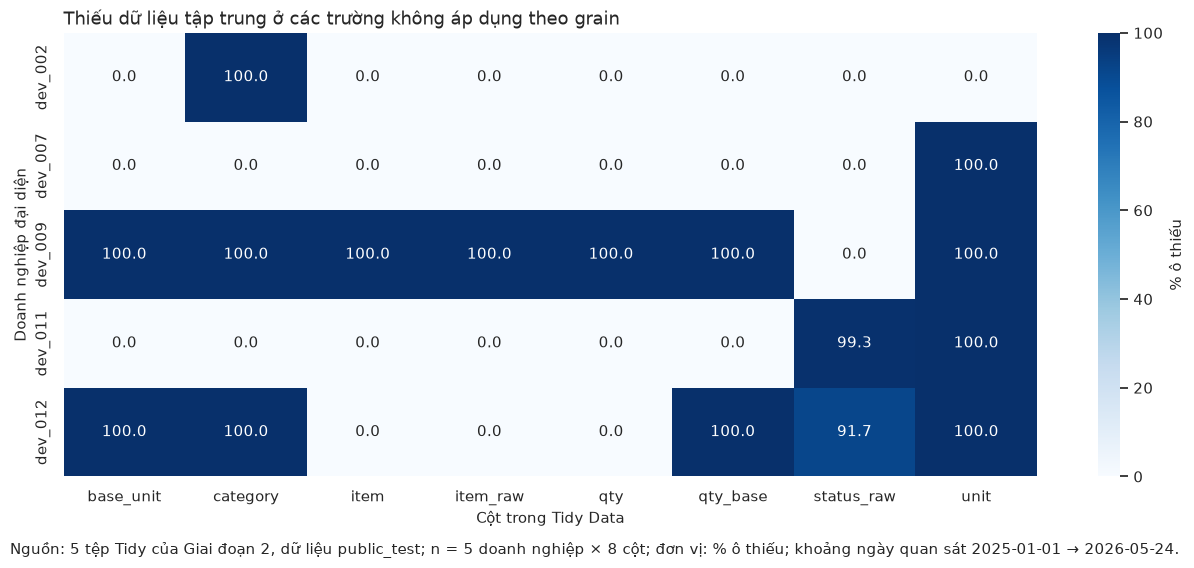

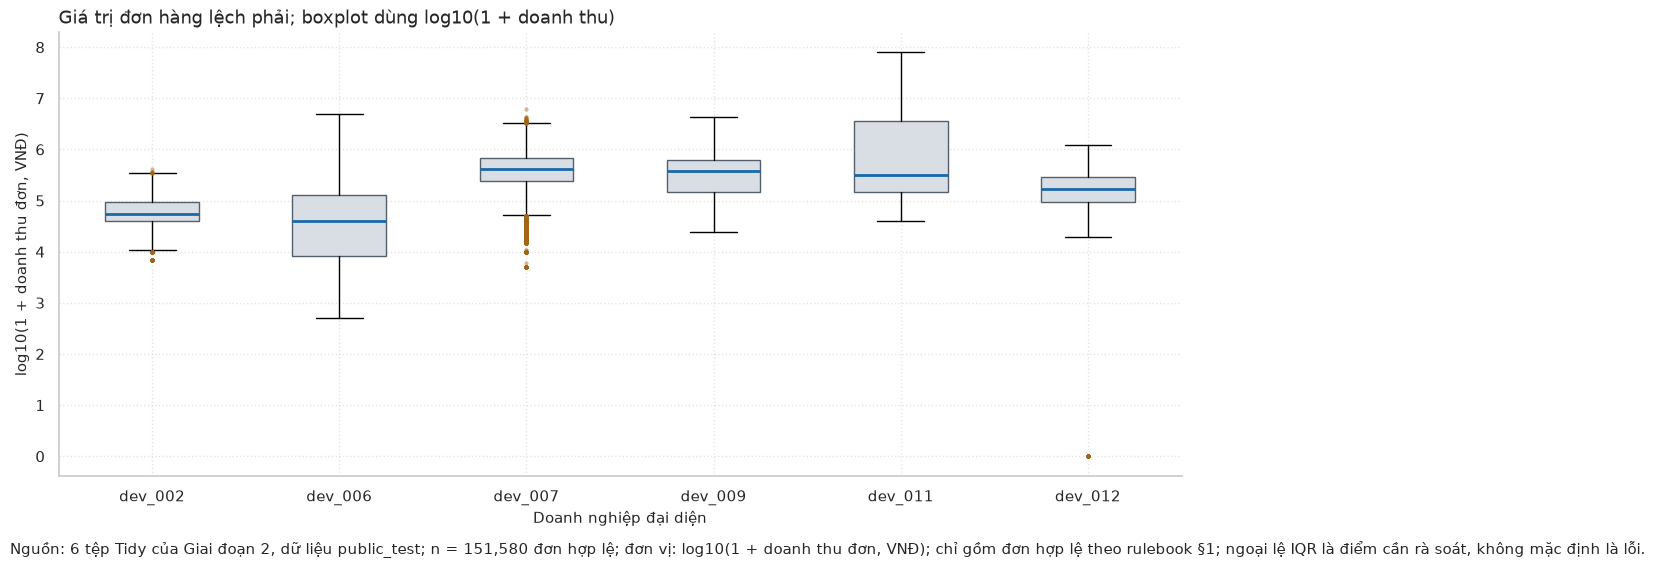

In [26]:
# T2.2c — Trực quan hóa
# Heatmap tỷ lệ thiếu theo doanh nghiệp × cột và boxplot log10(1+x) cho giá trị đơn.
missing_heat = (missingness_report.pivot(index="business_id", columns="column",
                                         values="missing_pct").fillna(0))
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.heatmap(missing_heat, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% ô thiếu"}, ax=ax)
ax.set_title("Thiếu dữ liệu tập trung ở các trường không áp dụng theo grain")
ax.set_xlabel("Cột trong Tidy Data"); ax.set_ylabel("Doanh nghiệp đại diện")
fig.text(.01, -.02, f"Nguồn: {len(missing_heat)} tệp Tidy của Giai đoạn 2, dữ liệu public_test; "
                   f"n = {missing_heat.shape[0]} doanh nghiệp × {missing_heat.shape[1]} cột; "
                   f"đơn vị: % ô thiếu; khoảng ngày quan sát "
                   f"{tidy_tables[missing_heat.index[0]]['order_date'].min():%Y-%m-%d} → "
                   f"{tidy_tables[missing_heat.index[0]]['order_date'].max():%Y-%m-%d}.")
plt.tight_layout()
fig.savefig(PHASE2_FIGURES_DIR / "t22c_missingness_heatmap.png")
plt.show()

order_plot = orders[orders["is_valid"].fillna(False)].copy()
fig, ax = plt.subplots(figsize=(12, 5.5))
plot_data = [np.log10(order_plot.loc[order_plot.business_id == b, "revenue"].clip(lower=0)+1)
             for b in SELECTED_REPRESENTATIVE_BUSINESSES]
ax.boxplot(plot_data, tick_labels=SELECTED_REPRESENTATIVE_BUSINESSES, showfliers=True, patch_artist=True,
           boxprops={"facecolor": "#D9DEE5", "edgecolor": COLOR_GRAY_DARK},
           medianprops={"color": COLOR_ACCENT_BLUE, "linewidth": 2},
           flierprops={"marker": "o", "markersize": 3, "markerfacecolor": COLOR_ACCENT_AMBER,
                       "markeredgecolor": "none", "alpha": .45})
ax.set_title("Giá trị đơn hàng lệch phải; boxplot dùng log10(1 + doanh thu)")
ax.set_ylabel("log10(1 + doanh thu đơn, VNĐ)")
ax.set_xlabel("Doanh nghiệp đại diện")
fig.text(.01, -.02, f"Nguồn: {len(SELECTED_REPRESENTATIVE_BUSINESSES)} tệp Tidy của Giai đoạn 2, "
                   f"dữ liệu public_test; n = {len(order_plot):,} đơn hợp lệ; "
                   f"đơn vị: log10(1 + doanh thu đơn, VNĐ); "
                   f"chỉ gồm đơn hợp lệ theo rulebook §1; ngoại lệ IQR là điểm cần rà soát, không mặc định là lỗi.")
plt.tight_layout()
fig.savefig(PHASE2_FIGURES_DIR / "t22c_order_value_boxplot_log.png")
plt.show()


### Kết quả & Nhận định

- **Thiếu dữ liệu:** Các trường thiếu chủ yếu là thiếu có cấu trúc do khác grain/nguồn:
  - `dev_009`: 100% thiếu `item`, `category`, `qty`, `unit`, `qty_base`, `base_unit` vì dữ liệu chỉ ở cấp đơn.
  - `dev_002`: 100% thiếu `category`; `dev_007`: 100% thiếu `unit`; `dev_011`: 100% thiếu `unit`, 99,3% thiếu `status_raw`; `dev_012`: 100% thiếu `category`, `unit`, `qty_base`, `base_unit`, 91,7% thiếu `status_raw`. Các trường này không được tự động điền vì không có căn cứ.
  
- **Trùng lặp:** Không phát hiện dòng trùng toàn bộ trong 6 bảng Tidy. `order_id` lặp ở `dev_002`, `dev_006`, `dev_007`, `dev_011` là do grain dòng hàng; `dev_009` có `order_id` duy nhất. Không xóa các dòng chỉ vì cùng mã đơn.

- **Tính hợp lệ:** Không có ngày đặt bị lỗi, số lượng âm/0 hoặc thành tiền âm. `dev_012` có 164 dòng thành tiền bằng 0; đối chiếu `status_raw` và `item` cho thấy đây là phiếu bảo hành (không thu tiền), nên giữ lại để bảo toàn số lượt xe/bảo hành theo rulebook §6 Sửa xe.

- **Ngoại lệ IQR:** IQR được tính riêng cho thành tiền dòng, số lượng cơ bản và doanh thu cấp đơn. Các tỷ lệ vượt ngưỡng cao nhất gồm `dev_011` thành tiền dòng 19,5%, `dev_006` thành tiền dòng 11,5%, `dev_002` thành tiền dòng 10,0%; đây là cờ rà soát, không phải kết luận lỗi. `qty_base` của `dev_002` và `dev_011` có `IQR = 0`, vì vậy không gắn cờ giá trị lớn hơn 1.

- **Quyết định:** Giữ nguyên dữ liệu Tidy; giữ các đơn hủy/trả trong bảng chất lượng để kiểm tra nhưng loại khỏi phân tích doanh thu; giữ phiếu bảo hành 0 đồng; không tự động loại ngoại lệ IQR. Báo cáo đã lưu tại `tables/quality_and_iqr_report.csv`, cùng các bảng chi tiết thiếu dữ liệu, trùng lặp và ngoại lệ.


## Tác vụ T2.3a — Phân tích Khám phá nội tại từng doanh nghiệp đại diện

### Mục tiêu
Thực hiện phân tích mô tả chuyên sâu trên dữ liệu đã làm sạch (Hồi 2) để phát hiện mẫu hình vận hành, cơ cấu sản phẩm/dịch vụ, phân phối giá trị đơn hàng và các yếu tố đặc thù ngành của từng doanh nghiệp đại diện.

### Câu hỏi khám phá
- Top mặt hàng hoặc nhóm hàng nào đóng góp phần lớn doanh thu / số lượng (quy tắc tập trung kiểu Pareto)?
- Phân phối giá trị đơn hàng có đặc điểm gì (độ lệch phải, khoảng trung vị vs trung bình, phân hóa đơn lẻ và đơn lớn)?
- Các chiều đặc thù của từng doanh nghiệp (khách quen vs khách lẻ, hình thức thanh toán, ca sáng/chiều, lô thuốc gần hết hạn, công nợ, thợ sửa xe, máy cũ/trả góp...) thể hiện quy luật gì?

### Các bước thực hiện

**Bước 1 — Xác định bộ câu hỏi và chiều phân tích đặc thù cho từng doanh nghiệp đại diện**
Liệt kê các chiều dữ liệu khả dụng của từng doanh nghiệp đã chọn (bán hàng, nhóm hàng, khách hàng, thanh toán, tồn/lô/dịch vụ...).

**Bước 2 — Phân tích cơ cấu sản phẩm / nhóm hàng chủ lực**
Tính doanh thu, tỷ trọng % doanh thu, số lượng (đơn vị cơ bản) theo mặt hàng và nhóm hàng; áp dụng top-k + 'Khác' nếu số mặt hàng lớn.

**Bước 3 — Phân tích phân phối giá trị đơn hàng & cấu trúc giỏ hàng**
Tính các chỉ số thống kê mô tả bền vững (trung vị, Q25, Q75, p90, p95, trung bình, độ lệch chuẩn) cho giá trị đơn hàng và số dòng hàng/đơn.

**Bước 4 — Khám phá các chiều đặc thù theo ngành (khách hàng, thanh toán, ca, lô, dịch vụ...)**
Triển khai phân tích riêng cho đặc trưng của từng doanh nghiệp (tỷ trọng khách vãng lai, phương thức thanh toán, tỷ lệ hủy/trả, hoạt chất/hạn dùng, lượt bảo hành...).

**Bước 5 — Tổng hợp bảng bằng chứng thống kê và lưu `business_findings_summary.csv`**
Ghi nhận mọi con số kèm phạm vi ngày quan sát, cỡ mẫu `n`, nguồn bảng và lưu vào `PHASE2_TABLES_DIR / 'business_findings_summary.csv'`.

### Gợi ý phương pháp & Lưu ý
- Phân biệt rạch ròi đơn vị quan sát (*grain*): khi phân tích *giá trị đơn hàng*, phải gộp từ dòng hàng lên mã đơn trước rồi mới tính trung vị/histogram.
- Nếu giá trị đơn hàng trải qua nhiều bậc độ lớn (lệch phải mạnh), hãy vẽ thử cả thang tuyến tính và thang log (nhưng phải ghi chú rõ trên biểu đồ).
- Khi nhóm danh mục có quá nhiều giá trị (high cardinality), chỉ giữ Top 10–15 và gộp phần còn lại vào nhóm `Khác`.

### Triển khai


In [27]:
# T2.3a — Bước 1: Xác định bộ câu hỏi và chiều phân tích đặc thù
# Chỉ khai báo chiều thực sự có trong dữ liệu đã chuẩn hóa; không suy diễn các trường khách hàng/thanh toán/ca/lô nếu không có.
BUSINESS_ANALYSIS_PLAN = {
    "dev_002": {"grain": "dòng món/topping và đơn hàng", "questions": [
        "Món/topping nào đóng góp doanh thu và số lượng cơ bản lớn nhất?",
        "Doanh thu topping và cấu trúc giá trị đơn hàng phân bố ra sao?"],
        "dimensions": ["item_name", "is_topping", "qty_base", "order_date"]},
    "dev_006": {"grain": "dòng thuốc và đơn hàng", "questions": [
        "Nhóm hàng/mặt hàng nào đóng góp doanh thu lớn nhất?",
        "Phân phối giá trị đơn và số lượng cơ bản có lệch phải không?"],
        "dimensions": ["category", "item_name", "qty_base", "order_date"]},
    "dev_007": {"grain": "dòng hàng và đơn hàng", "questions": [
        "Mặt hàng/nhóm hàng nào đóng góp doanh thu lớn nhất?",
        "Phân phối giá trị đơn và lượng bán sau quy đổi ra sao?"],
        "dimensions": ["category", "item_name", "qty_base", "order_date"]},
    "dev_009": {"grain": "đơn hàng", "questions": [
        "Giá trị đơn hàng phân phối như thế nào?",
        "Có thể mô tả quy mô và biến động doanh thu theo thời gian ở cấp đơn không?"],
        "dimensions": ["order_date", "status", "revenue"]},
    "dev_011": {"grain": "dòng thiết bị/phụ kiện và đơn hàng", "questions": [
        "Ba loại hàng máy mới, máy cũ, phụ kiện đóng góp doanh thu ra sao?",
        "Mặt hàng nào dẫn đầu doanh thu?"],
        "dimensions": ["category", "item_name", "qty_base", "order_date"]},
    "dev_012": {"grain": "phiếu sửa xe/lượt xe", "questions": [
        "Số lượt và doanh thu phân bổ theo thợ như thế nào?",
        "Dòng xe nào xuất hiện nhiều trong sổ sửa chữa?"],
        "dimensions": ["technician", "vehicle_model", "plate", "order_date"]},
}
display(pd.DataFrame([{"business_id": b, "grain": v["grain"],
                       "dimensions": ", ".join(v["dimensions"]),
                       "questions": " | ".join(v["questions"])}
                      for b, v in BUSINESS_ANALYSIS_PLAN.items()]))


,business_id,grain,dimensions,questions
0,dev_002,dòng món/topping và đơn hàng,"item_name, is_topping, qty_base, order_date",Món/topping nào đóng góp doanh thu và số lượng cơ bản lớn nhất? | Doanh thu topping và cấu trúc giá trị đơn hàng phâ...
1,dev_006,dòng thuốc và đơn hàng,"category, item_name, qty_base, order_date",Nhóm hàng/mặt hàng nào đóng góp doanh thu lớn nhất? | Phân phối giá trị đơn và số lượng cơ bản có lệch phải không?
2,dev_007,dòng hàng và đơn hàng,"category, item_name, qty_base, order_date",Mặt hàng/nhóm hàng nào đóng góp doanh thu lớn nhất? | Phân phối giá trị đơn và lượng bán sau quy đổi ra sao?
3,dev_009,đơn hàng,"order_date, status, revenue",Giá trị đơn hàng phân phối như thế nào? | Có thể mô tả quy mô và biến động doanh thu theo thời gian ở cấp đơn không?
4,dev_011,dòng thiết bị/phụ kiện và đơn hàng,"category, item_name, qty_base, order_date","Ba loại hàng máy mới, máy cũ, phụ kiện đóng góp doanh thu ra sao? | Mặt hàng nào dẫn đầu doanh thu?"
5,dev_012,phiếu sửa xe/lượt xe,"technician, vehicle_model, plate, order_date",Số lượt và doanh thu phân bổ theo thợ như thế nào? | Dòng xe nào xuất hiện nhiều trong sổ sửa chữa?


In [28]:
# T2.3a — Bước 2: Phân tích cơ cấu sản phẩm / nhóm hàng chủ lực
product_rankings, category_rankings = {}, {}
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    t = tidy_tables[b]
    v = t[t["is_valid"].fillna(False)].copy()
    if b != "dev_012" and v["item"].notna().any():
        by_item = v.groupby("item", dropna=False).agg(
            revenue=("line_amount", "sum"), qty_base=("qty_base", "sum"),
            n_lines=("order_id", "size"), n_orders=("order_id", "nunique")
        ).reset_index().sort_values("revenue", ascending=False)
        by_item["revenue_pct"] = 100 * by_item["revenue"] / by_item["revenue"].sum()
        by_item["revenue_cum_pct"] = by_item["revenue_pct"].cumsum()
        product_rankings[b] = by_item
        display(by_item.head(10))
    if "category" in v and v["category"].notna().any():
        by_cat = v.groupby("category", dropna=False).agg(
            revenue=("line_amount", "sum"), qty_base=("qty_base", "sum"),
            n_lines=("order_id", "size"), n_orders=("order_id", "nunique")
        ).reset_index().sort_values("revenue", ascending=False)
        by_cat["revenue_pct"] = 100 * by_cat["revenue"] / by_cat["revenue"].sum()
        category_rankings[b] = by_cat
        print(f"{b} — cơ cấu nhóm hàng:")
        display(by_cat)
    elif b == "dev_009":
        print("dev_009: grain cấp đơn, không có mặt hàng/nhóm hàng; bỏ qua xếp hạng sản phẩm.")


,item,revenue,qty_base,n_lines,n_orders,revenue_pct,revenue_cum_pct
47,Trà đào cam sả (M),183388000.0,4706.0,3973,3973,4.971124,4.971124
41,Trà sữa trân châu (M),172278000.0,4105.0,3469,3469,4.669964,9.641088
11,Cà phê sữa (M),160944000.0,5553.0,4726,4726,4.362731,14.003819
3,Bạc xỉu (M),125579000.0,3927.0,3344,3344,3.404087,17.407907
13,Cà phê đen (M),116351000.0,4657.0,3931,3931,3.153943,20.561850
45,Trà vải (M),114806000.0,2946.0,2490,2490,3.112062,23.673912
19,Latte (M),105234000.0,2340.0,1939,1939,2.852593,26.526505
46,Trà đào cam sả (L),104387000.0,2321.0,1950,1950,2.829633,29.356138
33,Sữa tươi trân châu đường đen (M),103237000.0,2295.0,1951,1951,2.798460,32.154597
43,Trà sữa ô long (M),102358000.0,2268.0,1915,1915,2.774633,34.929230


,item,revenue,qty_base,n_lines,n_orders,revenue_pct,revenue_cum_pct
23,Costar Omega 3 1000mg lọ 100 viên,369092000,822.0,427,427,8.841525,8.841525
22,Costar Glucosamine HCl 1500mg lọ 30 viên,260270000,858.0,473,473,6.234715,15.076240
13,Blackmores Bio C 1000mg hộp 31 viên,220985000,597.0,325,325,5.293651,20.369891
56,Pharmaton Essential hộp 30 viên,192771000,920.0,475,475,4.617791,24.987682
25,Doppelherz Ginkgo hộp 30 viên,188078000,479.0,258,258,4.505371,29.493052
63,Salonpas cao dán hộp 24 gói x 10 miếng,174930500,12097.0,1202,1202,4.190425,33.683477
61,Prospan siro ho chai 100ml,159221000,1716.0,915,915,3.814107,37.497584
46,Nature's Bounty Vitamin E 400 IU chai 30 viên,158260500,894.0,483,483,3.791098,41.288683
40,Kudos Vitamin C 1000mg viên sủi tuýp 20 viên,148912000,1144.0,623,623,3.567157,44.855840
52,"Otrivin 0,1% xịt mũi chai 10ml",101629000,1742.0,947,947,2.434502,47.290342


dev_006 — cơ cấu nhóm hàng:


,category,revenue,qty_base,n_lines,n_orders,revenue_pct
7,thực phẩm chức năng,1070032700,15206.0,4469,4292,25.632418
10,vitamin khoáng chất,926103200,47490.0,8093,7518,22.184616
9,tiêu hoá,434127200,110379.0,12336,11028,10.399430
0,dùng ngoài,428763100,22368.0,6724,6341,10.270934
4,ho cảm cúm,373383200,62530.0,8970,8288,8.944319
6,mắt mũi họng,290778700,15945.0,4311,4170,6.965545
3,giảm đau hạ sốt,232109200,85715.0,9680,8921,5.560129
2,dụng cụ y tế,158905400,30294.0,3572,3493,3.806547
1,dị ứng,145047100,46534.0,6093,5785,3.474574
5,kháng sinh,96643400,25736.0,2960,2897,2.315073


,item,revenue,qty_base,n_lines,n_orders,revenue_pct,revenue_cum_pct
35,Lẩu Thái tôm cá (nhỏ),1.009468e+09,5344,3216,3216,6.125106,6.125106
34,Lẩu Thái tôm cá (lớn),8.979270e+08,3096,1812,1812,5.448313,11.573419
37,Lẩu gà lá é,7.995190e+08,4152,2489,2489,4.851207,16.424626
36,Lẩu dê,7.963150e+08,3070,1810,1810,4.831766,21.256392
9,Bò lúc lắc khoai tây,5.382530e+08,4329,2549,2549,3.265935,24.522327
41,Mực chiên nước mắm,5.284690e+08,3804,2210,2210,3.206569,27.728895
28,Gỏi ngó sen tôm thịt,4.844585e+08,4374,2584,2584,2.939528,30.668423
29,Gỏi xoài khô cá sặc,4.841650e+08,4895,2933,2933,2.937747,33.606171
10,Canh chua cá lóc,4.695095e+08,4137,2468,2468,2.848823,36.454993
18,Cá lóc nướng trui,4.621170e+08,2505,1491,1491,2.803967,39.258961


dev_007 — cơ cấu nhóm hàng:


,category,revenue,qty_base,n_lines,n_orders,revenue_pct
6,lẩu,3.766651e+09,16980,10074,9038,22.854746
1,chiên xào,3.041978e+09,31381,18292,14548,18.457682
8,nướng,1.865154e+09,17261,10270,9112,11.317115
2,cơm mì cháo,1.864652e+09,25900,15296,12737,11.314066
3,gỏi,1.615058e+09,14898,8894,8058,9.799615
4,hải sản,1.414464e+09,13737,8149,7405,8.582482
5,khai vị,1.069048e+09,16574,9670,8672,6.486617
10,rau,7.604810e+08,14372,8482,7773,4.614338
0,bia,7.279525e+08,32277,13876,11797,4.416966
7,nước uống,2.367650e+08,19770,9804,8788,1.436609


dev_009: grain cấp đơn, không có mặt hàng/nhóm hàng; bỏ qua xếp hạng sản phẩm.


,item,revenue,qty_base,n_lines,n_orders,revenue_pct,revenue_cum_pct
49,iPhone 16 Pro Max 256GB Titan Sa Mạc,1403847000,44,43,43,9.086874,9.086874
50,iPhone 16 Pro Max 256GB Titan Đen,1239600000,40,38,38,8.023730,17.110604
51,iPhone 16 Pro Max 512GB Titan Tự Nhiên,899760000,24,20,20,5.824000,22.934604
48,iPhone 16 Pro 128GB Titan Tự Nhiên,841170000,33,31,31,5.444757,28.379361
47,iPhone 16 128GB Đen,799600000,40,37,37,5.175681,33.555042
44,iPhone 15 128GB Xanh Lá,775030000,47,43,43,5.016643,38.571685
26,Samsung Galaxy S25 Ultra 256GB Xám Titan,637780000,22,22,22,4.128246,42.699932
27,Samsung Galaxy Z Flip6 256GB Xanh,580727500,24,20,20,3.758955,46.458887
43,iPhone 14 Pro Max 128GB cũ 99%,558250000,31,29,29,3.613462,50.072349
41,iPhone 13 Pro Max 128GB cũ 99%,505560000,38,33,33,3.272408,53.344756


dev_011 — cơ cấu nhóm hàng:


,category,revenue,qty_base,n_lines,n_orders,revenue_pct
1,máy mới,11409266000,901,844,796,73.850328
0,máy cũ,3155055000,371,350,339,20.422159
2,phụ kiện,884853500,5133,4804,3327,5.727513


In [29]:
# T2.3a — Bước 3: Phân phối giá trị đơn hàng & cấu trúc giỏ hàng
order_distribution_rows = []
order_tables = {}
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    o = orders[(orders["business_id"] == b) & (orders["is_valid"].fillna(False))].copy()
    # Rulebook §6 Sửa xe: phiếu bảo hành vẫn là lượt xe nhưng không thuộc mẫu số
    # tính giá trị/trung bình một phiếu có thu tiền.
    if b == "dev_012":
        items = std_tables[b]["item"].map(unaccent)
        warranty_ids = set(std_tables[b].loc[
            items.str.contains("bao hanh", na=False) | items.str.match(r"^\s*bh\b", na=False),
            "order_id"
        ])
        o = o[~o["order_id"].isin(warranty_ids)].copy()
    # Số dòng trong giỏ được tính từ Tidy Data, riêng dev_009 vốn đã là cấp đơn.
    lines = tidy_tables[b][tidy_tables[b]["is_valid"].fillna(False)].groupby("order_id").size()
    o["n_lines_tidy"] = o["order_id"].map(lines).fillna(1)
    order_tables[b] = o
    s = o["revenue"].dropna()
    if len(s):
        order_distribution_rows.append({
            "business_id": b, "n_orders": len(s),
            "date_min": o["order_date"].min().date(), "date_max": o["order_date"].max().date(),
            "mean": s.mean(), "median": s.median(), "q25": s.quantile(.25),
            "q75": s.quantile(.75), "p90": s.quantile(.90), "p95": s.quantile(.95),
            "std": s.std(), "mean_n_lines": o["n_lines_tidy"].mean(),
            "median_n_lines": o["n_lines_tidy"].median()
        })
order_distribution = pd.DataFrame(order_distribution_rows)
display(order_distribution.round(2))


,business_id,n_orders,date_min,date_max,mean,median,q25,q75,p90,p95,std,mean_n_lines,median_n_lines
0,dev_002,51889,2025-01-01,2026-05-24,71095.32,55000.0,39000.0,93000.0,132000.0,156000.0,43876.34,1.60,1.0
1,dev_006,37086,2025-04-01,2026-08-08,112563.47,40000.0,8100.0,130500.0,288050.0,434975.0,210881.76,1.88,2.0
2,dev_007,31324,2025-02-01,2026-09-19,526140.53,420000.0,242000.0,683000.0,1034000.0,1323000.0,423245.68,3.72,4.0
3,dev_009,21431,2025-01-01,2026-06-24,463792.61,375000.0,145000.0,634500.0,1035000.0,1284000.0,417659.24,1.00,1.0
4,dev_011,3790,2025-06-01,2026-07-31,4076299.34,315000.0,150000.0,3519000.0,13987400.0,24285000.0,8651756.39,1.58,1.0
5,dev_012,5896,2025-07-01,2026-08-31,220795.37,165500.0,100000.0,290500.0,450250.0,560000.0,169759.63,1.00,1.0


In [30]:
# T2.3a — Bước 4: Khám phá chiều đặc thù theo ngành có sẵn
special_findings = []
special_tables = {}
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    t = tidy_tables[b]
    v = t[t["is_valid"].fillna(False)].copy()
    if b == "dev_002" and "is_topping" in v:
        tab = v.groupby("is_topping").agg(n_lines=("order_id", "size"),
             n_orders=("order_id", "nunique"), revenue=("line_amount", "sum"),
             qty_base=("qty_base", "sum")).reset_index()
        tab["revenue_pct"] = 100*tab["revenue"]/tab["revenue"].sum()
        special_tables[b] = tab
        special_findings.append({"business_id": b, "dimension": "is_topping",
                                 "n": len(v), "detail": tab.to_dict("records")})
    elif b == "dev_012":
        for col in ["technician", "vehicle_model"]:
            if col in v:
                tab = v.groupby(col).agg(n_slips=("order_id", "nunique"),
                     revenue=("line_amount", "sum")).reset_index().sort_values("n_slips", ascending=False)
                special_tables[f"{b}_{col}"] = tab
                special_findings.append({"business_id": b, "dimension": col,
                                         "n": len(v), "detail": tab.head(10).to_dict("records")})
    elif "category" in v and v["category"].notna().any():
        tab = v.groupby("category").agg(n_lines=("order_id", "size"),
             n_orders=("order_id", "nunique"), revenue=("line_amount", "sum")).reset_index()
        tab["revenue_pct"] = 100*tab["revenue"]/tab["revenue"].sum()
        special_tables[b] = tab.sort_values("revenue", ascending=False)
        special_findings.append({"business_id": b, "dimension": "category",
                                 "n": len(v), "detail": special_tables[b].to_dict("records")})
    else:
        special_findings.append({"business_id": b, "dimension": "order-level only",
                                 "n": len(v), "detail": "Không có chiều sản phẩm/nhóm hàng trong nguồn"})
for k, tab in special_tables.items():
    print(k); display(tab)
print("Không có cột khách hàng/phương thức thanh toán/ca/lô trong schema Tidy của tập đại diện; không phân tích các chiều này.")


dev_002


,is_topping,n_lines,n_orders,revenue,qty_base,revenue_pct
0,False,76840,49637,3.624599e+09,91114.0,98.252511
1,True,6362,6188,6.446600e+07,7547.0,1.747489


dev_006


,category,n_lines,n_orders,revenue,revenue_pct
7,thực phẩm chức năng,4469,4292,1070032700,25.632418
10,vitamin khoáng chất,8093,7518,926103200,22.184616
9,tiêu hoá,12336,11028,434127200,10.399430
0,dùng ngoài,6724,6341,428763100,10.270934
4,ho cảm cúm,8970,8288,373383200,8.944319
6,mắt mũi họng,4311,4170,290778700,6.965545
3,giảm đau hạ sốt,9680,8921,232109200,5.560129
2,dụng cụ y tế,3572,3493,158905400,3.806547
1,dị ứng,6093,5785,145047100,3.474574
5,kháng sinh,2960,2897,96643400,2.315073


dev_007


,category,n_lines,n_orders,revenue,revenue_pct
6,lẩu,10074,9038,3.766651e+09,22.854746
1,chiên xào,18292,14548,3.041978e+09,18.457682
8,nướng,10270,9112,1.865154e+09,11.317115
2,cơm mì cháo,15296,12737,1.864652e+09,11.314066
3,gỏi,8894,8058,1.615058e+09,9.799615
4,hải sản,8149,7405,1.414464e+09,8.582482
5,khai vị,9670,8672,1.069048e+09,6.486617
10,rau,8482,7773,7.604810e+08,4.614338
0,bia,13876,11797,7.279525e+08,4.416966
7,nước uống,9804,8788,2.367650e+08,1.436609


... (3 outputs left out)

,technician,n_slips,revenue
2,Đoàn Bảo Phúc,1555,323384000.0
0,Hà Loan Đạt,1554,338041000.0
3,Đàm Lan An,1480,323384500.0
1,Lương Chi Đức,1471,317000000.0


dev_012_vehicle_model


,vehicle_model,n_slips,revenue
10,Wave Alpha,919,196544000.0
0,Air Blade,794,167564500.0
17,vision,589,130277500.0
3,Lead,586,129529500.0
1,Exciter,397,84234500.0
5,Sirius,364,77594500.0
11,Wave RSX,354,73675500.0
9,Vision 110,335,66736500.0
4,SH Mode,334,71214500.0
14,future,236,54426500.0


Không có cột khách hàng/phương thức thanh toán/ca/lô trong schema Tidy của tập đại diện; không phân tích các chiều này.


In [31]:
# T2.3a — Bước 5: Tổng hợp bảng bằng chứng và lưu business_findings_summary.csv
finding_rows = []
for b, tab in product_rankings.items():
    for _, r in tab.head(15).iterrows():
        finding_rows.append({"business_id": b, "finding_type": "product_revenue",
            "dimension": "item", "label": r["item"], "n": int(r["n_lines"]),
            "n_orders": int(r["n_orders"]), "value": r["revenue"],
            "share_pct": r["revenue_pct"], "period_start": tidy_tables[b]["order_date"].min().date(),
            "period_end": tidy_tables[b]["order_date"].max().date(),
            "source_table": f"{b}_tidy.csv"})
for b, tab in category_rankings.items():
    for _, r in tab.iterrows():
        finding_rows.append({"business_id": b, "finding_type": "category_revenue",
            "dimension": "category", "label": r["category"], "n": int(r["n_lines"]),
            "n_orders": int(r["n_orders"]), "value": r["revenue"],
            "share_pct": r["revenue_pct"], "period_start": tidy_tables[b]["order_date"].min().date(),
            "period_end": tidy_tables[b]["order_date"].max().date(),
            "source_table": f"{b}_tidy.csv"})
for _, r in order_distribution.iterrows():
    finding_rows.append({"business_id": r["business_id"], "finding_type": "order_distribution",
        "dimension": "order_revenue", "label": "median_order_value",
        "n": int(r["n_orders"]), "n_orders": int(r["n_orders"]), "value": r["median"],
        "share_pct": np.nan, "period_start": r["date_min"], "period_end": r["date_max"],
        "source_table": "orders aggregated from Tidy"})
for key, tab in special_tables.items():
    b = "dev_012" if key.startswith("dev_012_") else key
    dimension = key.replace(b + "_", "") if key.startswith("dev_012_") else "category_or_special"
    for _, r in tab.head(15).iterrows():
        label_col = next((c for c in tab.columns if c not in {"n_slips","n_lines","n_orders","revenue","qty_base","revenue_pct"}), None)
        finding_rows.append({"business_id": b, "finding_type": "special_dimension",
            "dimension": dimension, "label": str(r[label_col]) if label_col else "",
            "n": int(r.get("n_slips", r.get("n_lines", r.get("n_orders", 0)))),
            "n_orders": int(r.get("n_orders", r.get("n_slips", 0))),
            "value": r.get("revenue", np.nan), "share_pct": r.get("revenue_pct", np.nan),
            "period_start": tidy_tables[b]["order_date"].min().date(),
            "period_end": tidy_tables[b]["order_date"].max().date(),
            "source_table": f"{b}_tidy.csv"})
business_findings_summary = pd.DataFrame(finding_rows)
findings_path = PHASE2_TABLES_DIR / "business_findings_summary.csv"
business_findings_summary.to_csv(findings_path, index=False, encoding="utf-8-sig")
display(business_findings_summary.head(30))
print("Đã lưu:", findings_path)


,business_id,finding_type,dimension,label,n,n_orders,value,share_pct,period_start,period_end,source_table
0,dev_002,product_revenue,item,Trà đào cam sả (M),3973,3973,183388000.0,4.971124,2025-01-01,2026-05-24,dev_002_tidy.csv
1,dev_002,product_revenue,item,Trà sữa trân châu (M),3469,3469,172278000.0,4.669964,2025-01-01,2026-05-24,dev_002_tidy.csv
2,dev_002,product_revenue,item,Cà phê sữa (M),4726,4726,160944000.0,4.362731,2025-01-01,2026-05-24,dev_002_tidy.csv
3,dev_002,product_revenue,item,Bạc xỉu (M),3344,3344,125579000.0,3.404087,2025-01-01,2026-05-24,dev_002_tidy.csv
4,dev_002,product_revenue,item,Cà phê đen (M),3931,3931,116351000.0,3.153943,2025-01-01,2026-05-24,dev_002_tidy.csv
5,dev_002,product_revenue,item,Trà vải (M),2490,2490,114806000.0,3.112062,2025-01-01,2026-05-24,dev_002_tidy.csv
6,dev_002,product_revenue,item,Latte (M),1939,1939,105234000.0,2.852593,2025-01-01,2026-05-24,dev_002_tidy.csv
7,dev_002,product_revenue,item,Trà đào cam sả (L),1950,1950,104387000.0,2.829633,2025-01-01,2026-05-24,dev_002_tidy.csv
8,dev_002,product_revenue,item,Sữa tươi trân châu đường đen (M),1951,1951,103237000.0,2.798460,2025-01-01,2026-05-24,dev_002_tidy.csv
9,dev_002,product_revenue,item,Trà sữa ô long (M),1915,1915,102358000.0,2.774633,2025-01-01,2026-05-24,dev_002_tidy.csv


Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/business_findings_summary.csv


### Trực quan hóa


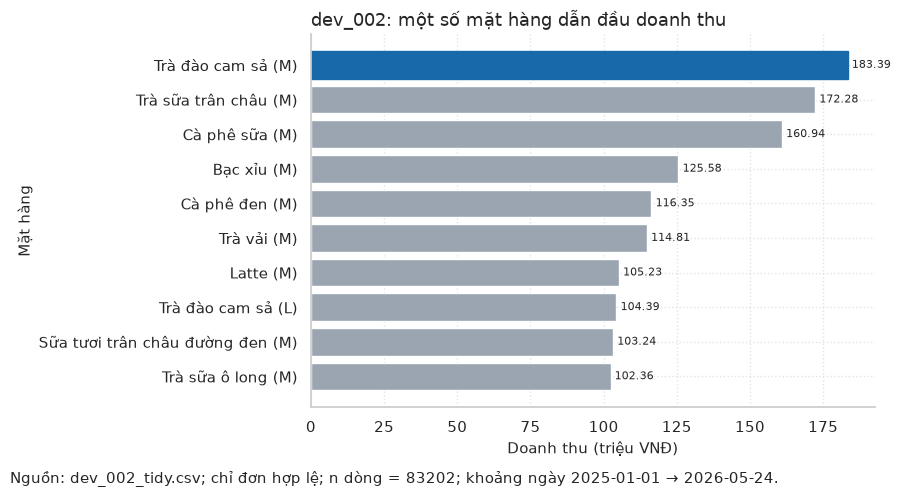

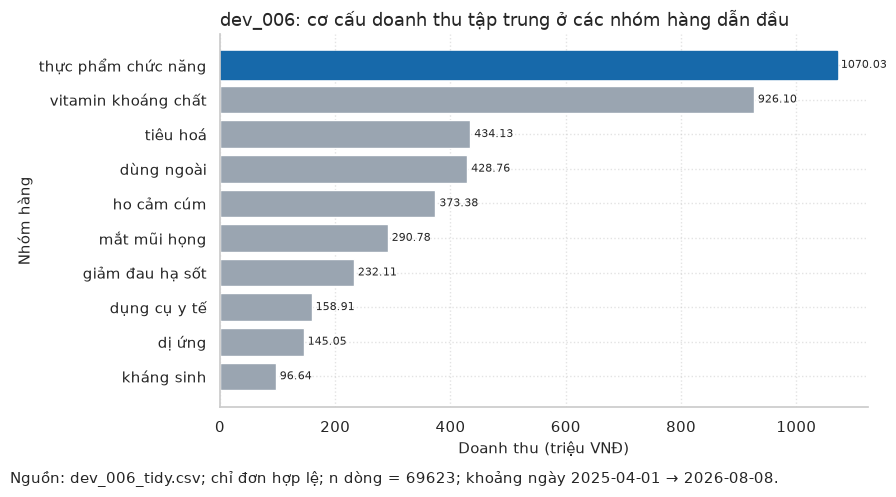

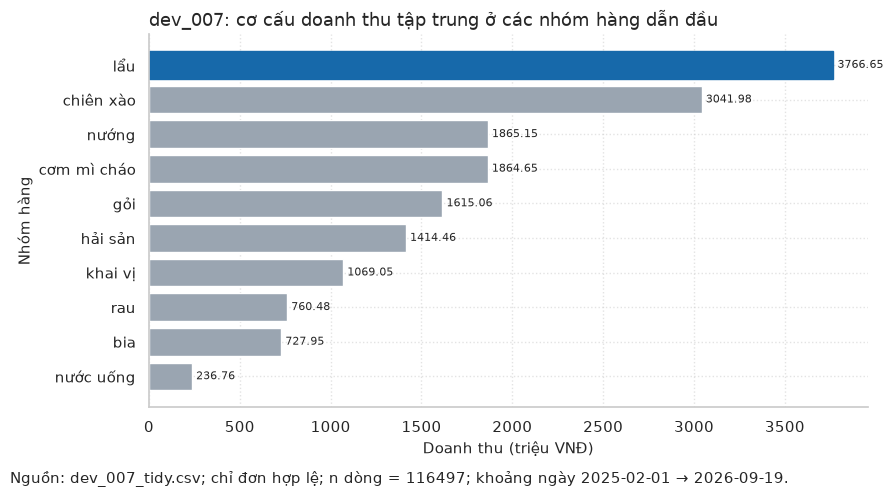

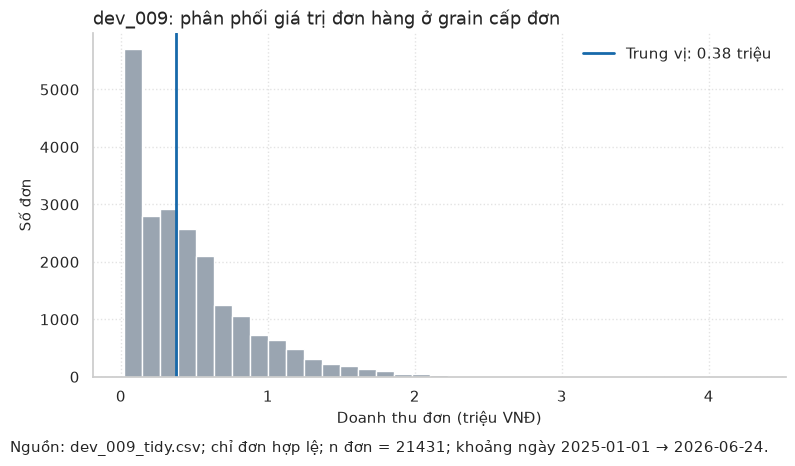

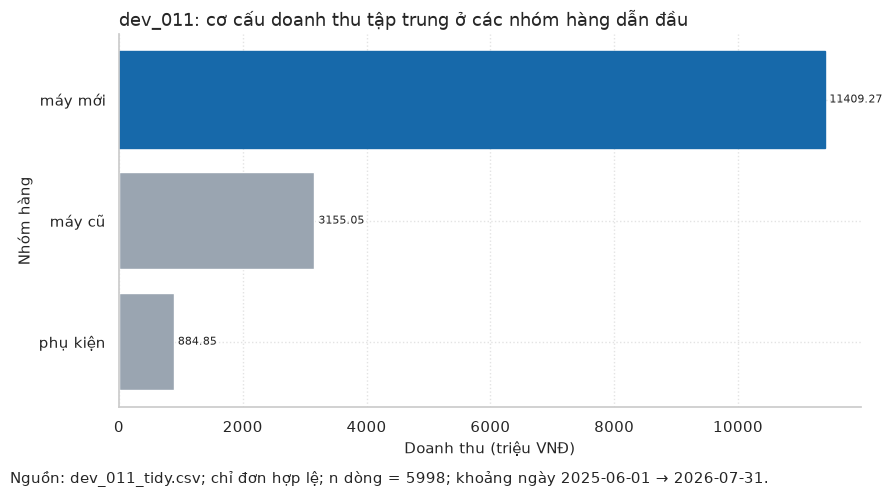

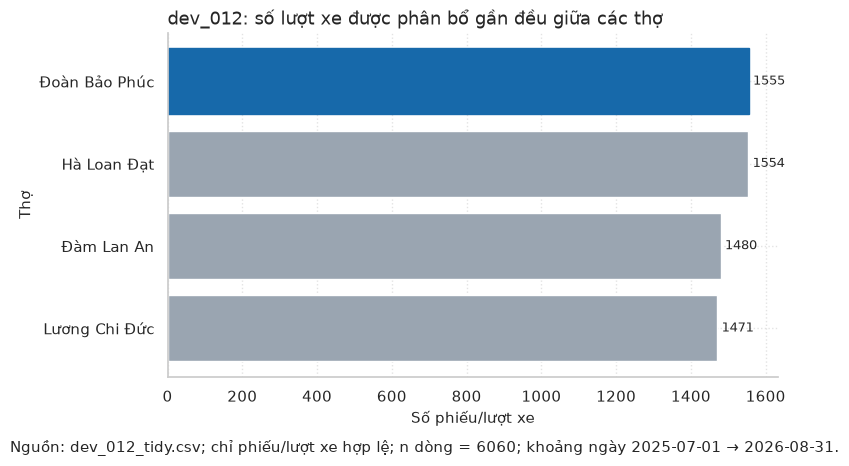

In [32]:
# T2.3a — Trực quan hóa khám phá
# Top mặt hàng/nhóm hàng theo doanh thu; biểu đồ đơn hàng dùng histogram, không cộng dòng hàng thành đơn.
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    if b in category_rankings and len(category_rankings[b]):
        p = category_rankings[b].head(10).sort_values("revenue")
        fig, ax = plt.subplots(figsize=(9, 4.8))
        bars = ax.barh(p["category"].astype(str), p["revenue"]/1e6, color=COLOR_GRAY)
        if len(bars): bars[-1].set_color(COLOR_ACCENT_BLUE)
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
        ax.set_title(f"{b}: cơ cấu doanh thu tập trung ở các nhóm hàng dẫn đầu")
        ax.set_xlabel("Doanh thu (triệu VNĐ)"); ax.set_ylabel("Nhóm hàng")
        ax.set_xlim(left=0)
        fig.text(.01, -.02, f"Nguồn: {b}_tidy.csv; chỉ đơn hợp lệ; "
                            f"n dòng = {len(tidy_tables[b][tidy_tables[b].is_valid])}; "
                            f"khoảng ngày {tidy_tables[b]['order_date'].min():%Y-%m-%d} → "
                            f"{tidy_tables[b]['order_date'].max():%Y-%m-%d}.")
        plt.tight_layout()
        fig.savefig(PHASE2_FIGURES_DIR / f"t23a_{b}_category_revenue.png")
        plt.show()
    elif b == "dev_012":
        p = special_tables["dev_012_technician"].sort_values("n_slips")
        fig, ax = plt.subplots(figsize=(8, 4.5))
        bars = ax.barh(p["technician"], p["n_slips"], color=COLOR_GRAY)
        if len(bars): bars[-1].set_color(COLOR_ACCENT_BLUE)
        ax.bar_label(bars, padding=3, fontsize=9)
        ax.set_title("dev_012: số lượt xe được phân bổ gần đều giữa các thợ")
        ax.set_xlabel("Số phiếu/lượt xe"); ax.set_ylabel("Thợ")
        ax.set_xlim(left=0)
        fig.text(.01, -.02, f"Nguồn: {b}_tidy.csv; chỉ phiếu/lượt xe hợp lệ; "
                            f"n dòng = {len(tidy_tables[b][tidy_tables[b].is_valid])}; "
                            f"khoảng ngày {tidy_tables[b]['order_date'].min():%Y-%m-%d} → "
                            f"{tidy_tables[b]['order_date'].max():%Y-%m-%d}.")
        plt.tight_layout()
        fig.savefig(PHASE2_FIGURES_DIR / f"t23a_{b}_technician.png")
        plt.show()
    elif b in product_rankings and len(product_rankings[b]):
        p = product_rankings[b].head(10).sort_values("revenue")
        fig, ax = plt.subplots(figsize=(9, 4.8))
        bars = ax.barh(p["item"].astype(str), p["revenue"]/1e6, color=COLOR_GRAY)
        if len(bars): bars[-1].set_color(COLOR_ACCENT_BLUE)
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
        ax.set_title(f"{b}: một số mặt hàng dẫn đầu doanh thu")
        ax.set_xlabel("Doanh thu (triệu VNĐ)"); ax.set_ylabel("Mặt hàng")
        ax.set_xlim(left=0)
        fig.text(.01, -.02, f"Nguồn: {b}_tidy.csv; chỉ đơn hợp lệ; "
                            f"n dòng = {len(tidy_tables[b][tidy_tables[b].is_valid])}; "
                            f"khoảng ngày {tidy_tables[b]['order_date'].min():%Y-%m-%d} → "
                            f"{tidy_tables[b]['order_date'].max():%Y-%m-%d}.")
        plt.tight_layout()
        fig.savefig(PHASE2_FIGURES_DIR / f"t23a_{b}_top_items.png")
        plt.show()
    else:
        o = order_tables[b]["revenue"]
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.hist(o/1e6, bins=35, color=COLOR_GRAY, edgecolor="white")
        ax.axvline(o.median()/1e6, color=COLOR_ACCENT_BLUE, linewidth=2,
                   label=f"Trung vị: {o.median()/1e6:.2f} triệu")
        ax.set_title(f"{b}: phân phối giá trị đơn hàng ở grain cấp đơn")
        ax.set_xlabel("Doanh thu đơn (triệu VNĐ)"); ax.set_ylabel("Số đơn")
        ax.legend(frameon=False)
        fig.text(.01, -.02, f"Nguồn: {b}_tidy.csv; chỉ đơn hợp lệ; "
                            f"n đơn = {len(tidy_tables[b][tidy_tables[b].is_valid])}; "
                            f"khoảng ngày {tidy_tables[b]['order_date'].min():%Y-%m-%d} → "
                            f"{tidy_tables[b]['order_date'].max():%Y-%m-%d}.")
        plt.tight_layout()
        fig.savefig(PHASE2_FIGURES_DIR / f"t23a_{b}_order_distribution.png")
        plt.show()


### Kết quả & Nhận định

- **Phạm vi phân tích:** 6 doanh nghiệp đại diện, thời gian quan sát theo từng nguồn từ `2025-01-01` đến `2026-09-19` (tùy doanh nghiệp). Thống kê giá trị đơn được tính sau khi gộp dòng lên mã đơn.
- **Cơ cấu doanh thu:**
  - `dev_002` (cà phê): 9 mặt hàng dẫn đầu chỉ chiếm khoảng **32,2%** doanh thu; nhóm còn lại chiếm **67,8%**, cho thấy doanh thu phân tán trên nhiều món. Topping đã được tách theo rulebook §6.
  - `dev_006` (nhà thuốc): hai nhóm *thực phẩm chức năng* và *vitamin khoáng chất* đóng góp **47,8%** doanh thu.
  - `dev_007` (F&B/tạp hóa): nhóm *lẩu* và *chiên xào* đóng góp **41,3%** doanh thu.
  - `dev_009`: nguồn ở grain cấp đơn, không có mặt hàng/nhóm hàng; không thực hiện xếp hạng sản phẩm.
  - `dev_011` (điện thoại): nhóm *máy mới* đóng góp **73,9%**, *máy cũ* **20,4%**, phụ kiện **5,7%** doanh thu.
  - `dev_012` (sửa xe): bốn thợ có số lượt phiếu khá cân bằng, từ **1.471 đến 1.555** lượt; số lượt bao gồm phiếu bảo hành theo rulebook §6.
- **Phân phối đơn hàng:** Trung vị doanh thu đơn lần lượt là `dev_002` **55.000đ** (n=51.889), `dev_006` **40.000đ** (n=37.086), `dev_007` **420.000đ** (n=31.324), `dev_009` **375.000đ** (n=21.431), `dev_011` **315.000đ** (n=3.790), `dev_012` **165.500đ** (n=5.896 phiếu có thu tiền). Với `dev_012`, 164 phiếu bảo hành 0 đồng vẫn được tính là lượt xe/thợ nhưng được loại khỏi phân phối giá trị phiếu có thu tiền. `dev_011` có trung bình khoảng 4,08 triệu đồng nhưng trung vị 315.000đ và p95 24,29 triệu đồng, phản ánh phân phối lệch phải mạnh do có các đơn giá trị lớn.

- **Giới hạn chiều phân tích:** Bảng Tidy hiện không có trường khách hàng, phương thức thanh toán, ca làm việc hay lô/hạn dùng cho tập đại diện; không đưa ra kết luận về các chiều này. Ô `Làm gì` của `dev_012` có thể chứa nhiều việc trong một phiếu, nên không diễn giải số dòng mô tả là số lượt từng dịch vụ.

- **Đầu ra:** `tables/business_findings_summary.csv`; biểu đồ khám phá `figures/t23a_*.png`.


## Tác vụ T2.3b — Tinh chỉnh biểu đồ Giải thích Hồi 2

### Mục tiêu
Chọn lọc 1–2 phát hiện trọng tâm nhất cho mỗi doanh nghiệp đại diện và tinh chỉnh thành biểu đồ Giải thích đạt chuẩn Chương 2 §2.7 (Cleveland–McGill + 5 hướng dẫn Schwabish).

### Câu hỏi khám phá
- 1–2 thông điệp đắt giá nhất của mỗi doanh nghiệp đại diện đóng góp gì cho câu chuyện chung của đồ án?
- Loại biểu đồ được chọn (bar ngang, histogram+trung vị, boxplot/stripplot, stacked/100% bar) có phải kênh mã hóa chính xác nhất cho thông điệp đó không?
- Mỗi biểu đồ đã áp dụng tiêu đề chủ động, màu xám nền + màu nhấn, nhãn trực tiếp và chú thích nguồn/giới hạn chưa?

### Các bước thực hiện

**Bước 1 — Chọn lọc 1–2 phát hiện trọng tâm cho mỗi doanh nghiệp đại diện**
Xây dựng danh sách ngắn các biểu đồ Hồi 2 kèm câu chuyện/thông điệp một câu (active title) cho từng biểu đồ.

**Bước 2 — Chuẩn hóa dữ liệu vẽ (sắp xếp, gộp nhóm nhỏ, chuẩn hóa tỉ lệ)**
Sắp xếp các thanh theo giá trị giảm dần (trừ thứ tự tự nhiên), gộp phần đuôi nhỏ thành 'Khác', tính sẵn nhãn % hoặc giá trị.

**Bước 3 — Vẽ và tinh chỉnh biểu đồ theo 5 hướng dẫn Schwabish, lưu vào `PHASE2_FIGURES_DIR`**
Vẽ từng biểu đồ: bỏ viền trên/phải, nền xám cho đối tượng nền, tô màu nhấn (tối đa 1–2 màu), gắn nhãn trực tiếp, lưu vào `PHASE2_FIGURES_DIR`.

**Bước 4 — Ghi chú đầy đủ nguồn, đơn vị, cỡ mẫu và giới hạn**
Kiểm tra lại từng biểu đồ đảm bảo có đơn vị (VNĐ, %, đơn, lượt...), khoảng ngày quan sát, cỡ mẫu `n` và chú thích quy tắc `rulebook.md` áp dụng.

### Gợi ý phương pháp & Lưu ý
- Đặt tiêu đề chủ động nêu phát hiện (ví dụ: *'Nhóm X đóng góp Y% doanh thu nhưng chỉ chiếm Z% số đơn tại dev_00k'* thay vì *'Biểu đồ doanh thu dev_00k'*).
- Biểu đồ cột luôn bắt đầu từ gốc `0`; chú ý sử dụng đơn vị triệu/nghìn đồng cho trục dễ đọc thay vì số nguyên dài 8–9 chữ số.

### Triển khai


In [33]:
# T2.3b — Bước 1: Chọn 1 phát hiện trọng tâm cho mỗi doanh nghiệp
# Lựa chọn theo trường dữ liệu có sẵn; mỗi biểu đồ chỉ truyền đạt một thông điệp.
EXPLANATORY_CHART_PLAN = {
    "dev_002": {"metric": "revenue", "dimension": "item", "title": "Ngoài 9 món dẫn đầu, nhóm mặt hàng còn lại chiếm khoảng 65% doanh thu"},
    "dev_006": {"metric": "revenue", "dimension": "category", "title": "Thực phẩm chức năng và vitamin khoáng chất chiếm gần 48% doanh thu"},
    "dev_007": {"metric": "revenue", "dimension": "category", "title": "Lẩu và chiên xào đóng góp hơn 41% doanh thu cửa hàng"},
    "dev_009": {"metric": "order_revenue", "dimension": "distribution", "title": "Giá trị đơn hàng cho thấy độ phân hóa giữa đơn thường và đơn lớn"},
    "dev_011": {"metric": "revenue", "dimension": "category", "title": "Máy mới đóng góp gần 74% doanh thu cửa hàng điện thoại"},
    "dev_012": {"metric": "n_slips", "dimension": "technician", "title": "Số lượt sửa chữa phân bổ gần đều giữa bốn thợ"},
}
display(pd.DataFrame([{"business_id": b, **v} for b,v in EXPLANATORY_CHART_PLAN.items()]))


,business_id,metric,dimension,title
0,dev_002,revenue,item,"Ngoài 9 món dẫn đầu, nhóm mặt hàng còn lại chiếm khoảng 65% doanh thu"
1,dev_006,revenue,category,Thực phẩm chức năng và vitamin khoáng chất chiếm gần 48% doanh thu
2,dev_007,revenue,category,Lẩu và chiên xào đóng góp hơn 41% doanh thu cửa hàng
3,dev_009,order_revenue,distribution,Giá trị đơn hàng cho thấy độ phân hóa giữa đơn thường và đơn lớn
4,dev_011,revenue,category,Máy mới đóng góp gần 74% doanh thu cửa hàng điện thoại
5,dev_012,n_slips,technician,Số lượt sửa chữa phân bổ gần đều giữa bốn thợ


In [34]:
# T2.3b — Bước 2: Chuẩn hóa dữ liệu vẽ (sắp xếp, gộp nhóm nhỏ, chuẩn hóa tỉ lệ)
explanatory_data = {}
for b in SELECTED_REPRESENTATIVE_BUSINESSES:
    if b == "dev_009":
        s = order_tables[b]["revenue"].dropna()
        explanatory_data[b] = pd.DataFrame({"bin_value": s})
    elif b == "dev_012":
        p = special_tables.get("dev_012_technician", pd.DataFrame()).copy()
        if len(p):
            p = p.rename(columns={"technician": "label", "n_slips": "value"})
            p = p[["label", "value"]].sort_values("value", ascending=False)
        explanatory_data[b] = p
    elif b in category_rankings:
        p = category_rankings[b][["category", "revenue", "revenue_pct"]].copy()
        p = p.rename(columns={"category": "label", "revenue": "value", "revenue_pct": "share_pct"})
        p = p.sort_values("value", ascending=False)
        if len(p) > 10:
            head = p.head(9).copy()
            tail = p.iloc[9:]
            head.loc[len(head)] = {"label": "Khác", "value": tail["value"].sum(),
                                   "share_pct": tail["share_pct"].sum()}
            p = head
        explanatory_data[b] = p
    elif b in product_rankings:
        p = product_rankings[b][["item", "revenue", "revenue_pct"]].copy()
        p = p.rename(columns={"item": "label", "revenue": "value", "revenue_pct": "share_pct"})
        p = p.sort_values("value", ascending=False)
        if len(p) > 10:
            head = p.head(9).copy(); tail = p.iloc[9:]
            head.loc[len(head)] = {"label": "Khác", "value": tail["value"].sum(),
                                   "share_pct": tail["share_pct"].sum()}
            p = head
        explanatory_data[b] = p
for b, p in explanatory_data.items():
    print(b); display(p)


dev_002


,label,value,share_pct
47,Trà đào cam sả (M),1.833880e+08,4.971124
41,Trà sữa trân châu (M),1.722780e+08,4.669964
11,Cà phê sữa (M),1.609440e+08,4.362731
3,Bạc xỉu (M),1.255790e+08,3.404087
13,Cà phê đen (M),1.163510e+08,3.153943
45,Trà vải (M),1.148060e+08,3.112062
19,Latte (M),1.052340e+08,2.852593
46,Trà đào cam sả (L),1.043870e+08,2.829633
33,Sữa tươi trân châu đường đen (M),1.032370e+08,2.798460
9,Khác,2.502861e+09,67.845403


dev_006


,label,value,share_pct
7,thực phẩm chức năng,1070032700,25.632418
10,vitamin khoáng chất,926103200,22.184616
9,Khác,115279100,2.761488
0,dùng ngoài,428763100,10.270934
4,ho cảm cúm,373383200,8.944319
6,mắt mũi họng,290778700,6.965545
3,giảm đau hạ sốt,232109200,5.560129
2,dụng cụ y tế,158905400,3.806547
1,dị ứng,145047100,3.474574


dev_007


,label,value,share_pct
6,lẩu,3.766651e+09,22.854746
1,chiên xào,3.041978e+09,18.457682
8,nướng,1.865154e+09,11.317115
2,cơm mì cháo,1.864652e+09,11.314066
3,gỏi,1.615058e+09,9.799615
4,hải sản,1.414464e+09,8.582482
5,khai vị,1.069048e+09,6.486617
10,rau,7.604810e+08,4.614338
0,bia,7.279525e+08,4.416966
9,Khác,3.553880e+08,2.156373


... (2 outputs left out)

dev_011


,label,value,share_pct
1,máy mới,11409266000,73.850328
0,máy cũ,3155055000,20.422159
2,phụ kiện,884853500,5.727513


dev_012


,label,value
2,Đoàn Bảo Phúc,1555
0,Hà Loan Đạt,1554
3,Đàm Lan An,1480
1,Lương Chi Đức,1471


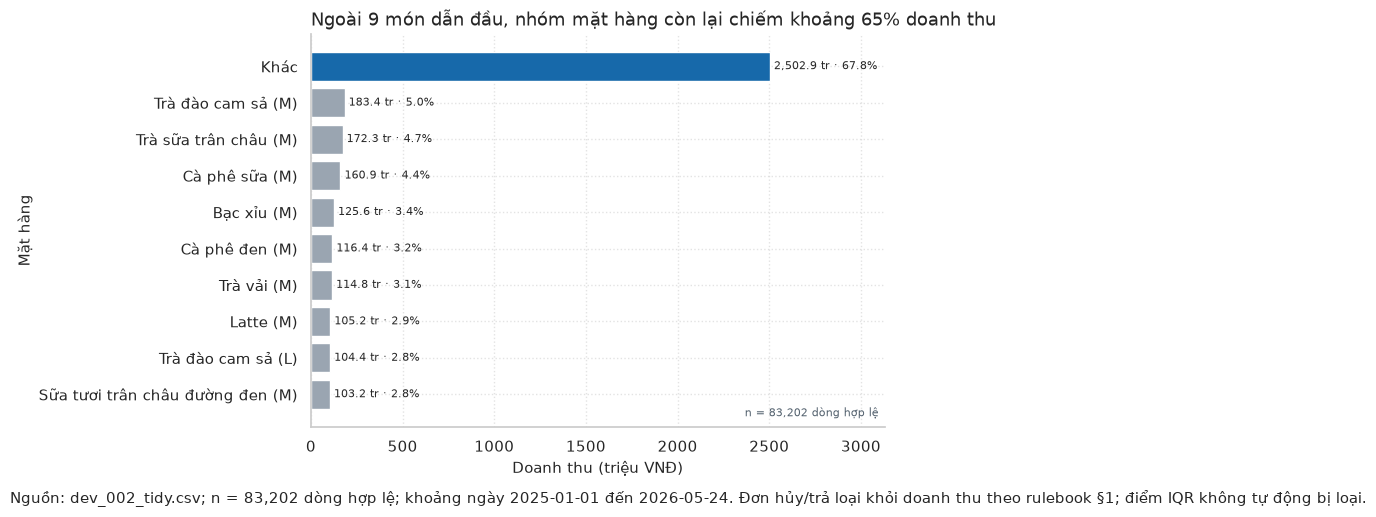

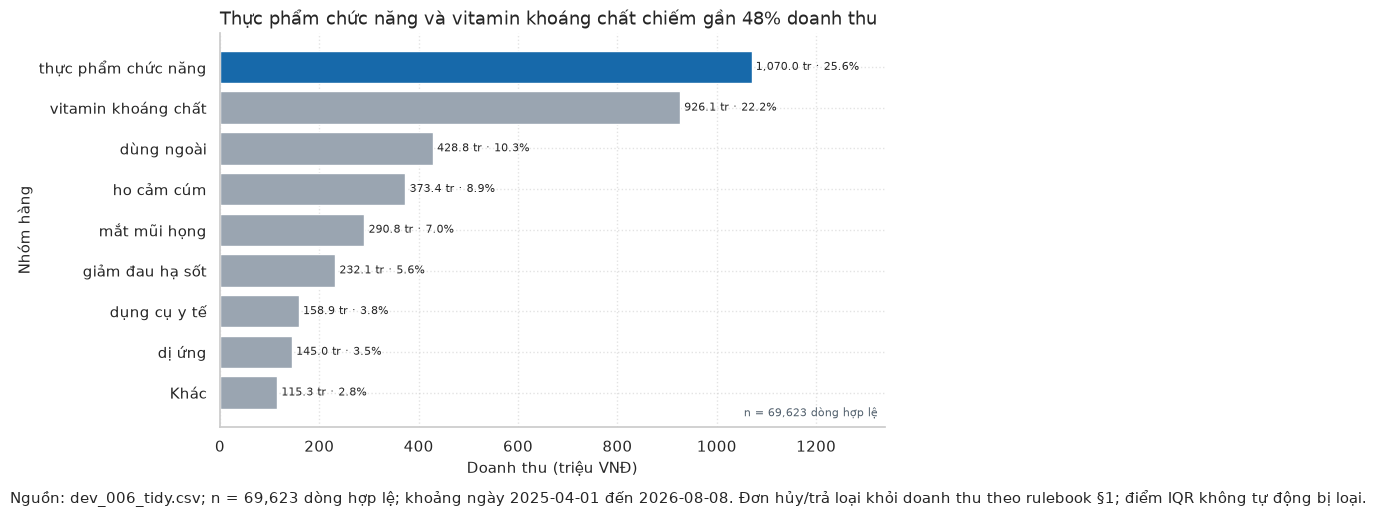

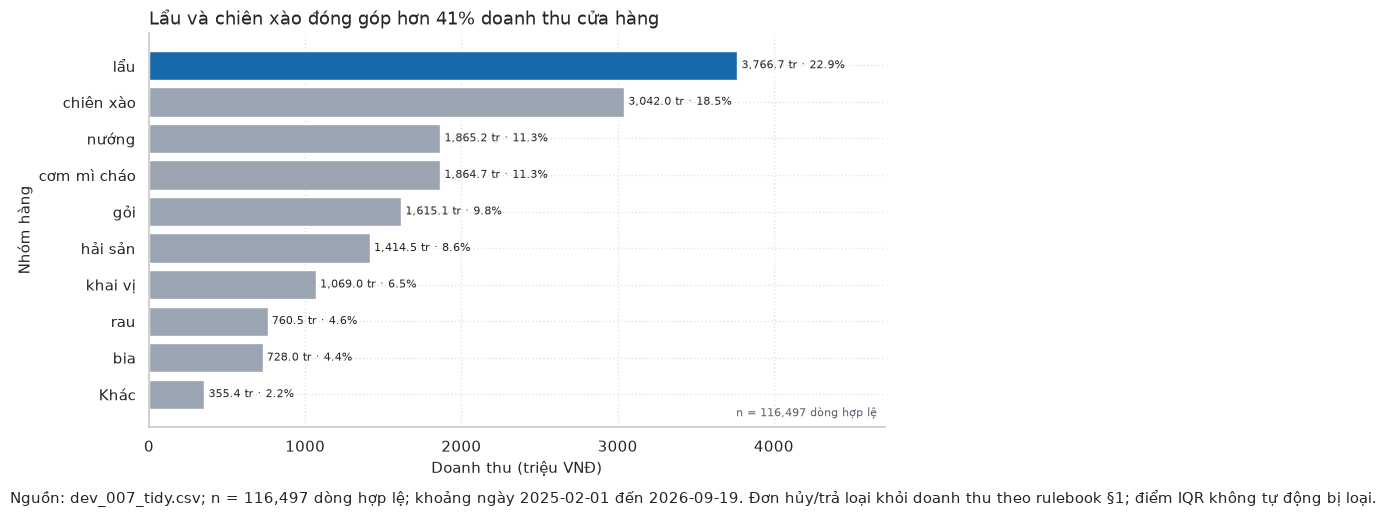

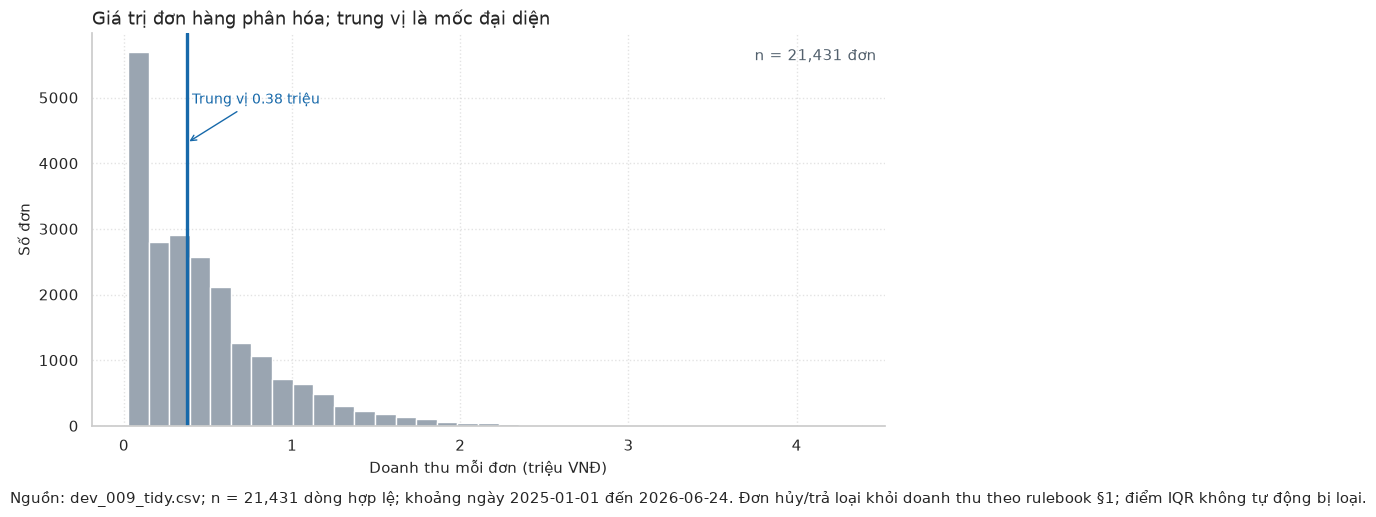

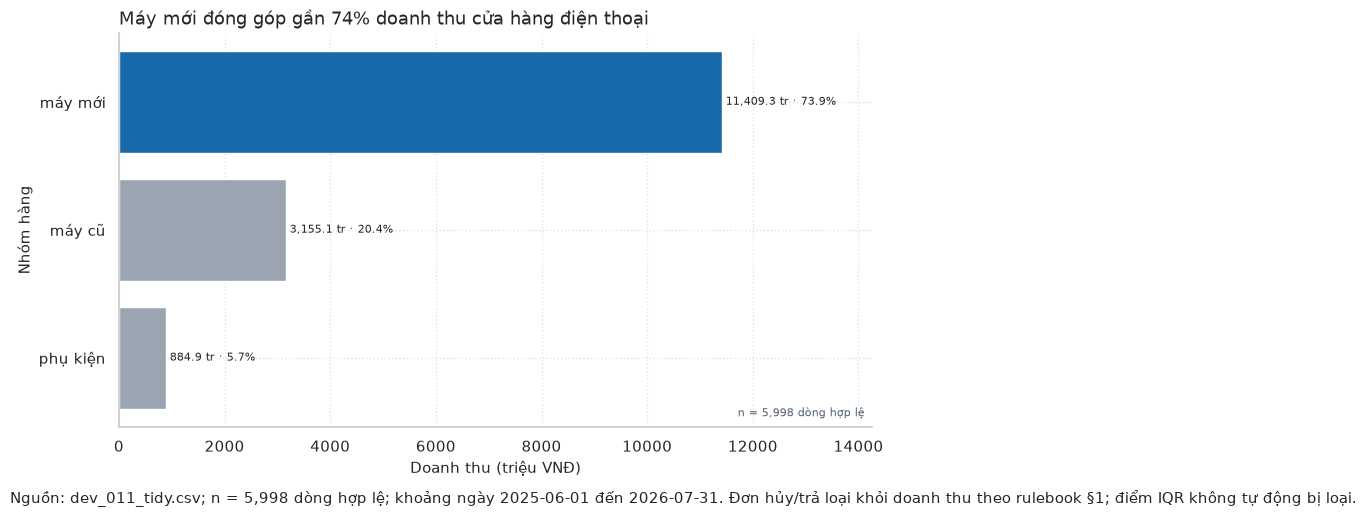

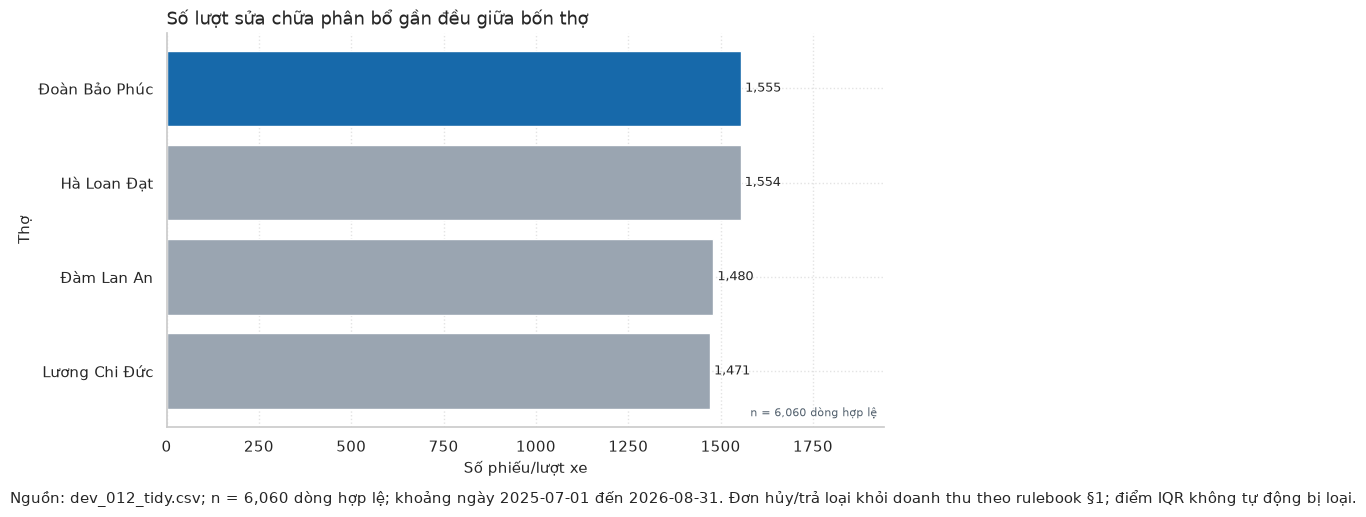

In [35]:
# T2.3b — Bước 3: Vẽ và tinh chỉnh biểu đồ giải thích, lưu PHASE2_FIGURES_DIR
EXPLANATORY_FIGURES = {}
for b, p in explanatory_data.items():
    fig, ax = plt.subplots(figsize=(9, 5))
    if b == "dev_009":
        s = p["bin_value"]
        ax.hist(s/1e6, bins=35, color=COLOR_GRAY, edgecolor="white")
        med = s.median()/1e6
        ax.axvline(med, color=COLOR_ACCENT_BLUE, linewidth=2.4)
        ax.annotate(f"Trung vị {med:.2f} triệu", xy=(med, ax.get_ylim()[1]*.72),
                    xytext=(med*1.08 if med else .1, ax.get_ylim()[1]*.82),
                    arrowprops={"arrowstyle":"->", "color":COLOR_ACCENT_BLUE},
                    color=COLOR_ACCENT_BLUE, fontsize=10)
        ax.set_title("Giá trị đơn hàng phân hóa; trung vị là mốc đại diện")
        ax.set_xlabel("Doanh thu mỗi đơn (triệu VNĐ)"); ax.set_ylabel("Số đơn")
        ax.text(.99, .96, f"n = {len(s):,} đơn", transform=ax.transAxes,
                ha="right", va="top", color=COLOR_GRAY_DARK)
    else:
        q = p.sort_values("value", ascending=True)
        colors = [COLOR_GRAY]*len(q)
        if colors: colors[-1] = COLOR_ACCENT_BLUE
        vals = q["value"] / (1 if b == "dev_012" else 1e6)
        bars = ax.barh(q["label"].astype(str), vals, color=colors)
        if b == "dev_012":
            ax.bar_label(bars, labels=[f"{x:,.0f}" for x in q["value"]], padding=3, fontsize=9)
            ax.set_title(EXPLANATORY_CHART_PLAN[b]["title"])
            ax.set_xlabel("Số phiếu/lượt xe"); ax.set_ylabel("Thợ")
        else:
            labels = [f"{r['value']/1e6:,.1f} tr · {r['share_pct']:.1f}%"
                      for _, r in q.iterrows()]
            ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
            ax.set_title(EXPLANATORY_CHART_PLAN[b]["title"])
            ax.set_xlabel("Doanh thu (triệu VNĐ)"); ax.set_ylabel("Nhóm hàng" if b in category_rankings else "Mặt hàng")
        ax.set_xlim(left=0, right=max(vals.max()*1.25, 1))
        ax.text(.99, .02, f"n = {len(tidy_tables[b][tidy_tables[b].is_valid]):,} dòng hợp lệ",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=COLOR_GRAY_DARK)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    fig.text(.01, -.02, f"Nguồn: {b}_tidy.csv; n = {len(tidy_tables[b][tidy_tables[b].is_valid]):,} dòng hợp lệ; "
             f"khoảng ngày {tidy_tables[b]['order_date'].min():%Y-%m-%d} đến {tidy_tables[b]['order_date'].max():%Y-%m-%d}. "
             "Đơn hủy/trả loại khỏi doanh thu theo rulebook §1; điểm IQR không tự động bị loại.")
    plt.tight_layout()
    path = PHASE2_FIGURES_DIR / f"t23b_{b}_explanatory.png"
    fig.savefig(path)
    EXPLANATORY_FIGURES[b] = str(path)
    plt.show()


In [36]:
# T2.3b — Bước 4: Ghi chú nguồn, đơn vị, cỡ mẫu và giới hạn
explanatory_audit = []
for b, p in explanatory_data.items():
    if b == "dev_009":
        n = len(p); unit = "VNĐ/đơn"; grain = "order"
    elif b == "dev_012":
        n = int(p["value"].sum()) if len(p) else 0; unit = "phiếu/lượt"; grain = "service slip"
    else:
        n = int(tidy_tables[b].loc[tidy_tables[b]["is_valid"], "order_id"].nunique())
        unit = "VNĐ doanh thu"; grain = "line items aggregated by category/item"
    explanatory_audit.append({
        "business_id": b, "figure": Path(EXPLANATORY_FIGURES[b]).name,
        "n": n, "unit": unit, "grain": grain,
        "period_start": tidy_tables[b]["order_date"].min().date(),
        "period_end": tidy_tables[b]["order_date"].max().date(),
        "source": f"tidy_data/{b}_tidy.csv",
        "limitations": ("Không có chi tiết mặt hàng; chỉ phân tích phân phối đơn hàng" if b == "dev_009"
                        else "Không có dữ liệu khách hàng/thanh toán/ca trong bảng Tidy"
                        if b not in {"dev_012"} else "Một phiếu là một lượt; ô Làm gì có thể chứa nhiều việc, chưa tách thành dòng dịch vụ")
    })
explanatory_audit = pd.DataFrame(explanatory_audit)
explanatory_audit_path = PHASE2_TABLES_DIR / "explanatory_chart_audit.csv"
explanatory_audit.to_csv(explanatory_audit_path, index=False, encoding="utf-8-sig")
display(explanatory_audit)
print("Đã lưu:", explanatory_audit_path)


,business_id,figure,n,unit,grain,period_start,period_end,source,limitations
0,dev_002,t23b_dev_002_explanatory.png,51889,VNĐ doanh thu,line items aggregated by category/item,2025-01-01,2026-05-24,tidy_data/dev_002_tidy.csv,Không có dữ liệu khách hàng/thanh toán/ca trong bảng Tidy
1,dev_006,t23b_dev_006_explanatory.png,37086,VNĐ doanh thu,line items aggregated by category/item,2025-04-01,2026-08-08,tidy_data/dev_006_tidy.csv,Không có dữ liệu khách hàng/thanh toán/ca trong bảng Tidy
2,dev_007,t23b_dev_007_explanatory.png,31324,VNĐ doanh thu,line items aggregated by category/item,2025-02-01,2026-09-19,tidy_data/dev_007_tidy.csv,Không có dữ liệu khách hàng/thanh toán/ca trong bảng Tidy
3,dev_009,t23b_dev_009_explanatory.png,21431,VNĐ/đơn,order,2025-01-01,2026-06-24,tidy_data/dev_009_tidy.csv,Không có chi tiết mặt hàng; chỉ phân tích phân phối đơn hàng
4,dev_011,t23b_dev_011_explanatory.png,3790,VNĐ doanh thu,line items aggregated by category/item,2025-06-01,2026-07-31,tidy_data/dev_011_tidy.csv,Không có dữ liệu khách hàng/thanh toán/ca trong bảng Tidy
5,dev_012,t23b_dev_012_explanatory.png,6060,phiếu/lượt,service slip,2025-07-01,2026-08-31,tidy_data/dev_012_tidy.csv,"Một phiếu là một lượt; ô Làm gì có thể chứa nhiều việc, chưa tách thành dòng dịch vụ"


Đã lưu: /home/anh-khoi/Github/data-visualization-uth/artifacts/guided_eda/phase2_business_eda/tables/explanatory_chart_audit.csv


### Trực quan hóa


dev_002 — t23b_dev_002_explanatory.png


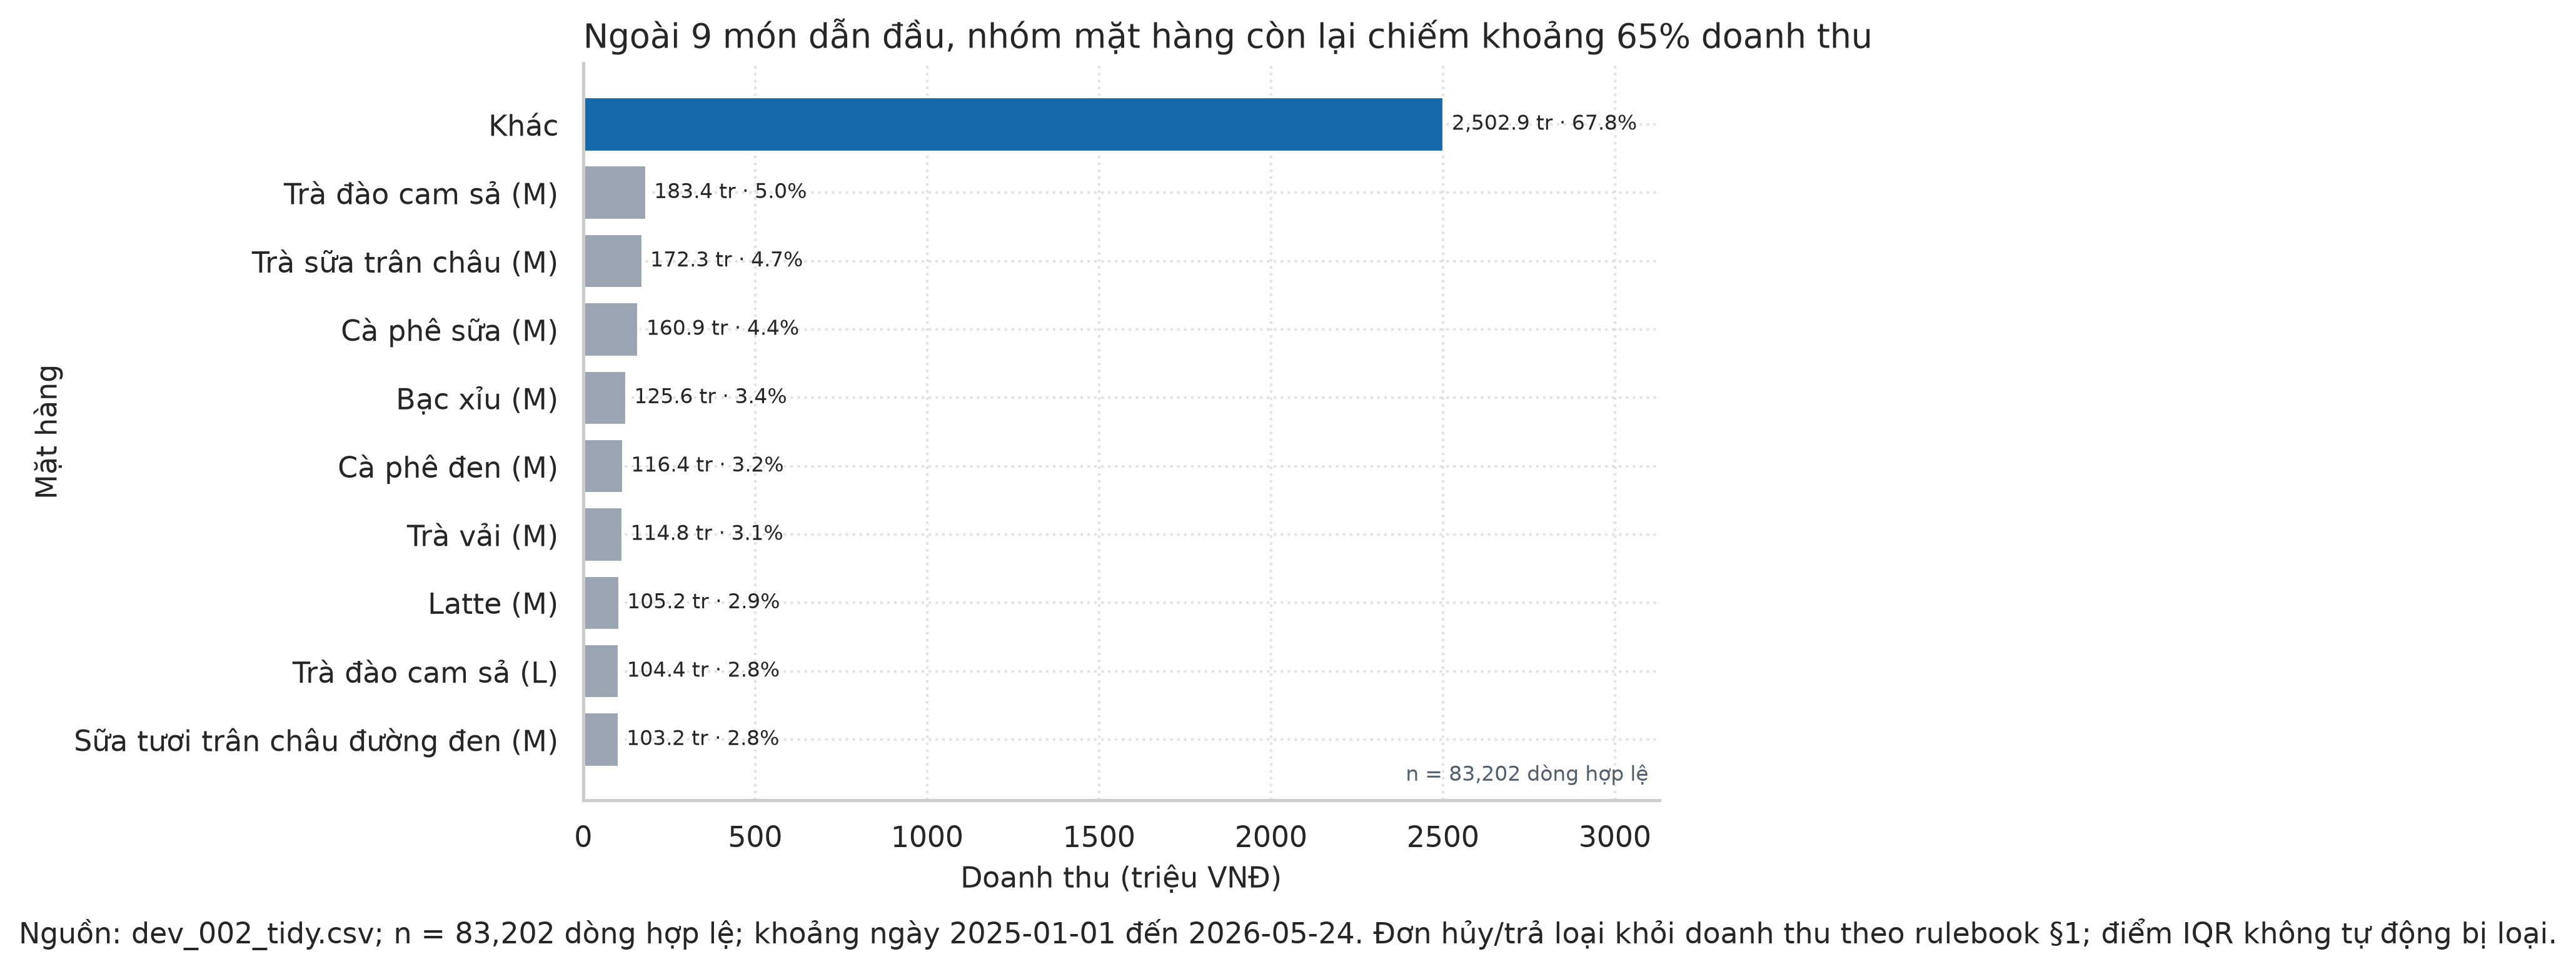

dev_006 — t23b_dev_006_explanatory.png


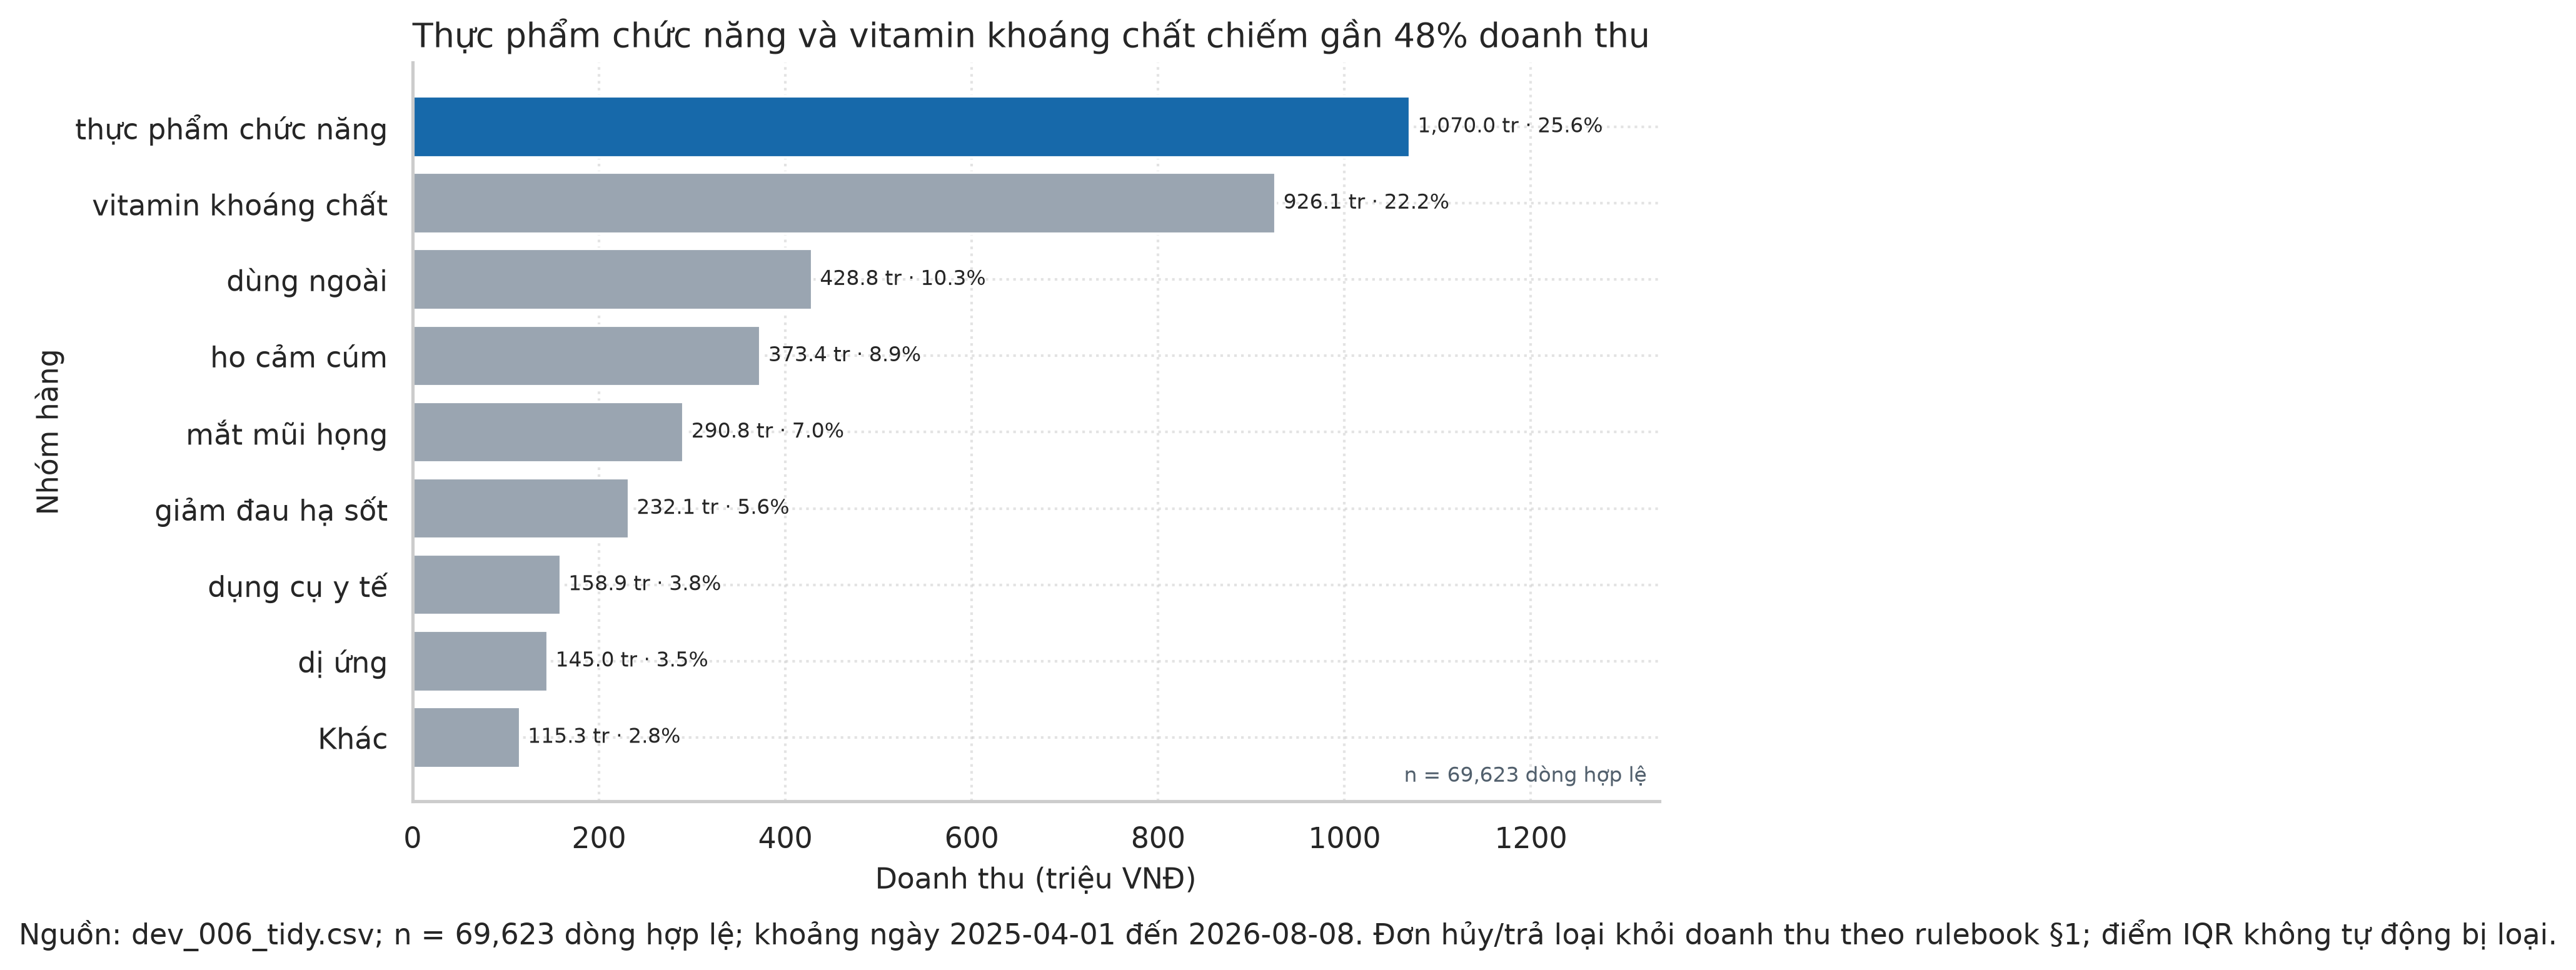

dev_007 — t23b_dev_007_explanatory.png


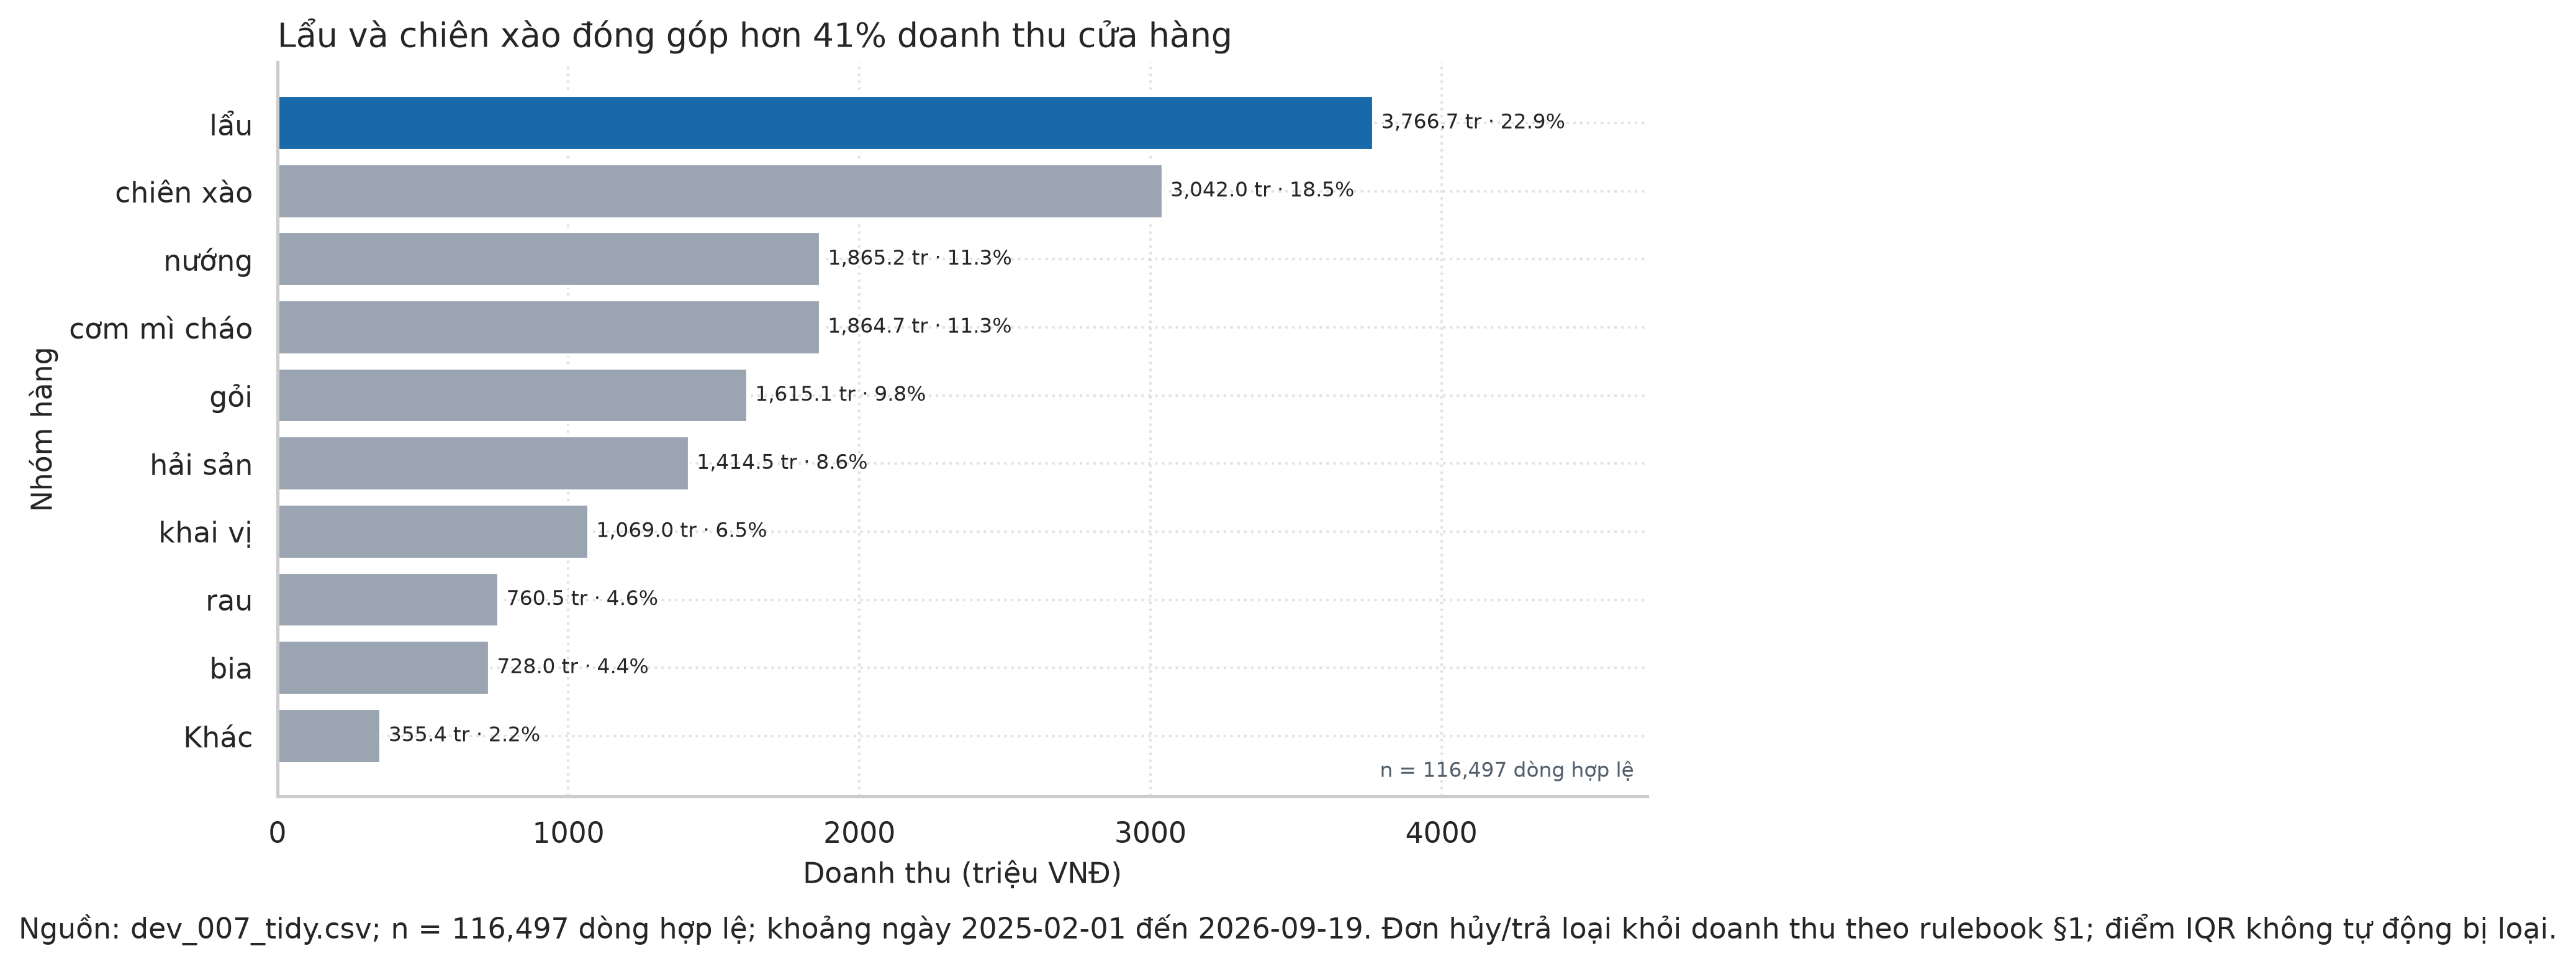

dev_009 — t23b_dev_009_explanatory.png


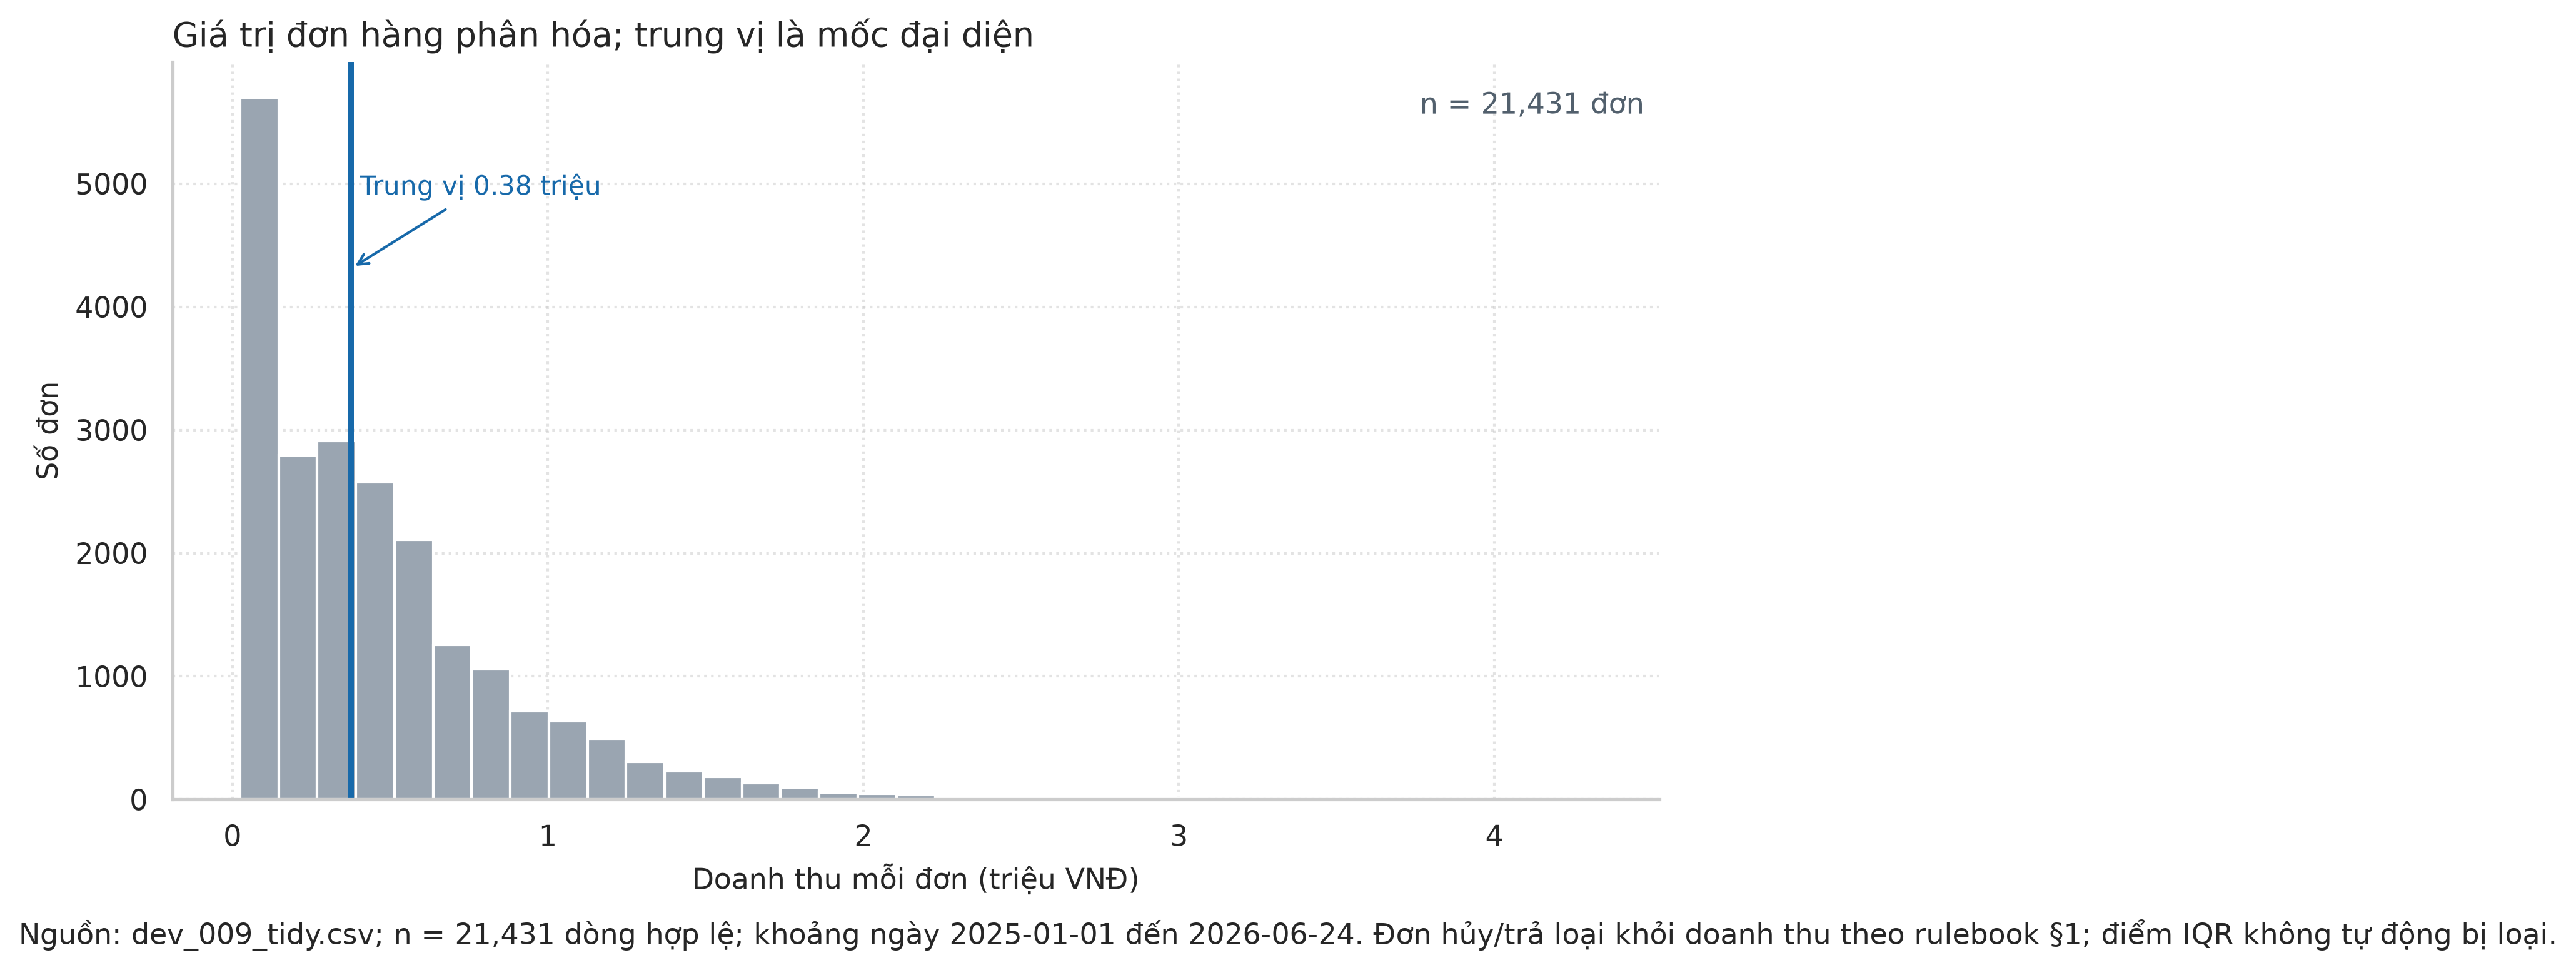

dev_011 — t23b_dev_011_explanatory.png


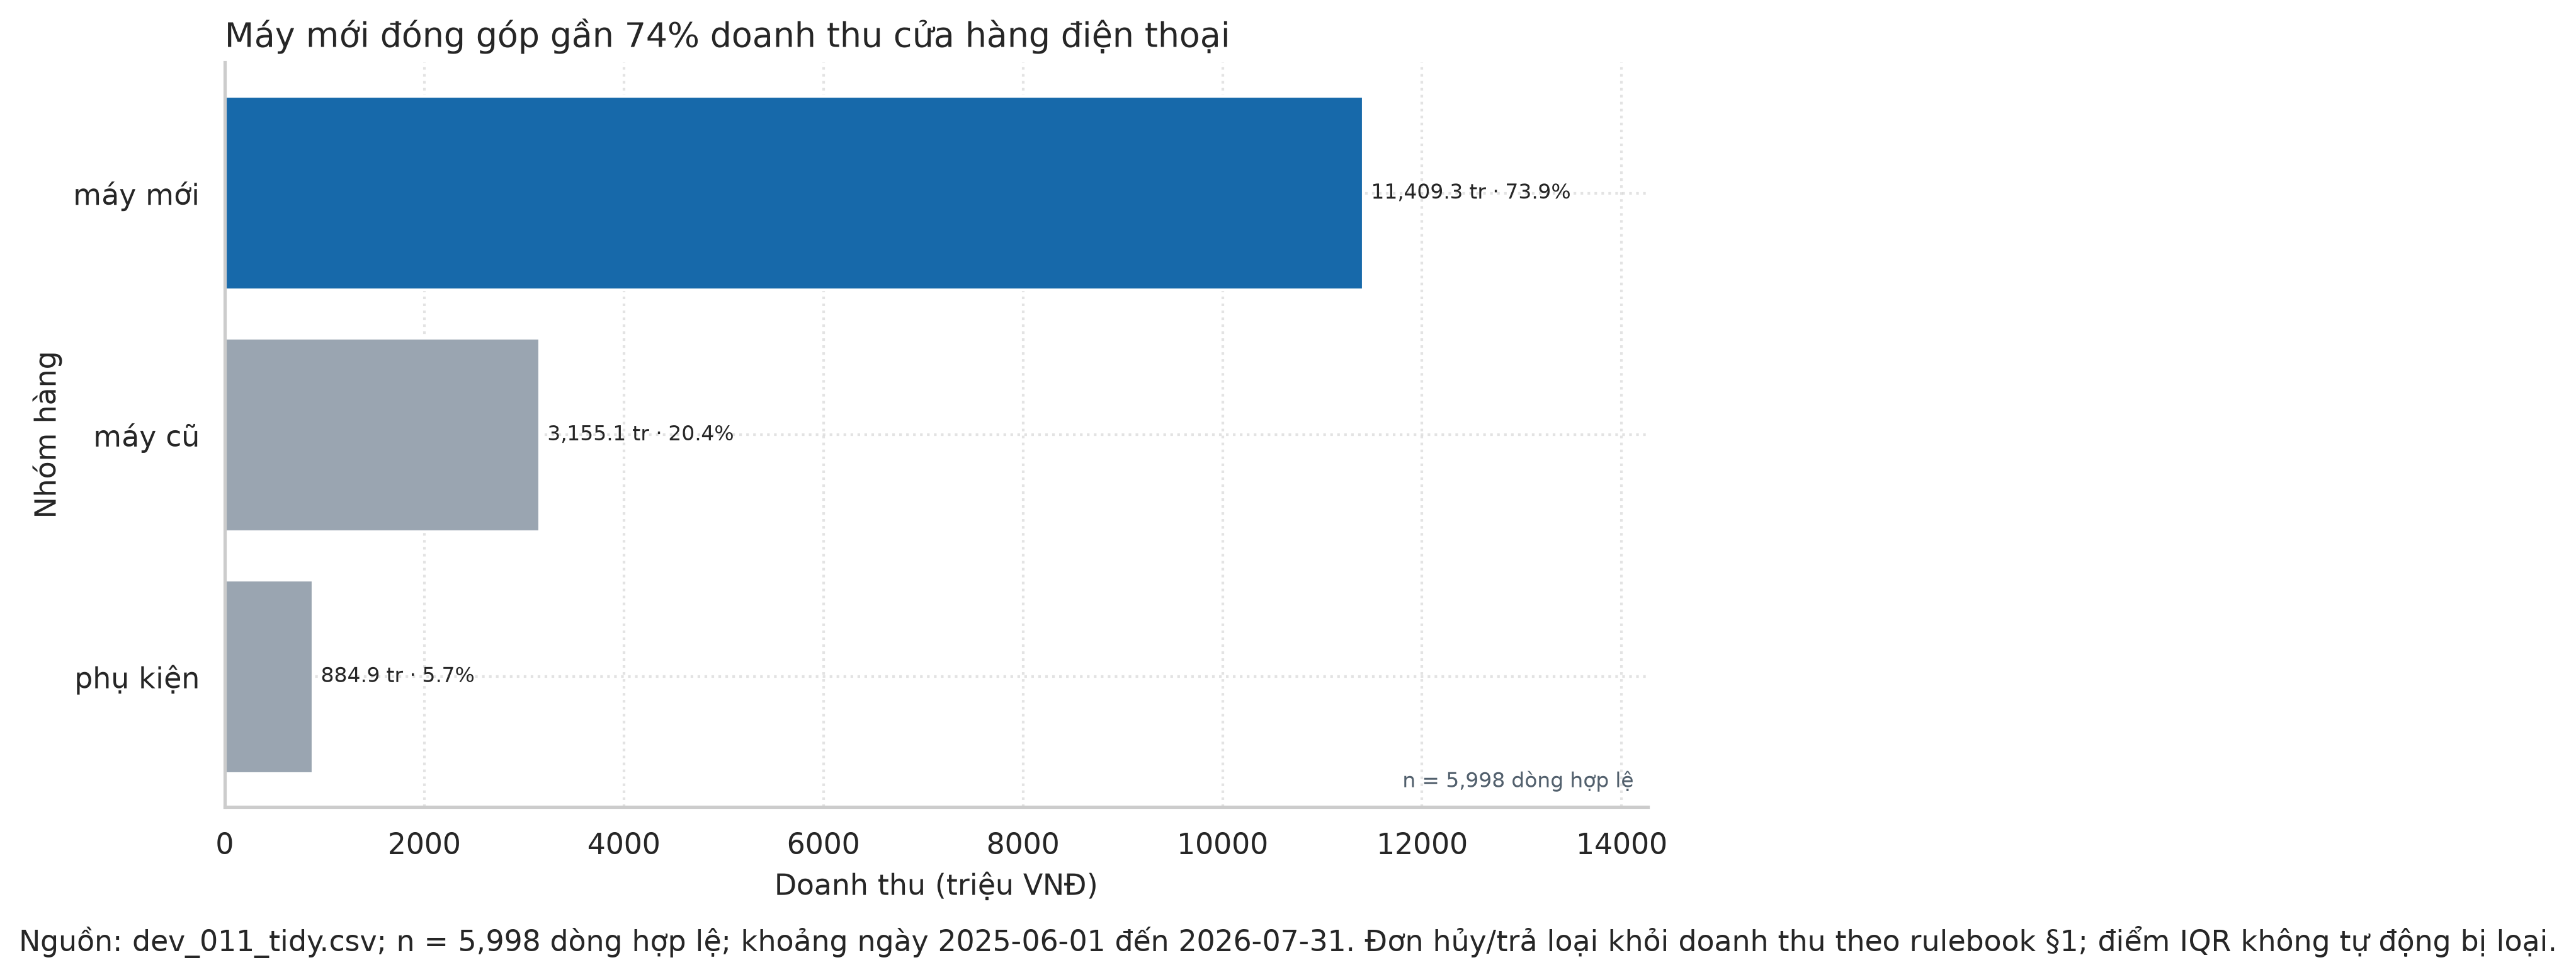

dev_012 — t23b_dev_012_explanatory.png


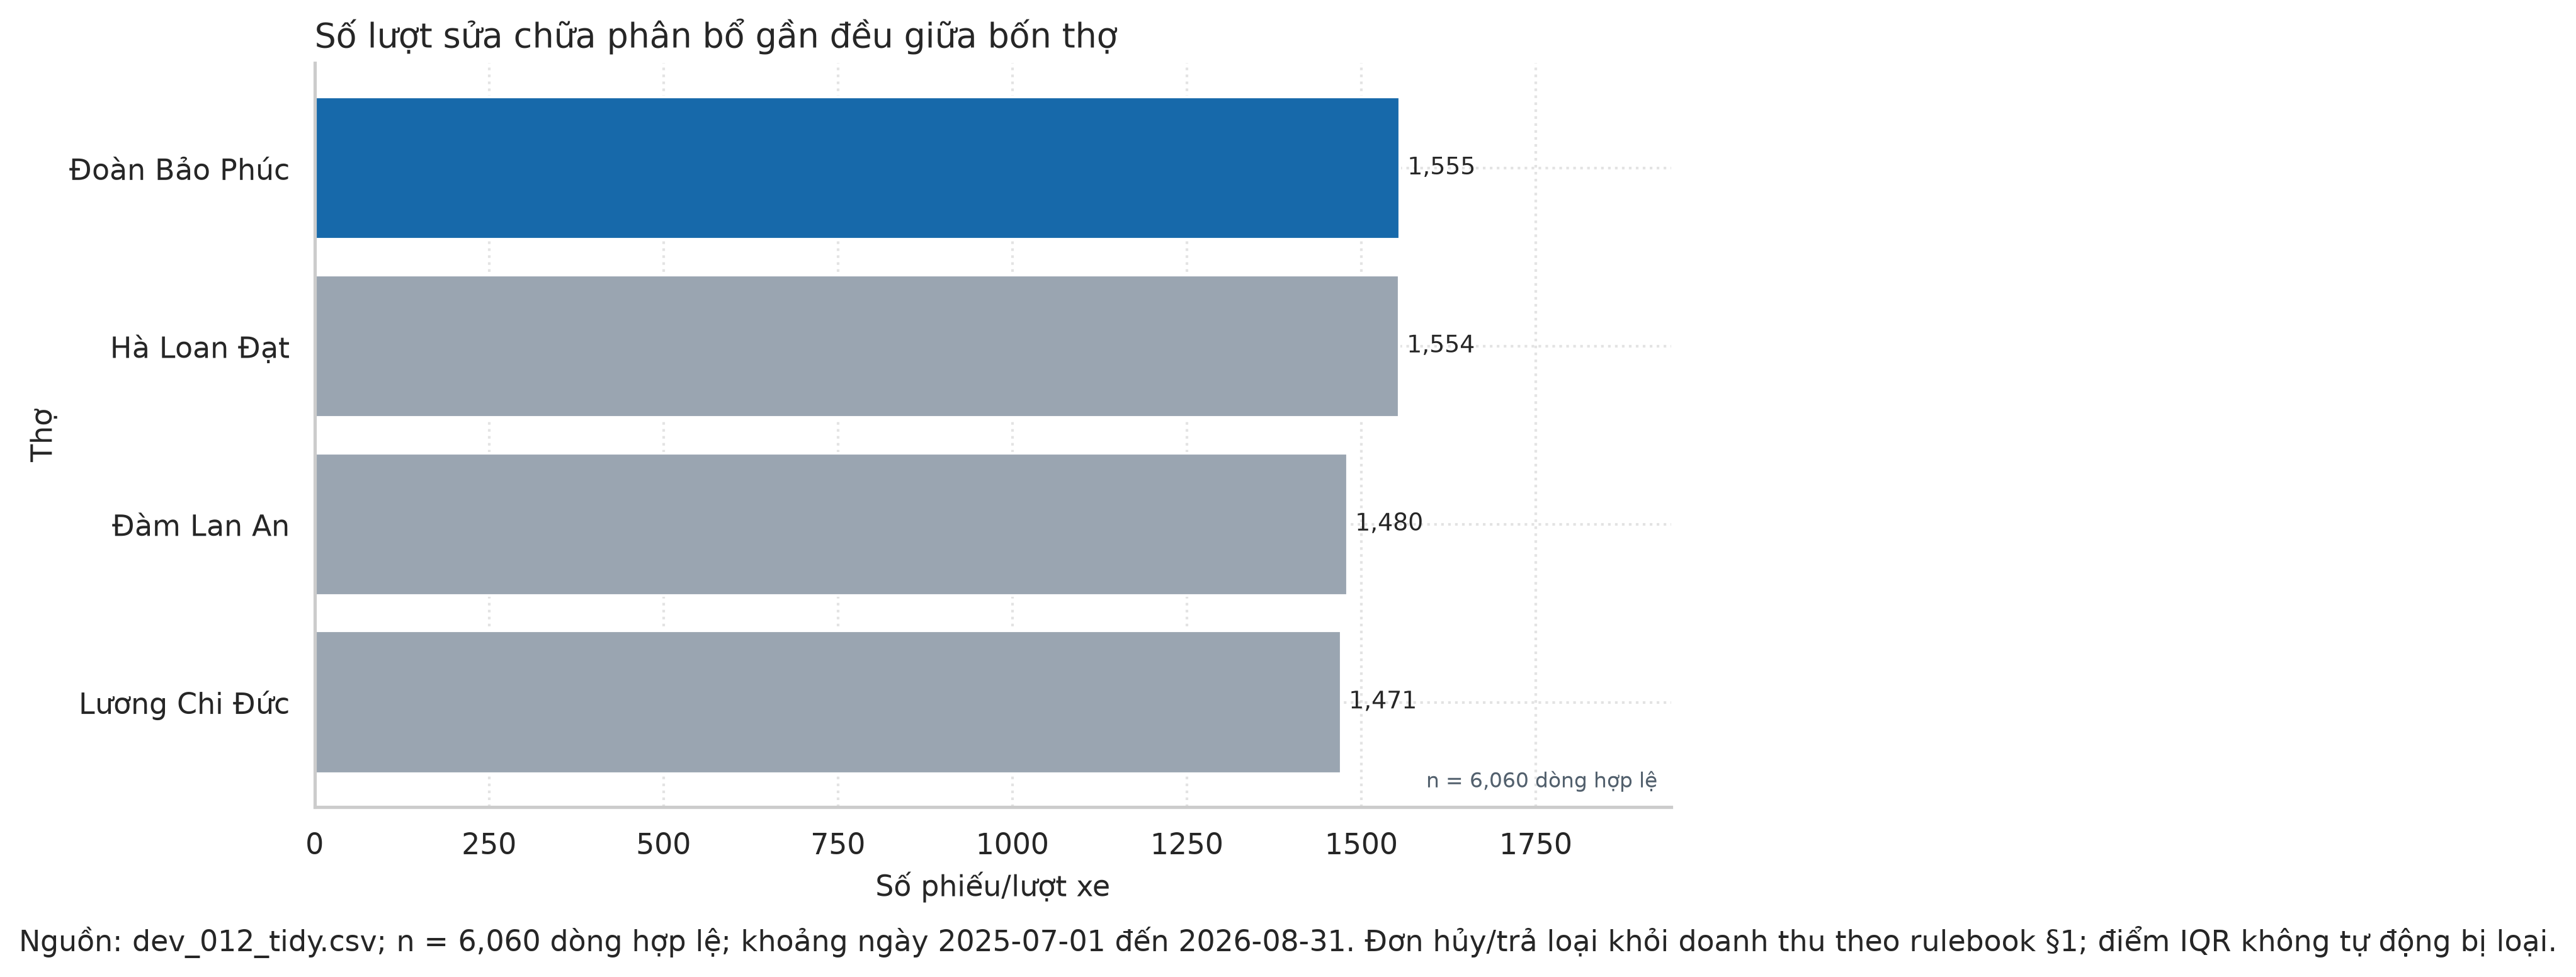

In [37]:
# T2.3b — Trực quan hóa: trình bày bộ biểu đồ giải thích Hồi 2
from IPython.display import display, Image
for b, path in EXPLANATORY_FIGURES.items():
    print(b, "—", Path(path).name)
    display(Image(filename=path))


### Kết quả & Nhận định

- **Thông điệp Hồi 2:** Doanh thu cà phê (`dev_002`) phân tán trên nhiều món; nhà thuốc (`dev_006`) có hai nhóm lớn chiếm gần một nửa doanh thu; F&B (`dev_007`) nổi bật ở lẩu và chiên xào; cửa hàng điện thoại (`dev_011`) phụ thuộc chủ yếu vào máy mới; số lượt sửa xe (`dev_012`) phân bổ tương đối đồng đều giữa bốn thợ. `dev_009` được kể bằng phân phối giá trị đơn do dữ liệu chỉ có grain cấp đơn.
- **Biểu đồ giải thích đã lưu trong `PHASE2_FIGURES_DIR`:**
  - `t23b_dev_002_explanatory.png`
  - `t23b_dev_006_explanatory.png`
  - `t23b_dev_007_explanatory.png`
  - `t23b_dev_009_explanatory.png`
  - `t23b_dev_011_explanatory.png`
  - `t23b_dev_012_explanatory.png`
- **Kiểm soát thiết kế:** Biểu đồ dùng nền xám và màu nhấn cho thông tin chính, tiêu đề chủ động, nhãn trực tiếp, đơn vị, cỡ mẫu, khoảng ngày và nguồn. Các biểu đồ cột bắt đầu từ 0; không dùng 3D hoặc hai trục tung.
- **Giới hạn:** Không có dữ liệu khách hàng/thanh toán/ca/lô trong schema đang dùng; `dev_009` không có chi tiết hàng; phiếu sửa xe có thể ghi nhiều công việc trong một ô. Ngoại lệ IQR chỉ là điểm cần đối chiếu, không tự động loại bỏ.
- **Bàn giao:** `tables/explanatory_chart_audit.csv` ghi lại nguồn, grain, cỡ mẫu và giới hạn của từng hình.


## 05. Tổng kết giai đoạn & Bàn giao

- [x] `T2.1`: Chốt danh sách tập doanh nghiệp đại diện -> `tables/representative_selection.csv`.
- [x] `T2.2a`: Xây dựng và kiểm chứng logic tính chỉ số theo `rulebook.md`.
- [x] `T2.2b`: Chuẩn hóa đơn vị cơ bản, giải mã `Ghi tắt`, xuất bảng Tidy -> `tidy_data/<business_id>_tidy.csv`.
- [x] `T2.2c`: Hoàn thành kiểm tra thiếu dữ liệu, trùng lặp, tính hợp lệ và ngoại lệ IQR -> `tables/quality_and_iqr_report.csv`.
- [x] `T2.3a`: Khám phá nội tại và lưu `tables/business_findings_summary.csv`.
- [x] `T2.3b`: Tinh chỉnh 6 biểu đồ giải thích Hồi 2 -> `figures/t23b_*.png`.

**Các phát hiện chính:** Cơ cấu doanh thu khác nhau theo ngành; `dev_011` nổi bật ở doanh thu máy mới, `dev_006` ở thực phẩm chức năng/vitamin, `dev_007` ở lẩu/chiên xào; `dev_002` có danh mục món phân tán; `dev_012` có lượt sửa chữa phân bổ gần đều giữa bốn thợ. `dev_009` chỉ cho phép phân tích ở cấp đơn.

**Vấn đề còn tồn tại / giới hạn:** Một số cột thiếu có cấu trúc do khác grain; chưa có trường khách hàng, thanh toán, ca hoặc lô cho tập đại diện; mô tả công việc sửa xe chưa tách được thành từng dịch vụ. Ngoại lệ IQR chưa được xác minh từng giao dịch nên được giữ nguyên.

**Đầu ra bàn giao cho Giai đoạn 3 và 4:**
- `artifacts/guided_eda/phase2_business_eda/tidy_data/`
- `artifacts/guided_eda/phase2_business_eda/tables/`
- `artifacts/guided_eda/phase2_business_eda/figures/`
